# Data 4 — Bovine Collagen Gelation: Master Analysis Pipeline
## Phases A through W | All 20 Excel Files | Complete Analysis

**Dataset:** Bovine collagen gelation at three concentrations (0.8%, 1.5%, 2.3% w/v) at 37 degrees Celsius  
**Files:** 20 Excel files — tiempo (time sweep) and frecuencia (frequency sweep) per replicate  
**Project:** Wavelet-Based Time-Frequency Analysis Pipeline — Haemograph Pty Ltd  
**Industry Partner:** Dr Ragil Krishna, Haemograph Pty Ltd  

### Scope Note
This dataset contains processed G(t) and G(t) at approximately 1 Hz — not raw stress-strain waveforms.  
Phases requiring raw waveforms (full FFT pipeline, CWT on raw signal, harmonic detection from raw oscillatory signal)  
will be applied to Data 1, 2, 3, and 6 in separate notebooks.  
This notebook focuses on what this dataset can contribute:  
gelation physics extraction, gel point detection, mutation number estimation,  
concentration-dependent kinetics, and comparative signal analysis methods  
that can be applied to the processed signals available here.

## PHASE A — Data Integrity and Experimental Validation

In [6]:
# ==========================================
# CELL A1: All Imports
# ==========================================

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
import os
import warnings
from scipy import stats
from scipy.signal import butter, filtfilt, stft, windows, find_peaks
from scipy.stats import pearsonr, spearmanr
from scipy.interpolate import interp1d
import statsmodels
from statsmodels.tsa.stattools import adfuller, kpss
warnings.filterwarnings('ignore')

#import sys
#!{sys.executable} -m pip install matplotlib scipy statsmodels openpyxl jupyter nbformat pycwt

matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['font.size'] = 10

print("All imports successful.")
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)

All imports successful.
numpy version: 2.4.4
pandas version: 3.0.2


In [7]:
# ==========================================
# CELL A2: Load All 20 Excel Files
# ==========================================

# SET YOUR DATA FOLDER PATH HERE
DATA_FOLDER_PATH = "/Users/riamishra/Desktop/MAST90106/code/Data4"

TIME_SWEEP_COLUMNS = [
    'meas_pts',
    'shear_stress_Pa',
    'angular_freq_rad_s',
    'storage_modulus_Pa',
    'strain_pct',
    'complex_viscosity_Pa_s',
    'loss_modulus_Pa',
    'temperature_C'
]

FREQUENCY_SWEEP_COLUMNS = [
    'meas_pts',
    'angular_freq_rad_s',
    'storage_modulus_Pa',
    'loss_modulus_Pa',
    'temperature_C'
]

EXPECTED_COLUMN_COUNTS = {
    'time_sweep': 8,
    'frequency_sweep': 5
}

MEASUREMENT_PERIOD_SECONDS = 1.0 / 1.0  # 1 second period at 1 Hz (6.28 rad/s)
MUTATION_NUMBER_THRESHOLD = 0.15         # Mours and Winter 1994

data_dictionary = {}
load_errors = []

all_valid_file_names = sorted([
    file_name for file_name in os.listdir(DATA_FOLDER_PATH)
    if file_name.endswith('.xlsx') and not file_name.startswith('~$')
])

print(f"Found {len(all_valid_file_names)} Excel files:")
for file_name in all_valid_file_names:
    print(f"  {file_name}")

for file_name in all_valid_file_names:
    name_parts = file_name.replace('.xlsx', '').split('_')
    if len(name_parts) < 5:
        print(f"Skipping unexpected filename format: {file_name}")
        continue

    concentration_key = name_parts[2]
    replicate_key     = name_parts[3]
    data_type_key     = (name_parts[4]
                         .replace('tiempo', 'time_sweep')
                         .replace('frecuencia', 'frequency_sweep'))

    if concentration_key not in data_dictionary:
        data_dictionary[concentration_key] = {}
    if replicate_key not in data_dictionary[concentration_key]:
        data_dictionary[concentration_key][replicate_key] = {}

    full_file_path = os.path.join(DATA_FOLDER_PATH, file_name)

    try:
        loaded_dataframe = pd.read_excel(
            full_file_path, header=3, skiprows=[4], engine='openpyxl'
        )
        expected_column_count = EXPECTED_COLUMN_COUNTS[data_type_key]
        loaded_dataframe = loaded_dataframe.iloc[:, :expected_column_count]
        if data_type_key == 'time_sweep':
            loaded_dataframe.columns = TIME_SWEEP_COLUMNS
        else:
            loaded_dataframe.columns = FREQUENCY_SWEEP_COLUMNS
        for column_name in loaded_dataframe.columns:
            loaded_dataframe[column_name] = pd.to_numeric(
                loaded_dataframe[column_name], errors='coerce'
            )
        loaded_dataframe = loaded_dataframe.dropna(
            subset=['meas_pts']
        ).reset_index(drop=True)
        data_dictionary[concentration_key][replicate_key][data_type_key] = loaded_dataframe
    except Exception as error_message:
        load_errors.append((file_name, str(error_message)))
        print(f"Error loading {file_name}: {error_message}")

print(f"\nLoaded concentrations: {sorted(data_dictionary.keys())}")
for concentration_key in sorted(data_dictionary):
    print(f"\nConcentration {concentration_key}%:")
    for replicate_key in sorted(data_dictionary[concentration_key]):
        available_data_types = list(data_dictionary[concentration_key][replicate_key].keys())
        print(f"  Replicate {replicate_key}: {available_data_types}")

if load_errors:
    print(f"\nLoad errors: {load_errors}")
else:
    print("\nAll files loaded successfully.")

Found 20 Excel files:
  Colageno_bov_0.8_1_frecuencia.xlsx
  Colageno_bov_0.8_1_tiempo.xlsx
  Colageno_bov_0.8_2_frecuencia.xlsx
  Colageno_bov_0.8_2_tiempo.xlsx
  Colageno_bov_0.8_3_frecuencia.xlsx
  Colageno_bov_0.8_3_tiempo.xlsx
  Colageno_bov_0.8_4_frecuencia.xlsx
  Colageno_bov_0.8_4_tiempo.xlsx
  Colageno_bov_1.5_1_frecuencia.xlsx
  Colageno_bov_1.5_1_tiempo.xlsx
  Colageno_bov_1.5_2_frecuencia.xlsx
  Colageno_bov_1.5_2_tiempo.xlsx
  Colageno_bov_1.5_3_frecuencia.xlsx
  Colageno_bov_1.5_3_tiempo.xlsx
  Colageno_bov_2.3_1_frecuencia.xlsx
  Colageno_bov_2.3_1_tiempo.xlsx
  Colageno_bov_2.3_2_frecuencia.xlsx
  Colageno_bov_2.3_2_tiempo.xlsx
  Colageno_bov_2.3_3_frecuencia.xlsx
  Colageno_bov_2.3_3_tiempo.xlsx

Loaded concentrations: ['0.8', '1.5', '2.3']

Concentration 0.8%:
  Replicate 1: ['frequency_sweep', 'time_sweep']
  Replicate 2: ['frequency_sweep', 'time_sweep']
  Replicate 3: ['frequency_sweep', 'time_sweep']
  Replicate 4: ['frequency_sweep', 'time_sweep']

Concentration 

In [8]:
# ==========================================
# CELL A3: File Completeness and Shape Validation
# ==========================================

print("=" * 70)
print("FILE COMPLETENESS CHECK")
print("=" * 70)

expected_data_types = {'time_sweep', 'frequency_sweep'}
all_files_complete = True
completeness_records = []

for concentration_key in sorted(data_dictionary):
    for replicate_key in sorted(data_dictionary[concentration_key]):
        available_types = set(data_dictionary[concentration_key][replicate_key].keys())
        missing_types = expected_data_types - available_types
        status_label = "COMPLETE" if not missing_types else f"MISSING: {missing_types}"
        completeness_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'Time Sweep': 'YES' if 'time_sweep' in available_types else 'NO',
            'Frequency Sweep': 'YES' if 'frequency_sweep' in available_types else 'NO',
            'Status': status_label
        })
        if missing_types:
            all_files_complete = False

completeness_dataframe = pd.DataFrame(completeness_records)
print(completeness_dataframe.to_string(index=False))

print("\n" + "=" * 70)
print("SHAPE VALIDATION")
print("=" * 70)
print(f"{'Conc':>6} {'Rep':>4} {'Data Type':>16} {'Rows':>6} {'Cols':>6} {'Status':>10}")
print("-" * 55)

for concentration_key in sorted(data_dictionary):
    for replicate_key in sorted(data_dictionary[concentration_key]):
        for data_type_key in sorted(data_dictionary[concentration_key][replicate_key]):
            current_dataframe = data_dictionary[concentration_key][replicate_key][data_type_key]
            row_count    = current_dataframe.shape[0]
            column_count = current_dataframe.shape[1]
            shape_status = "OK" if row_count > 0 else "EMPTY"
            print(f"{concentration_key:>6} {replicate_key:>4} {data_type_key:>16} {row_count:>6} {column_count:>6} {shape_status:>10}")

FILE COMPLETENESS CHECK
Concentration Replicate Time Sweep Frequency Sweep   Status
          0.8         1        YES             YES COMPLETE
          0.8         2        YES             YES COMPLETE
          0.8         3        YES             YES COMPLETE
          0.8         4        YES             YES COMPLETE
          1.5         1        YES             YES COMPLETE
          1.5         2        YES             YES COMPLETE
          1.5         3        YES             YES COMPLETE
          2.3         1        YES             YES COMPLETE
          2.3         2        YES             YES COMPLETE
          2.3         3        YES             YES COMPLETE

SHAPE VALIDATION
  Conc  Rep        Data Type   Rows   Cols     Status
-------------------------------------------------------
   0.8    1  frequency_sweep     21      5         OK
   0.8    1       time_sweep     45      8         OK
   0.8    2  frequency_sweep     21      5         OK
   0.8    2       time_swe

In [9]:
# ==========================================
# CELL A4: Unit Consistency and Range Check
# ==========================================

print("=" * 70)
print("UNIT AND RANGE CONSISTENCY CHECK")
print("=" * 70)
print(f"{'Conc':>6} {'Rep':>4} {'Freq (rad/s)':>14} {'Freq OK':>8} {'Temp Min':>10} {'Temp Max':>10} {'Temp OK':>8}")
print("-" * 65)

for concentration_key in sorted(data_dictionary):
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        unique_frequencies = time_sweep_df['angular_freq_rad_s'].unique()
        temperature_minimum = time_sweep_df['temperature_C'].min()
        temperature_maximum = time_sweep_df['temperature_C'].max()
        frequency_is_valid  = all(abs(freq - 6.28) < 0.1 for freq in unique_frequencies)
        temperature_is_valid = (36.0 < temperature_minimum) and (temperature_maximum < 39.0)
        print(f"{concentration_key:>6} {replicate_key:>4} {unique_frequencies[0]:>14.2f}"
              f" {'PASS' if frequency_is_valid else 'FAIL':>8}"
              f" {temperature_minimum:>10.1f} {temperature_maximum:>10.1f}"
              f" {'PASS' if temperature_is_valid else 'FAIL':>8}")

print("\nExpected: angular frequency = 6.28 rad/s (1 Hz), temperature = 36 to 39 degrees C")

UNIT AND RANGE CONSISTENCY CHECK
  Conc  Rep   Freq (rad/s)  Freq OK   Temp Min   Temp Max  Temp OK
-----------------------------------------------------------------
   0.8    1           6.28     PASS       37.0       37.2     PASS
   0.8    2           6.28     PASS       37.0       37.2     PASS
   0.8    3           6.28     PASS       37.0       37.1     PASS
   0.8    4           6.28     PASS       37.0       37.1     PASS
   1.5    1           6.28     PASS       37.0       37.2     PASS
   1.5    2           6.28     PASS       37.0       37.1     PASS
   1.5    3           6.28     PASS       37.0       37.1     PASS
   2.3    1           6.28     PASS       37.0       37.2     PASS
   2.3    2           6.28     PASS       37.0       37.1     PASS
   2.3    3           6.28     PASS       37.0       37.1     PASS

Expected: angular frequency = 6.28 rad/s (1 Hz), temperature = 36 to 39 degrees C


In [10]:
# ==========================================
# CELL A5: NaN Audit and Signal Length Consistency
# ==========================================

print("=" * 70)
print("NaN AUDIT ACROSS ALL FILES")
print("=" * 70)

nan_audit_records = []
any_nan_found = False

for concentration_key in sorted(data_dictionary):
    for replicate_key in sorted(data_dictionary[concentration_key]):
        for data_type_key in sorted(data_dictionary[concentration_key][replicate_key]):
            current_df = data_dictionary[concentration_key][replicate_key][data_type_key]
            total_nan_count = current_df.isnull().sum().sum()
            nan_audit_records.append({
                'Concentration': concentration_key,
                'Replicate': replicate_key,
                'Data Type': data_type_key,
                'NaN Count': total_nan_count,
                'Status': 'OK' if total_nan_count == 0 else 'CONTAINS NaN'
            })
            if total_nan_count > 0:
                any_nan_found = True

nan_audit_df = pd.DataFrame(nan_audit_records)
print(nan_audit_df.to_string(index=False))

if not any_nan_found:
    print("\nNo NaN values found in any dataset.")
else:
    print("\nNaN values detected — review files flagged above.")

print("\n" + "=" * 70)
print("SIGNAL LENGTH CONSISTENCY")
print("=" * 70)

for concentration_key in sorted(data_dictionary):
    time_sweep_lengths = []
    freq_sweep_lengths = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' in data_dictionary[concentration_key][replicate_key]:
            time_sweep_lengths.append(
                len(data_dictionary[concentration_key][replicate_key]['time_sweep'])
            )
        if 'frequency_sweep' in data_dictionary[concentration_key][replicate_key]:
            freq_sweep_lengths.append(
                len(data_dictionary[concentration_key][replicate_key]['frequency_sweep'])
            )
    print(f"Concentration {concentration_key}%: "
          f"time_sweep lengths = {time_sweep_lengths}, "
          f"frequency_sweep lengths = {freq_sweep_lengths}")

NaN AUDIT ACROSS ALL FILES
Concentration Replicate       Data Type  NaN Count Status
          0.8         1 frequency_sweep          0     OK
          0.8         1      time_sweep          0     OK
          0.8         2 frequency_sweep          0     OK
          0.8         2      time_sweep          0     OK
          0.8         3 frequency_sweep          0     OK
          0.8         3      time_sweep          0     OK
          0.8         4 frequency_sweep          0     OK
          0.8         4      time_sweep          0     OK
          1.5         1 frequency_sweep          0     OK
          1.5         1      time_sweep          0     OK
          1.5         2 frequency_sweep          0     OK
          1.5         2      time_sweep          0     OK
          1.5         3 frequency_sweep          0     OK
          1.5         3      time_sweep          0     OK
          2.3         1 frequency_sweep          0     OK
          2.3         1      time_sweep      

## PHASE B — Advanced Signal Diagnostics

In [11]:
# ==========================================
# CELL B1: Stationarity Testing — ADF and KPSS on G'(t)
# ==========================================
# ADF (Augmented Dickey-Fuller): H0 = non-stationary. p < 0.05 means stationary.
# KPSS (Kwiatkowski-Phillips-Schmidt-Shin): H0 = stationary. p < 0.05 means non-stationary.
# For gelating G'(t): expect NON-stationary since modulus rises over time.
# Non-stationarity is the quantitative justification for why Fourier fails.

print("=" * 70)
print("STATIONARITY TESTING ON STORAGE MODULUS G'(t)")
print("=" * 70)
print(f"{'Conc':>6} {'Rep':>4} {'ADF p-value':>12} {'KPSS p-value':>13} {'ADF Verdict':>16} {'Conclusion':>22}")
print("-" * 80)

stationarity_records = []

for concentration_key in sorted(data_dictionary):
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        storage_modulus_signal = (
            data_dictionary[concentration_key][replicate_key]['time_sweep']['storage_modulus_Pa'].values
        )
        adf_test_result = adfuller(storage_modulus_signal, autolag='AIC')
        adf_p_value = adf_test_result[1]
        try:
            kpss_test_result = kpss(storage_modulus_signal, regression='c', nlags='auto')
            kpss_p_value = kpss_test_result[1]
        except Exception:
            kpss_p_value = None
        adf_verdict   = "Stationary" if adf_p_value < 0.05 else "Non-stationary"
        conclusion    = "Fourier FAILS" if adf_p_value >= 0.05 else "Fourier may apply"
        kpss_str      = f"{kpss_p_value:.3f}" if kpss_p_value is not None else "N/A"
        stationarity_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'ADF p-value': round(adf_p_value, 4),
            'KPSS p-value': kpss_str,
            'ADF Verdict': adf_verdict,
            'Conclusion': conclusion
        })
        print(f"{concentration_key:>6} {replicate_key:>4} {adf_p_value:>12.4f} {kpss_str:>13} {adf_verdict:>16} {conclusion:>22}")

stationarity_df = pd.DataFrame(stationarity_records)
print("\nNote: Non-stationary G'(t) means Fourier transform produces averaged, unreliable spectrum.")
print("This is the quantitative basis for requiring wavelet analysis on evolving gel systems.")

STATIONARITY TESTING ON STORAGE MODULUS G'(t)
  Conc  Rep  ADF p-value  KPSS p-value      ADF Verdict             Conclusion
--------------------------------------------------------------------------------
   0.8    1       0.3842         0.010   Non-stationary          Fourier FAILS
   0.8    2       0.6342         0.010   Non-stationary          Fourier FAILS
   0.8    3       0.0116         0.040       Stationary      Fourier may apply
   0.8    4       0.0558         0.010   Non-stationary          Fourier FAILS
   1.5    1       0.0064         0.100       Stationary      Fourier may apply
   1.5    2       0.0003         0.076       Stationary      Fourier may apply
   1.5    3       0.0358         0.015       Stationary      Fourier may apply
   2.3    1       0.0005         0.098       Stationary      Fourier may apply
   2.3    2       0.0000         0.062       Stationary      Fourier may apply
   2.3    3       0.2200         0.100   Non-stationary          Fourier FAILS

Not

In [12]:
# ==========================================
# CELL B2: Signal Drift Detection Across All Concentrations
# ==========================================

print("=" * 70)
print("SIGNAL DRIFT DETECTION — LINEAR TREND IN G'(t)")
print("=" * 70)
print(f"{'Conc':>6} {'Rep':>4} {'Slope (Pa/step)':>16} {'R_squared':>10} {'p-value':>10} {'Drift?':>15}")
print("-" * 68)

drift_records = []

for concentration_key in sorted(data_dictionary):
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        measurement_index = np.arange(len(time_sweep_df))
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        slope, intercept, pearson_r, p_value, std_error = stats.linregress(
            measurement_index, storage_modulus_values
        )
        r_squared = pearson_r ** 2
        drift_detected = "DRIFT (gelation)" if (slope > 0 and p_value < 0.05) else "No drift"
        drift_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'Slope': slope,
            'R_squared': r_squared,
            'p_value': p_value,
            'Drift': drift_detected
        })
        print(f"{concentration_key:>6} {replicate_key:>4} {slope:>16.5f} {r_squared:>10.4f} {p_value:>10.4f} {drift_detected:>15}")

print("\nDrift with positive slope and p < 0.05 confirms gelation is occurring during measurement.")
print("Strong drift = material is far from steady state = Fourier assumption violated.")

SIGNAL DRIFT DETECTION — LINEAR TREND IN G'(t)
  Conc  Rep  Slope (Pa/step)  R_squared    p-value          Drift?
--------------------------------------------------------------------
   0.8    1          0.05320     0.6131     0.0000 DRIFT (gelation)
   0.8    2          0.03789     0.7156     0.0000 DRIFT (gelation)
   0.8    3          0.04307     0.3207     0.0001 DRIFT (gelation)
   0.8    4          0.10816     0.6066     0.0000 DRIFT (gelation)
   1.5    1          0.00975     0.0132     0.4524        No drift
   1.5    2          0.02968     0.1152     0.0225 DRIFT (gelation)
   1.5    3          0.05465     0.4490     0.0000 DRIFT (gelation)
   2.3    1          0.07074     0.1919     0.0026 DRIFT (gelation)
   2.3    2          0.05174     0.1827     0.0034 DRIFT (gelation)
   2.3    3          0.03043     0.0216     0.3353        No drift

Drift with positive slope and p < 0.05 confirms gelation is occurring during measurement.
Strong drift = material is far from steady state

In [13]:
# ==========================================
# CELL B3: Transient Detection — Identifying Anomalous Spikes
# ==========================================

print("=" * 70)
print("TRANSIENT SPIKE DETECTION IN SHEAR STRESS SIGNAL")
print("=" * 70)
print(f"{'Conc':>6} {'Rep':>4} {'Mean (Pa)':>10} {'Std (Pa)':>10} {'Max (Pa)':>10} {'Spike?':>10} {'Spike Index':>12}")
print("-" * 68)

transient_records = []

for concentration_key in sorted(data_dictionary):
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        shear_stress_values = (
            data_dictionary[concentration_key][replicate_key]['time_sweep']['shear_stress_Pa'].values
        )
        signal_mean = np.mean(shear_stress_values)
        signal_std  = np.std(shear_stress_values)
        signal_max  = np.max(shear_stress_values)
        spike_threshold = signal_mean + 3.0 * signal_std
        spike_indices = np.where(shear_stress_values > spike_threshold)[0]
        has_spike = len(spike_indices) > 0
        spike_label = str(spike_indices.tolist()) if has_spike else "None"
        transient_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'Mean': signal_mean,
            'Std': signal_std,
            'Max': signal_max,
            'Has Spike': has_spike
        })
        print(f"{concentration_key:>6} {replicate_key:>4} {signal_mean:>10.4f} {signal_std:>10.4f} {signal_max:>10.4f} {'YES' if has_spike else 'NO':>10} {spike_label:>12}")

transient_df = pd.DataFrame(transient_records)
print("\nSpike detection criterion: signal value exceeds mean + 3 * standard deviation.")

TRANSIENT SPIKE DETECTION IN SHEAR STRESS SIGNAL
  Conc  Rep  Mean (Pa)   Std (Pa)   Max (Pa)     Spike?  Spike Index
--------------------------------------------------------------------
   0.8    1     0.0399     0.0988     0.6910        YES         [19]
   0.8    2     0.0150     0.0094     0.0397         NO         None
   0.8    3     0.0399     0.0103     0.0536         NO         None
   0.8    4     0.0518     0.0188     0.0814         NO         None
   1.5    1     0.1322     0.0144     0.1600         NO         None
   1.5    2     0.1211     0.0092     0.1350         NO         None
   1.5    3     0.1907     0.0177     0.2160         NO         None
   2.3    1     0.2549     0.0343     0.3060         NO         None
   2.3    2     0.6406     0.0416     0.6970         NO         None
   2.3    3     0.6595     0.0390     0.7150         NO         None

Spike detection criterion: signal value exceeds mean + 3 * standard deviation.


In [14]:
# ==========================================
# CELL B4: Mutation Onset Detection — When Does Gelation Begin?
# ==========================================

print("=" * 70)
print("MUTATION ONSET DETECTION — FIRST POINT WHERE G' RISES ABOVE BASELINE")
print("=" * 70)

onset_by_concentration = {}

for concentration_key in sorted(data_dictionary):
    onset_by_concentration[concentration_key] = []
    print(f"\nConcentration {concentration_key}%:")
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        storage_modulus_values = (
            data_dictionary[concentration_key][replicate_key]['time_sweep']['storage_modulus_Pa'].values
        )
        baseline_mean = np.mean(storage_modulus_values[:5])
        baseline_std  = np.std(storage_modulus_values[:5])
        onset_threshold = baseline_mean + 3.0 * baseline_std
        onset_index = None
        for index, value in enumerate(storage_modulus_values):
            if value > onset_threshold:
                onset_index = index
                break
        onset_by_concentration[concentration_key].append(onset_index)
        print(f"  Replicate {replicate_key}: baseline G' = {baseline_mean:.4f} Pa | "
              f"threshold = {onset_threshold:.4f} Pa | onset at step {onset_index}")

print("\nSummary — Mean onset step per concentration:")
for concentration_key in sorted(onset_by_concentration):
    valid_onsets = [v for v in onset_by_concentration[concentration_key] if v is not None]
    if valid_onsets:
        print(f"  Concentration {concentration_key}%: "
              f"mean onset = {np.mean(valid_onsets):.1f} +/- {np.std(valid_onsets):.1f} steps")
    else:
        print(f"  Concentration {concentration_key}%: onset not detectable (already gelled)")

MUTATION ONSET DETECTION — FIRST POINT WHERE G' RISES ABOVE BASELINE

Concentration 0.8%:
  Replicate 1: baseline G' = 0.6460 Pa | threshold = 1.1266 Pa | onset at step 8
  Replicate 2: baseline G' = 0.6220 Pa | threshold = 0.8179 Pa | onset at step 6
  Replicate 3: baseline G' = 1.6000 Pa | threshold = 3.3283 Pa | onset at step 8
  Replicate 4: baseline G' = 1.6888 Pa | threshold = 4.6207 Pa | onset at step 11

Concentration 1.5%:
  Replicate 1: baseline G' = 11.4400 Pa | threshold = 14.5496 Pa | onset at step 6
  Replicate 2: baseline G' = 9.8800 Pa | threshold = 11.7332 Pa | onset at step 6
  Replicate 3: baseline G' = 18.0600 Pa | threshold = 21.3000 Pa | onset at step 32

Concentration 2.3%:
  Replicate 1: baseline G' = 21.2400 Pa | threshold = 28.5997 Pa | onset at step None
  Replicate 2: baseline G' = 62.2000 Pa | threshold = 69.0411 Pa | onset at step None
  Replicate 3: baseline G' = 53.1400 Pa | threshold = 62.8084 Pa | onset at step 14

Summary — Mean onset step per concent

## PHASE C — Signal Energy and Information Content

In [15]:
# ==========================================
# CELL C1: Shannon Entropy of G'(t) and G''(t) Across All Files
# ==========================================

def compute_shannon_entropy(signal_array):
    cleaned_signal = signal_array[~np.isnan(signal_array)]
    histogram_values, _ = np.histogram(cleaned_signal, bins=10, density=True)
    positive_histogram = histogram_values[histogram_values > 0]
    entropy_value = -np.sum(positive_histogram * np.log2(positive_histogram + 1e-12))
    return entropy_value

print("=" * 70)
print("SHANNON ENTROPY OF G'(t) AND G''(t)")
print("=" * 70)
print(f"{'Conc':>6} {'Rep':>4} {'Entropy G-prime':>16} {'Entropy G-double-prime':>22} {'Interpretation':>30}")
print("-" * 85)

entropy_records = []
entropy_by_concentration = {}

for concentration_key in sorted(data_dictionary):
    entropy_by_concentration[concentration_key] = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        entropy_G_prime       = compute_shannon_entropy(time_sweep_df['storage_modulus_Pa'].values)
        entropy_G_double_prime = compute_shannon_entropy(time_sweep_df['loss_modulus_Pa'].values)
        entropy_by_concentration[concentration_key].append(entropy_G_prime)
        if entropy_G_prime > 2.5:
            interpretation = "High disorder (early gelation)"
        elif entropy_G_prime > 1.5:
            interpretation = "Moderate (transitioning)"
        else:
            interpretation = "Low disorder (plateau gel)"
        entropy_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'Entropy G-prime': entropy_G_prime,
            'Entropy G-double-prime': entropy_G_double_prime
        })
        print(f"{concentration_key:>6} {replicate_key:>4} {entropy_G_prime:>16.4f} {entropy_G_double_prime:>22.4f} {interpretation:>30}")

entropy_df = pd.DataFrame(entropy_records)
print("\nInterpretation: Lower entropy = more ordered = stronger gel = less information content.")
print("Higher entropy = more disordered evolution = gelation transition underway.")

SHANNON ENTROPY OF G'(t) AND G''(t)
  Conc  Rep  Entropy G-prime Entropy G-double-prime                 Interpretation
-------------------------------------------------------------------------------------
   0.8    1           4.2021                 3.3273 High disorder (early gelation)
   0.8    2           4.3183                 1.6711 High disorder (early gelation)
   0.8    3           3.2044                 2.1186 High disorder (early gelation)
   0.8    4           3.4396                 3.9135 High disorder (early gelation)
   1.5    1           3.2591                 4.1320 High disorder (early gelation)
   1.5    2           3.8908                 3.5312 High disorder (early gelation)
   1.5    3           2.5681                 4.1159 High disorder (early gelation)
   2.3    1           2.1794                 3.0689       Moderate (transitioning)
   2.3    2           2.2358                 4.7520       Moderate (transitioning)
   2.3    3           2.0277                 4.3

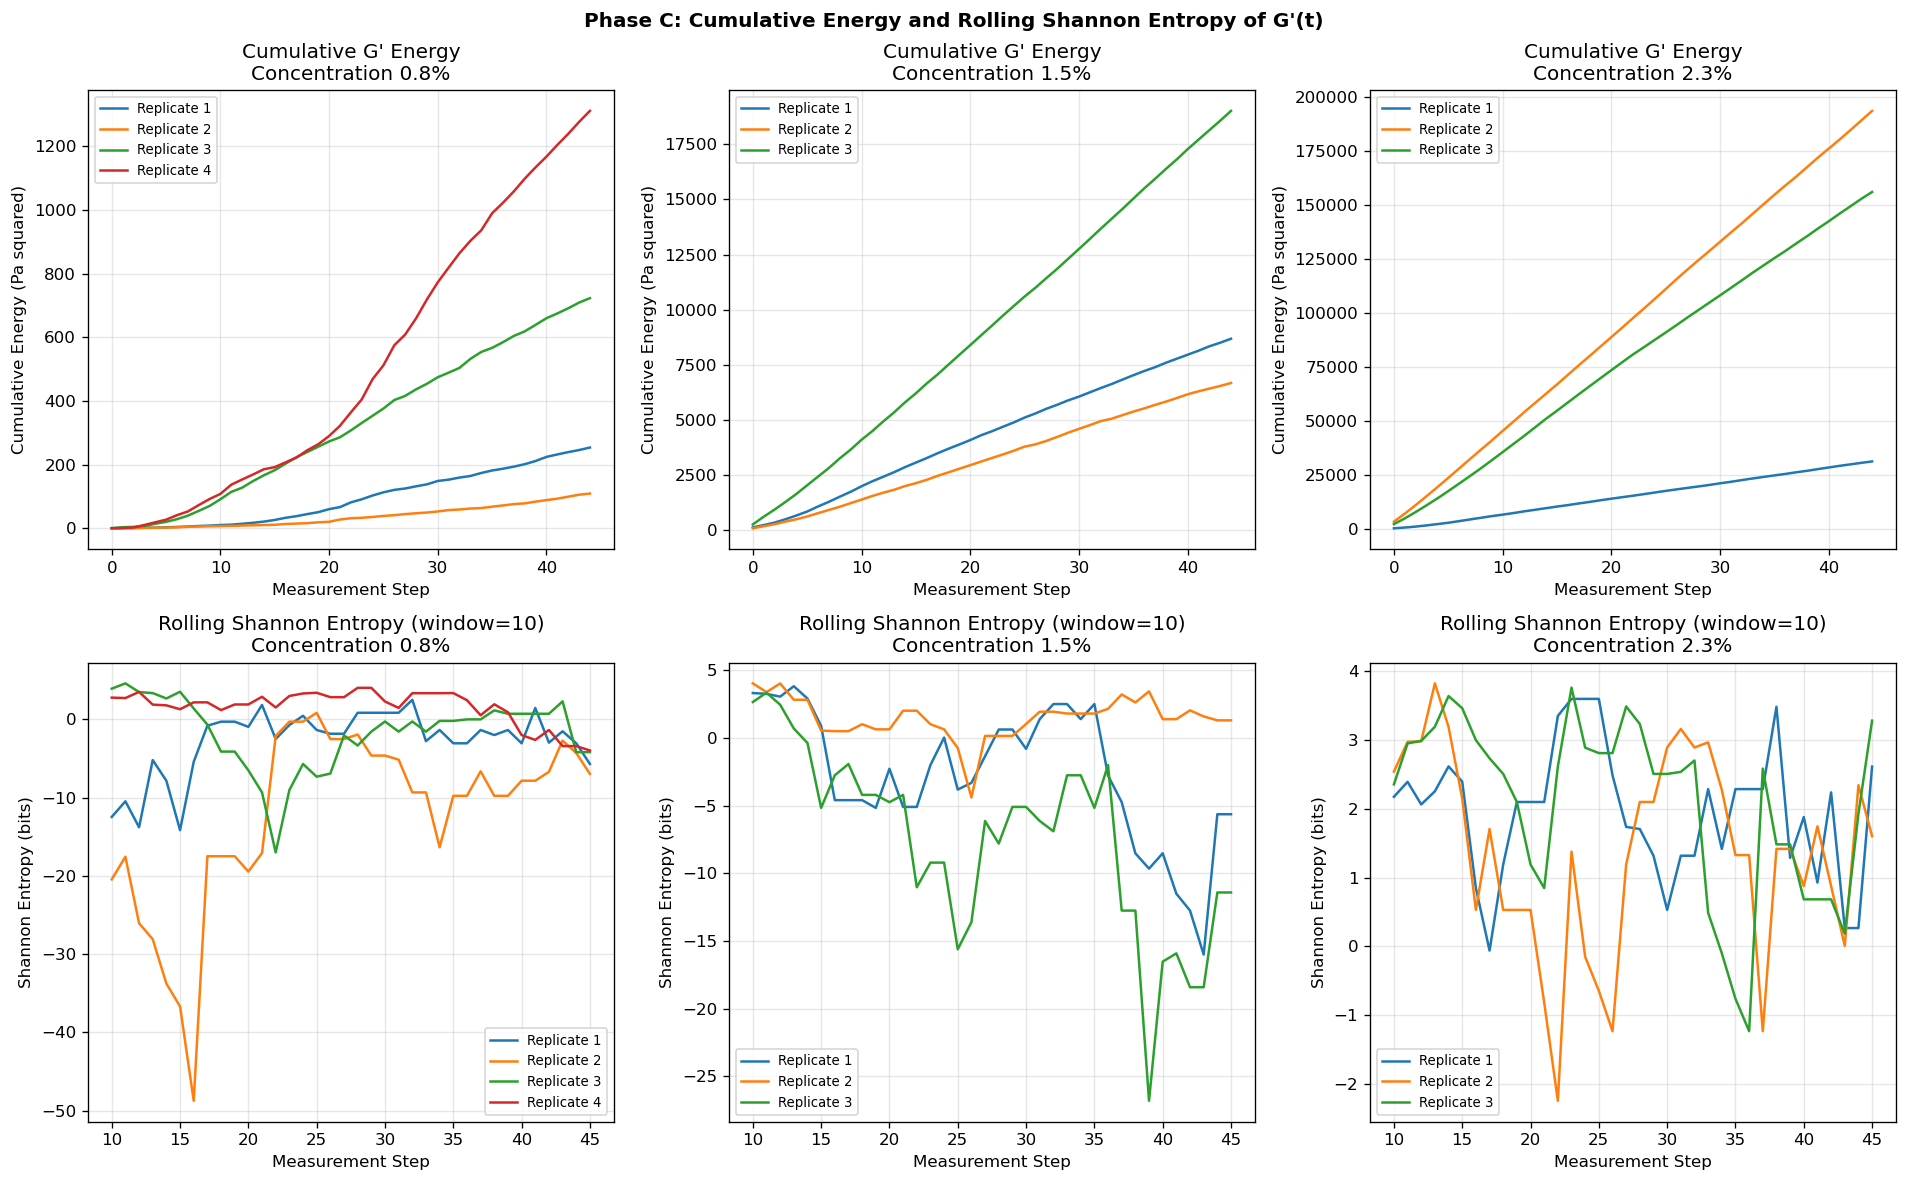

In [16]:
# ==========================================
# CELL C2: Cumulative Energy Evolution and Spectral Entropy
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
concentration_list = sorted(data_dictionary.keys())
color_palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for column_index, concentration_key in enumerate(concentration_list):
    ax_energy  = axes[0, column_index]
    ax_entropy = axes[1, column_index]
    running_entropy_values = []

    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        storage_modulus_values = (
            data_dictionary[concentration_key][replicate_key]['time_sweep']['storage_modulus_Pa'].values
        )
        cumulative_energy = np.cumsum(storage_modulus_values ** 2)
        step_indices = np.arange(len(storage_modulus_values))
        ax_energy.plot(step_indices, cumulative_energy, label=f"Replicate {replicate_key}")
        # rolling entropy in windows of 10
        rolling_entropy = []
        for window_end in range(10, len(storage_modulus_values) + 1):
            window_slice = storage_modulus_values[max(0, window_end - 10):window_end]
            rolling_entropy.append(compute_shannon_entropy(window_slice))
        rolling_entropy_array = np.array(rolling_entropy)
        rolling_indices       = np.arange(10, len(storage_modulus_values) + 1)
        ax_entropy.plot(rolling_indices, rolling_entropy_array, label=f"Replicate {replicate_key}")

    ax_energy.set_title(f"Cumulative G' Energy\nConcentration {concentration_key}%")
    ax_energy.set_xlabel("Measurement Step")
    ax_energy.set_ylabel("Cumulative Energy (Pa squared)")
    ax_energy.legend(fontsize=8)
    ax_energy.grid(True, alpha=0.3)

    ax_entropy.set_title(f"Rolling Shannon Entropy (window=10)\nConcentration {concentration_key}%")
    ax_entropy.set_xlabel("Measurement Step")
    ax_entropy.set_ylabel("Shannon Entropy (bits)")
    ax_entropy.legend(fontsize=8)
    ax_entropy.grid(True, alpha=0.3)

plt.suptitle("Phase C: Cumulative Energy and Rolling Shannon Entropy of G'(t)", fontweight='bold')
plt.tight_layout()
plt.show()

## PHASE D — Noise and Distortion Modeling

In [17]:
# ==========================================
# CELL D1: Noise Floor Estimation — MAD-Based Approach
# ==========================================
# MAD = Median Absolute Deviation — robust to outliers
# Noise floor = 1.4826 * MAD (consistent estimator for Gaussian noise)

def estimate_noise_floor_mad(signal_array):
    signal_median = np.median(signal_array)
    mad_value = np.median(np.abs(signal_array - signal_median))
    noise_floor_estimate = 1.4826 * mad_value
    return noise_floor_estimate

def compute_snr_db(signal_array, noise_floor):
    signal_power = np.var(signal_array)
    noise_power  = noise_floor ** 2
    if noise_power == 0:
        return np.inf
    snr_linear = signal_power / noise_power
    return 10.0 * np.log10(snr_linear + 1e-12)

print("=" * 70)
print("NOISE FLOOR ESTIMATION AND SNR — ALL FILES")
print("=" * 70)
print(f"{'Conc':>6} {'Rep':>4} {'Signal':>10} {'Noise Floor':>12} {'SNR (dB)':>10} {'Quality':>12}")
print("-" * 60)

noise_records = []

for concentration_key in sorted(data_dictionary):
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        shear_stress_values = (
            data_dictionary[concentration_key][replicate_key]['time_sweep']['shear_stress_Pa'].values
        )
        noise_floor_value = estimate_noise_floor_mad(shear_stress_values)
        snr_db_value = compute_snr_db(shear_stress_values, noise_floor_value)
        signal_label = "G' (Pa)"
        quality_label = "High" if snr_db_value > 20 else ("Medium" if snr_db_value > 10 else "Low")
        noise_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'Noise Floor (Pa)': noise_floor_value,
            'SNR (dB)': snr_db_value,
            'Quality': quality_label
        })
        print(f"{concentration_key:>6} {replicate_key:>4} {'shear_stress':>10} {noise_floor_value:>12.6f} {snr_db_value:>10.2f} {quality_label:>12}")

noise_df = pd.DataFrame(noise_records)
print("\nNoise quality: High = SNR > 20 dB, Medium = 10-20 dB, Low = < 10 dB")

NOISE FLOOR ESTIMATION AND SNR — ALL FILES
  Conc  Rep     Signal  Noise Floor   SNR (dB)      Quality
------------------------------------------------------------
   0.8    1 shear_stress     0.009785      20.08         High
   0.8    2 shear_stress     0.010882      -1.28          Low
   0.8    3 shear_stress     0.006523       3.95          Low
   0.8    4 shear_stress     0.019867      -0.49          Low
   1.5    1 shear_stress     0.017791      -1.81          Low
   1.5    2 shear_stress     0.008896       0.26          Low
   1.5    3 shear_stress     0.016309       0.70          Low
   2.3    1 shear_stress     0.040030      -1.35          Low
   2.3    2 shear_stress     0.038548       0.67          Low
   2.3    3 shear_stress     0.047443      -1.71          Low

Noise quality: High = SNR > 20 dB, Medium = 10-20 dB, Low = < 10 dB


In [18]:
# ==========================================
# CELL D2: Signal Distortion Index — Raw vs Cleaned Signal
# ==========================================

def apply_lowpass_filter(signal_array, cutoff_normalized=0.3, filter_order=3):
    b_coefficients, a_coefficients = butter(filter_order, cutoff_normalized)
    filtered_signal = filtfilt(b_coefficients, a_coefficients, signal_array)
    return filtered_signal

print("=" * 70)
print("SIGNAL DISTORTION INDEX — RAW VS LOWPASS-FILTERED SIGNAL")
print("=" * 70)
print(f"{'Conc':>6} {'Rep':>4} {'Distortion Energy':>18} {'Signal Energy':>14} {'Distortion Index':>16} {'Assessment':>15}")
print("-" * 78)

distortion_records = []

for concentration_key in sorted(data_dictionary):
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        raw_signal = (
            data_dictionary[concentration_key][replicate_key]['time_sweep']['shear_stress_Pa'].values
        )
        if len(raw_signal) < 10:
            continue
        filtered_signal = apply_lowpass_filter(raw_signal)
        distortion_array  = raw_signal - filtered_signal
        distortion_energy = np.sum(distortion_array ** 2)
        signal_energy     = np.sum(filtered_signal ** 2) + 1e-12
        distortion_index  = distortion_energy / signal_energy
        assessment = "Minimal" if distortion_index < 0.1 else ("Moderate" if distortion_index < 0.5 else "High")
        distortion_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'Distortion Energy': distortion_energy,
            'Signal Energy': signal_energy,
            'Distortion Index': distortion_index
        })
        print(f"{concentration_key:>6} {replicate_key:>4} {distortion_energy:>18.6f} {signal_energy:>14.6f} {distortion_index:>16.4f} {assessment:>15}")

distortion_df = pd.DataFrame(distortion_records)
print("\nDistortion index = energy removed by filter / total signal energy.")
print("High index = significant high-frequency content removed = potential information loss.")

SIGNAL DISTORTION INDEX — RAW VS LOWPASS-FILTERED SIGNAL
  Conc  Rep  Distortion Energy  Signal Energy Distortion Index      Assessment
------------------------------------------------------------------------------
   0.8    1           0.286472       0.191217           1.4982            High
   0.8    2           0.002088       0.012053           0.1732        Moderate
   0.8    3           0.000639       0.075561           0.0085         Minimal
   0.8    4           0.001301       0.135243           0.0096         Minimal
   1.5    1           0.000502       0.796600           0.0006         Minimal
   1.5    2           0.001552       0.662468           0.0023         Minimal
   1.5    3           0.000717       1.647651           0.0004         Minimal
   2.3    1           0.001856       2.977797           0.0006         Minimal
   2.3    2           0.000419      18.540520           0.0000         Minimal
   2.3    3           0.000751      19.626222           0.0000         Min

## PHASE E — Spectral Leakage and Window Analysis

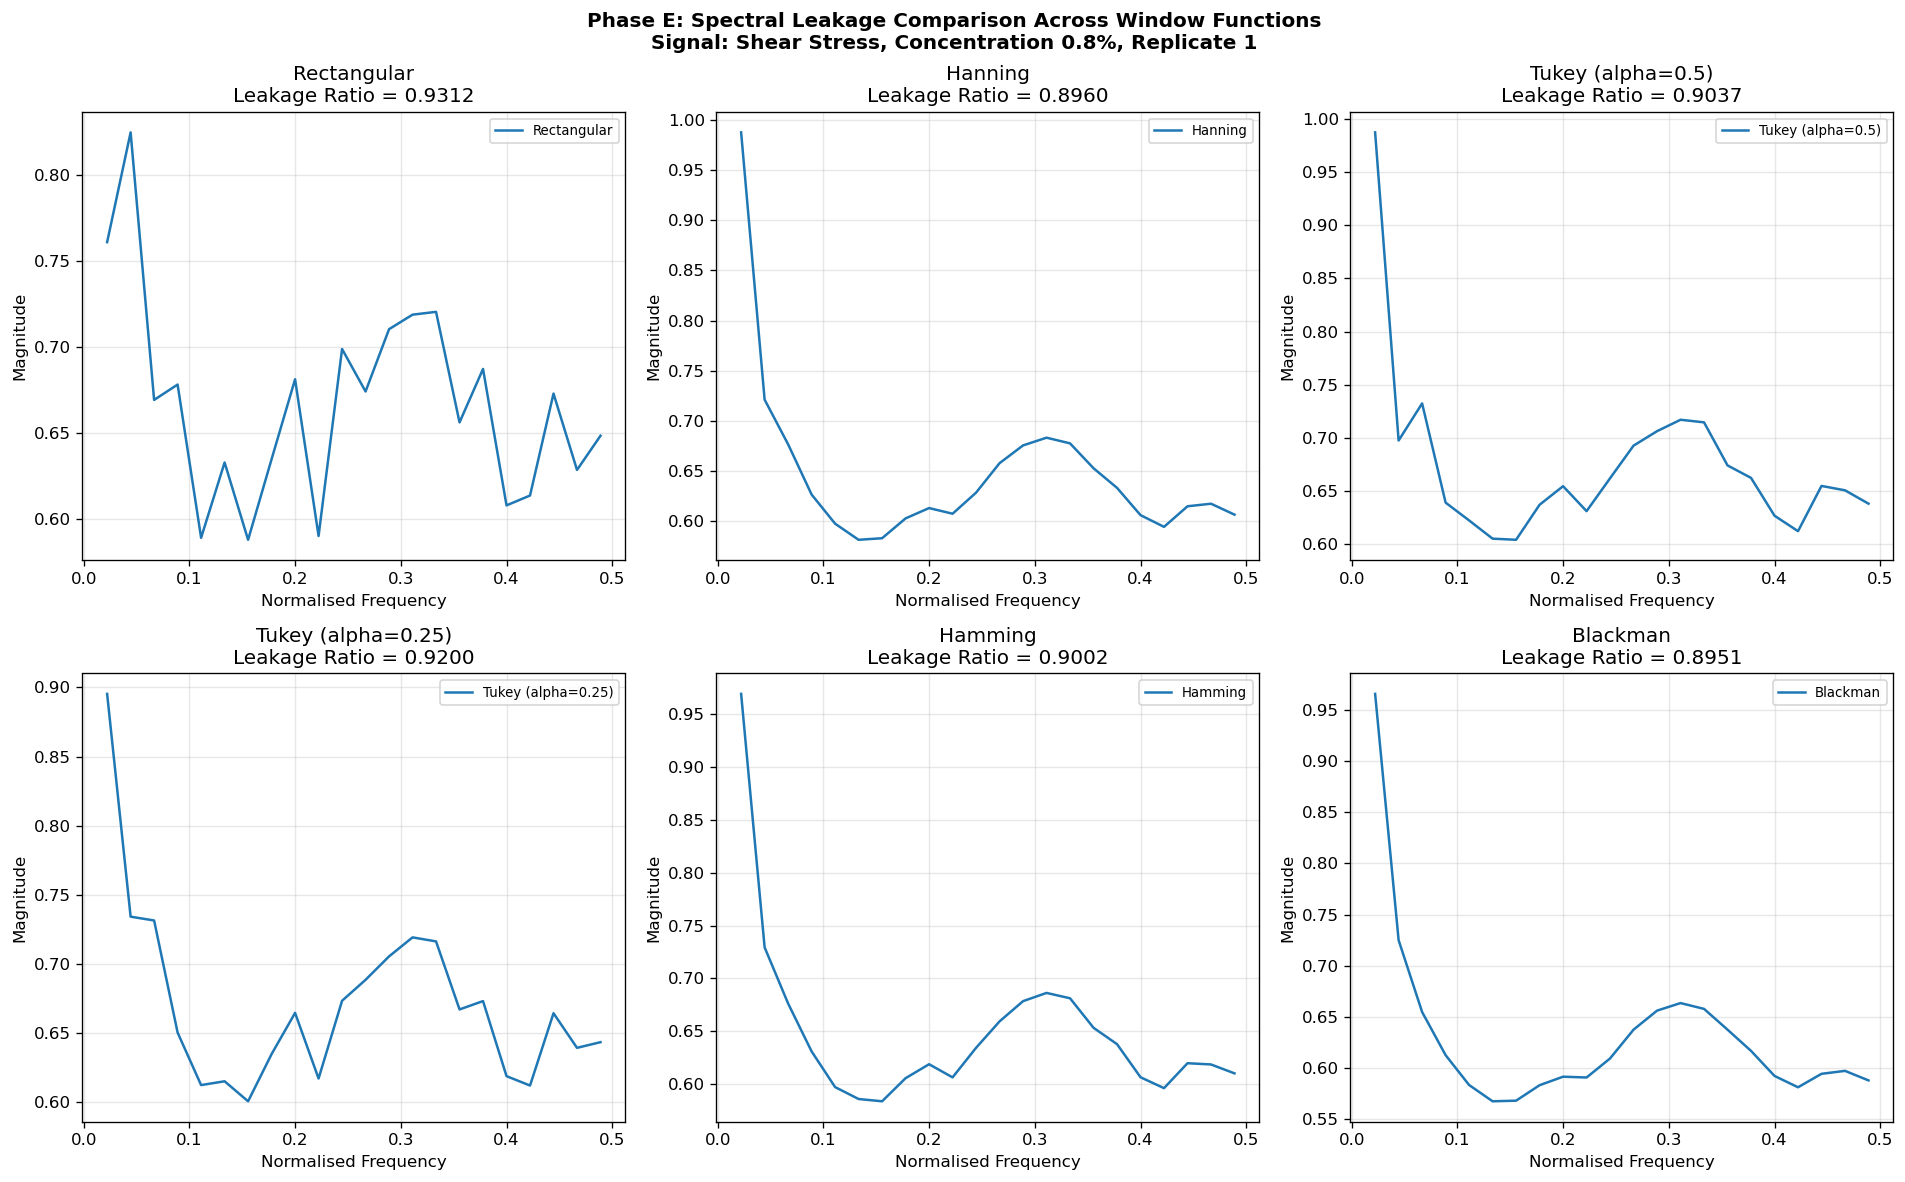


Leakage Comparison Table:
            Window  Peak Frequency  Total Energy  Leakage Ratio
       Rectangular        0.044444      9.879471       0.931166
           Hanning        0.022222      9.378621       0.896015
 Tukey (alpha=0.5)        0.022222     10.124401       0.903737
Tukey (alpha=0.25)        0.022222     10.016001       0.919973
           Hamming        0.022222      9.411149       0.900154
          Blackman        0.022222      8.893887       0.895077

Lower leakage ratio = better spectral concentration = less smearing of energy across frequencies.


In [19]:
# ==========================================
# CELL E1: Window Function Comparison on Shear Stress Signal
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import windows as scipy_windows

example_signal = data_dictionary["0.8"]["1"]["time_sweep"]["shear_stress_Pa"].values
signal_length  = len(example_signal)

window_definitions = {
    'Rectangular': np.ones(signal_length),
    'Hanning':     scipy_windows.hann(signal_length),
    'Tukey (alpha=0.5)': scipy_windows.tukey(signal_length, alpha=0.5),
    'Tukey (alpha=0.25)': scipy_windows.tukey(signal_length, alpha=0.25),
    'Hamming':     scipy_windows.hamming(signal_length),
    'Blackman':    scipy_windows.blackman(signal_length)
}

frequency_axis    = np.fft.fftfreq(signal_length)
positive_freq_mask = frequency_axis > 0

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes_flat = axes.flatten()

leakage_records = []

for plot_index, (window_name, window_values) in enumerate(window_definitions.items()):
    windowed_signal = example_signal * window_values
    fft_spectrum    = np.fft.fft(windowed_signal)
    fft_magnitude   = np.abs(fft_spectrum)[positive_freq_mask]
    positive_freqs  = frequency_axis[positive_freq_mask]

    peak_frequency = positive_freqs[np.argmax(fft_magnitude)]
    total_energy   = np.sum(fft_magnitude ** 2)
    peak_energy    = np.max(fft_magnitude) ** 2
    leakage_ratio  = 1.0 - (peak_energy / (total_energy + 1e-12))
    leakage_records.append({
        'Window': window_name,
        'Peak Frequency': peak_frequency,
        'Total Energy': total_energy,
        'Leakage Ratio': leakage_ratio
    })

    ax = axes_flat[plot_index]
    ax.plot(positive_freqs, fft_magnitude, linewidth=1.5, label=window_name)
    ax.set_title(f"{window_name}\nLeakage Ratio = {leakage_ratio:.4f}")
    ax.set_xlabel("Normalised Frequency")
    ax.set_ylabel("Magnitude")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("Phase E: Spectral Leakage Comparison Across Window Functions\nSignal: Shear Stress, Concentration 0.8%, Replicate 1",
             fontweight='bold')
plt.tight_layout()
plt.show()

leakage_df = pd.DataFrame(leakage_records)
print("\nLeakage Comparison Table:")
print(leakage_df.to_string(index=False))
print("\nLower leakage ratio = better spectral concentration = less smearing of energy across frequencies.")

In [20]:
# ==========================================
# CELL E2: Window Bias on Amplitude Recovery
# ==========================================

print("=" * 70)
print("WINDOW AMPLITUDE BIAS ANALYSIS")
print("=" * 70)
print("Amplitude bias = ratio of recovered amplitude to true amplitude.")
print("A perfect window recovers amplitude ratio = 1.0")
print()

synthetic_frequency   = 0.1  # normalized frequency
time_axis_synthetic   = np.linspace(0, 1, signal_length)
synthetic_true_signal = np.sin(2 * np.pi * synthetic_frequency * signal_length * time_axis_synthetic)

print(f"{'Window':>22} {'Recovered Amplitude':>20} {'True Amplitude':>15} {'Bias Ratio':>12}")
print("-" * 75)

for window_name, window_values in window_definitions.items():
    windowed_synthetic = synthetic_true_signal * window_values
    fft_synthetic      = np.fft.fft(windowed_synthetic)
    fft_magnitude_syn  = np.abs(fft_synthetic)
    recovered_amplitude = np.max(fft_magnitude_syn) / (signal_length / 2.0)
    true_amplitude      = 1.0
    bias_ratio          = recovered_amplitude / true_amplitude
    print(f"{window_name:>22} {recovered_amplitude:>20.4f} {true_amplitude:>15.4f} {bias_ratio:>12.4f}")

print("\nBias ratio close to 1.0 = accurate amplitude recovery.")
print("Tukey window with alpha=0.5 is recommended for OWCh chirp data (from OWCh literature).")

WINDOW AMPLITUDE BIAS ANALYSIS
Amplitude bias = ratio of recovered amplitude to true amplitude.
A perfect window recovers amplitude ratio = 1.0

                Window  Recovered Amplitude  True Amplitude   Bias Ratio
---------------------------------------------------------------------------
           Rectangular               0.7255          1.0000       0.7255
               Hanning               0.4432          1.0000       0.4432
     Tukey (alpha=0.5)               0.6294          1.0000       0.6294
    Tukey (alpha=0.25)               0.7040          1.0000       0.7040
               Hamming               0.4658          1.0000       0.4658
              Blackman               0.3806          1.0000       0.3806

Bias ratio close to 1.0 = accurate amplitude recovery.
Tukey window with alpha=0.5 is recommended for OWCh chirp data (from OWCh literature).


## PHASE F — Fourier Ecosystem Analysis

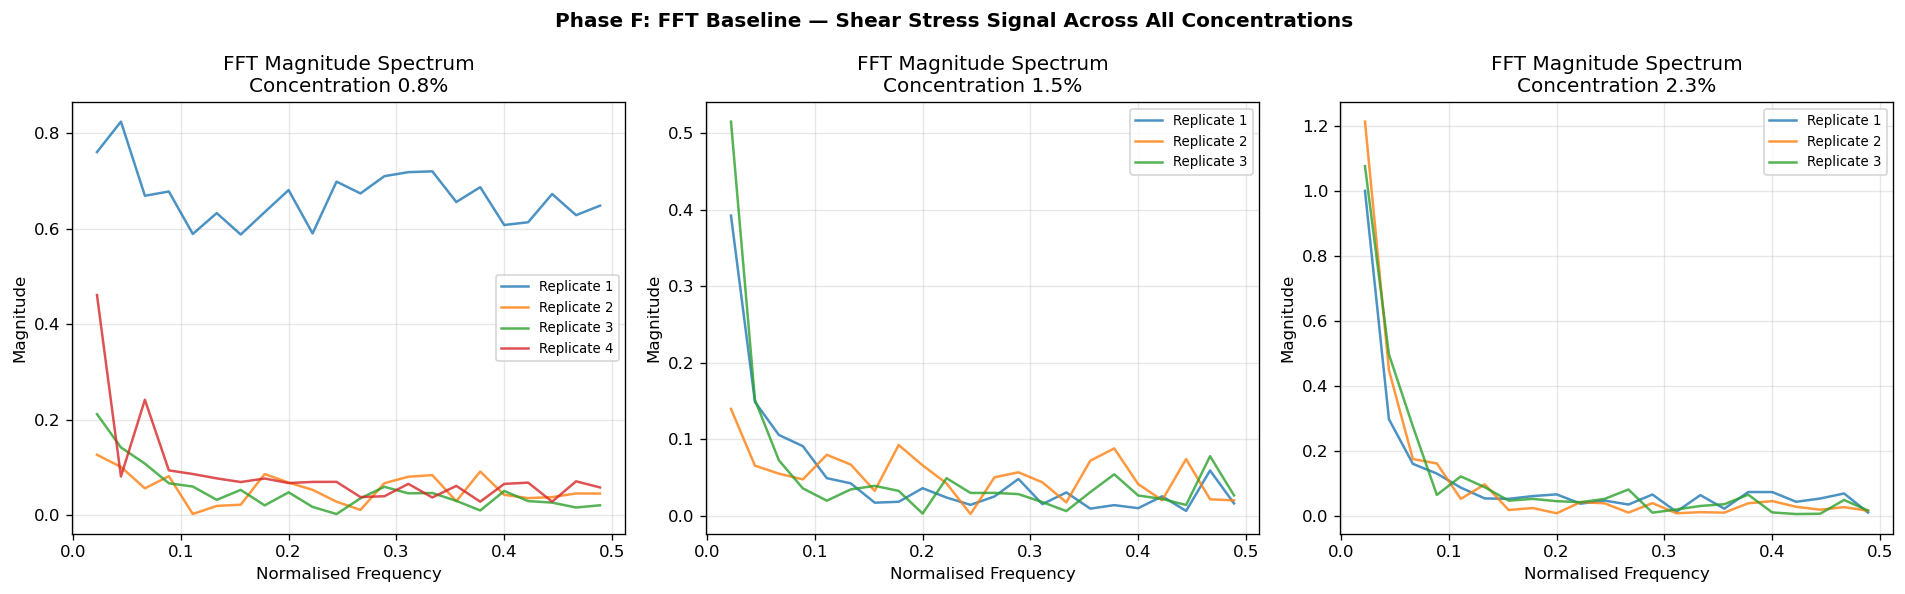

Note: FFT applied to G'(t) gives frequency components of modulus evolution,
NOT the viscoelastic frequency spectrum G'(omega). This distinction is critical.


In [21]:
# ==========================================
# CELL F1: FFT Baseline on All Time Sweep Signals
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fft_results_by_concentration = {}

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    ax = axes[column_index]
    fft_results_by_concentration[concentration_key] = []

    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        shear_stress_values = (
            data_dictionary[concentration_key][replicate_key]['time_sweep']['shear_stress_Pa'].values
        )
        n_samples      = len(shear_stress_values)
        fft_complex    = np.fft.fft(shear_stress_values)
        fft_magnitude  = np.abs(fft_complex)
        frequency_bins = np.fft.fftfreq(n_samples)
        positive_mask  = frequency_bins > 0
        positive_freqs = frequency_bins[positive_mask]
        positive_mags  = fft_magnitude[positive_mask]

        fft_results_by_concentration[concentration_key].append({
            'replicate': replicate_key,
            'frequencies': positive_freqs,
            'magnitudes': positive_mags
        })
        ax.plot(positive_freqs, positive_mags, label=f"Replicate {replicate_key}", alpha=0.8)

    ax.set_title(f"FFT Magnitude Spectrum\nConcentration {concentration_key}%")
    ax.set_xlabel("Normalised Frequency")
    ax.set_ylabel("Magnitude")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("Phase F: FFT Baseline — Shear Stress Signal Across All Concentrations",
             fontweight='bold')
plt.tight_layout()
plt.show()

print("Note: FFT applied to G'(t) gives frequency components of modulus evolution,")
print("NOT the viscoelastic frequency spectrum G'(omega). This distinction is critical.")

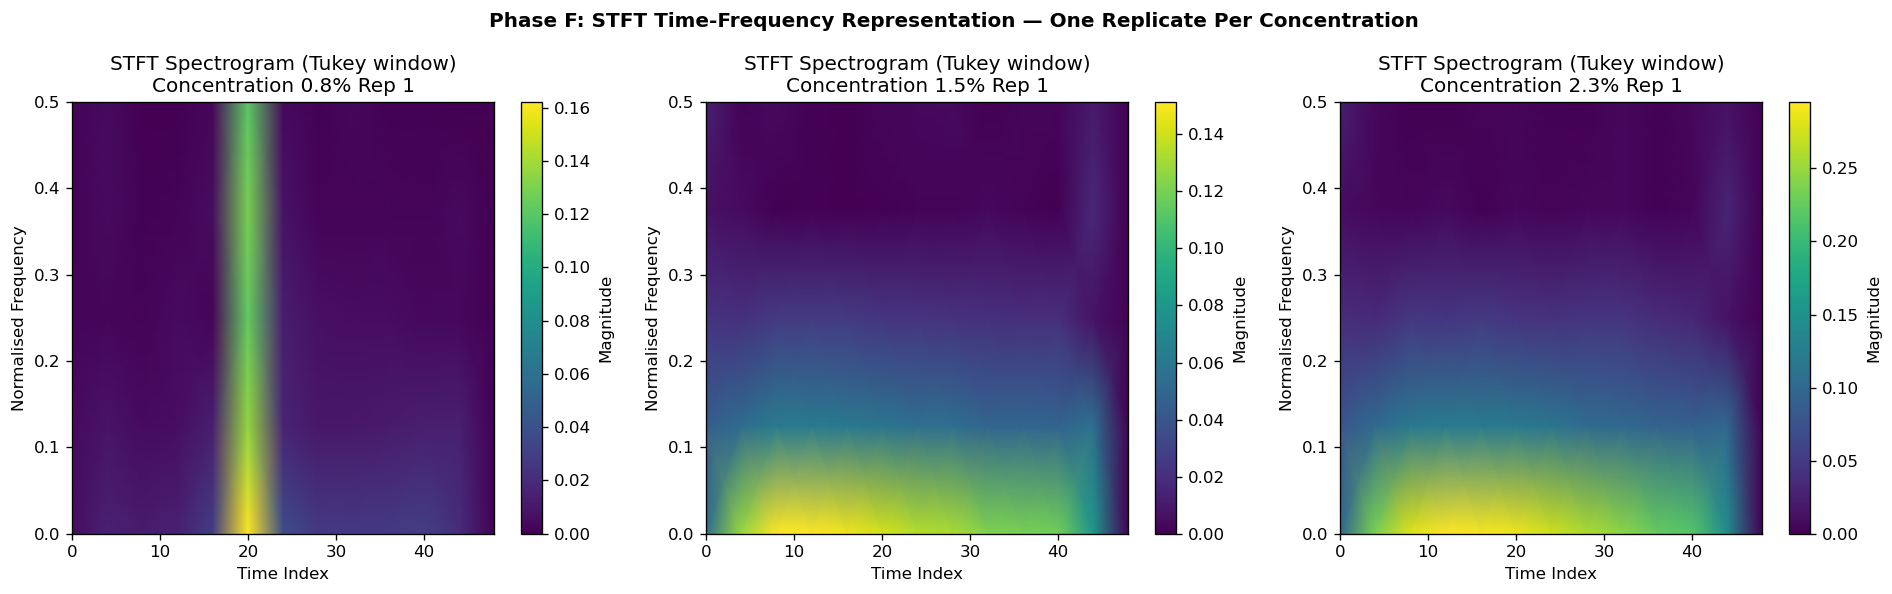

In [22]:
# ==========================================
# CELL F2: STFT Analysis — Time-Frequency Map
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    ax = axes[column_index]
    first_replicate_key = sorted(data_dictionary[concentration_key].keys())[0]
    if 'time_sweep' not in data_dictionary[concentration_key][first_replicate_key]:
        continue
    shear_stress_values = (
        data_dictionary[concentration_key][first_replicate_key]['time_sweep']['shear_stress_Pa'].values
    )
    tukey_window = scipy_windows.tukey(8, alpha=0.5)
    stft_frequencies, stft_times, stft_complex = stft(
        shear_stress_values, window=tukey_window, nperseg=8, noverlap=4
    )
    stft_magnitude = np.abs(stft_complex)
    img = ax.pcolormesh(stft_times, stft_frequencies, stft_magnitude, shading='gouraud', cmap='viridis')
    plt.colorbar(img, ax=ax, label="Magnitude")
    ax.set_title(f"STFT Spectrogram (Tukey window)\nConcentration {concentration_key}% Rep {first_replicate_key}")
    ax.set_xlabel("Time Index")
    ax.set_ylabel("Normalised Frequency")

plt.suptitle("Phase F: STFT Time-Frequency Representation — One Replicate Per Concentration",
             fontweight='bold')
plt.tight_layout()
plt.show()

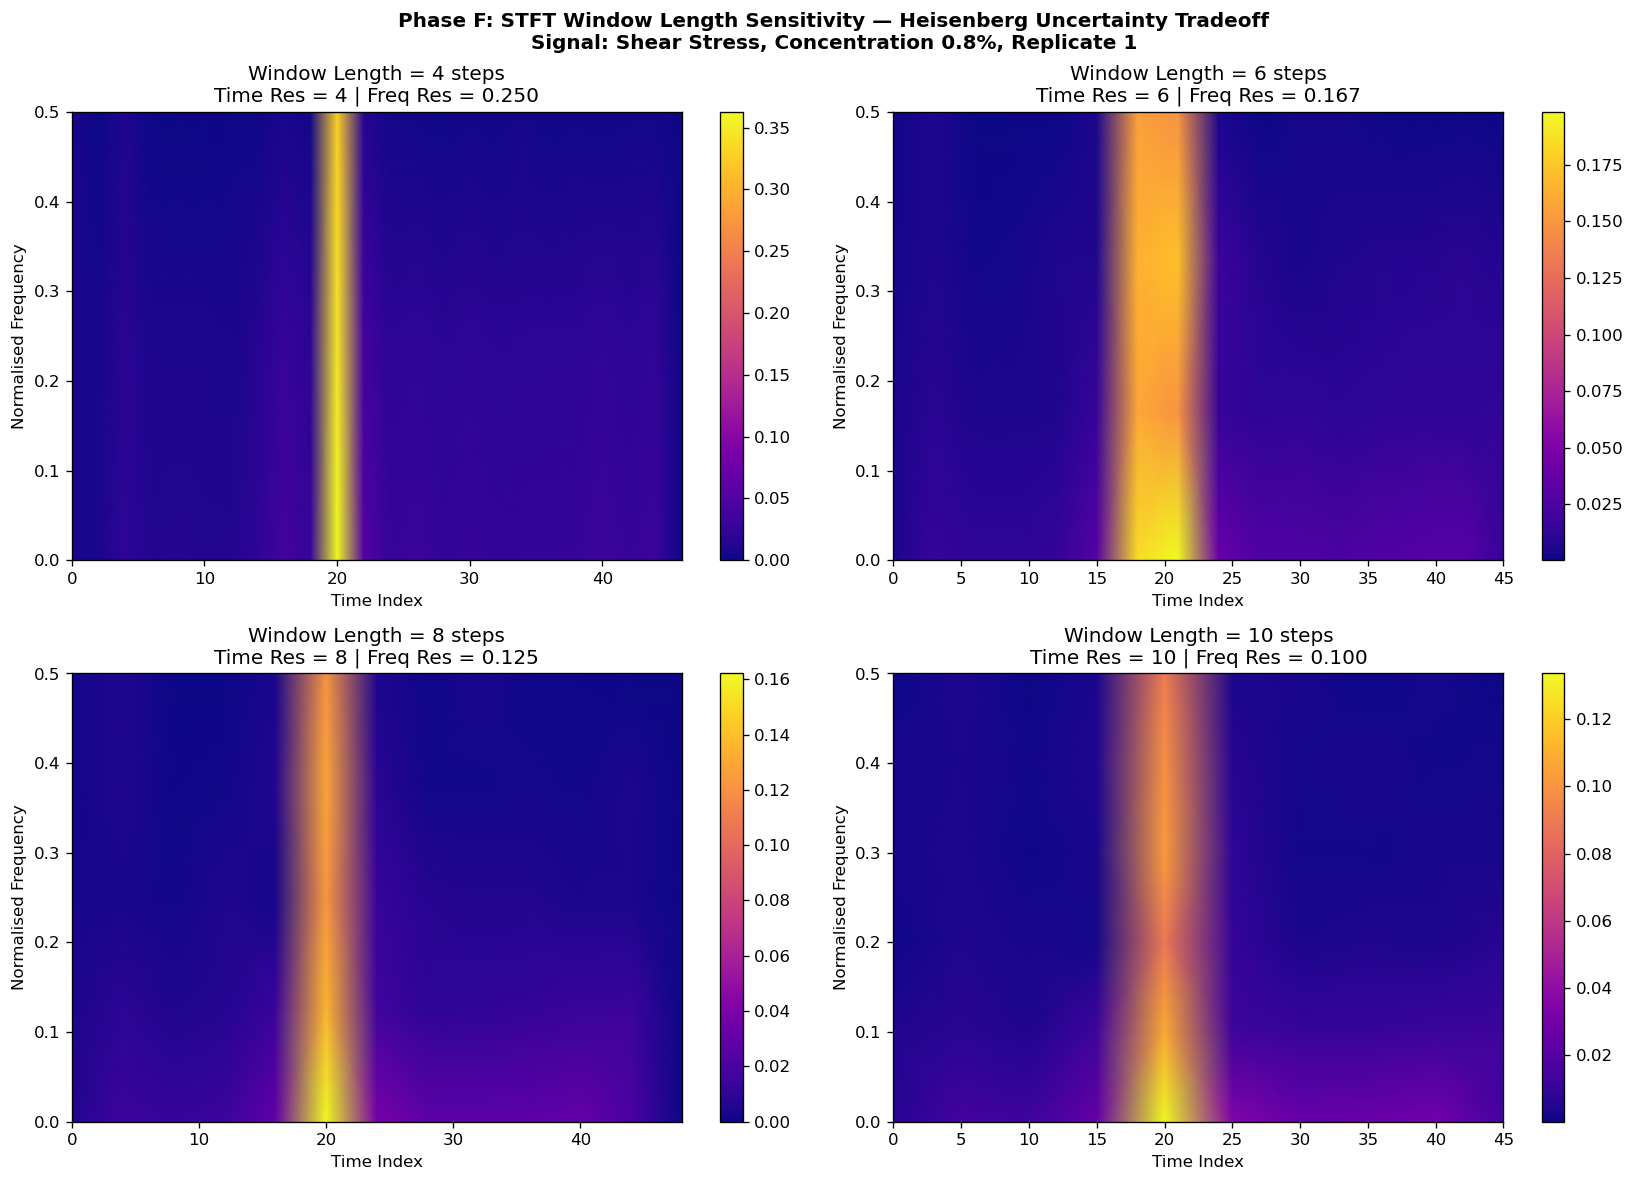


STFT Window Length Analysis:
 Window Length  Time Resolution (steps)  Frequency Resolution  Heisenberg Product
             4                        4                0.2500                 1.0
             6                        6                0.1667                 1.0
             8                        8                0.1250                 1.0
            10                       10                0.1000                 1.0

Heisenberg Uncertainty: time_resolution * frequency_resolution >= constant.
Larger window = better frequency resolution but worse time resolution (fixed tradeoff).
CWT overcomes this by using adaptive window length per frequency.


In [23]:
# ==========================================
# CELL F3: STFT Window Length Sensitivity Analysis
# ==========================================

reference_signal = data_dictionary["0.8"]["1"]["time_sweep"]["shear_stress_Pa"].values
window_lengths_to_test = [4, 6, 8, 10]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes_flat = axes.flatten()

stft_window_records = []

for plot_index, window_length in enumerate(window_lengths_to_test):
    ax = axes_flat[plot_index]
    tukey_window = scipy_windows.tukey(window_length, alpha=0.5)
    stft_frequencies, stft_times, stft_complex = stft(
        reference_signal, window=tukey_window, nperseg=window_length, noverlap=window_length // 2
    )
    stft_magnitude = np.abs(stft_complex)
    time_resolution      = window_length
    frequency_resolution = 1.0 / window_length
    img = ax.pcolormesh(stft_times, stft_frequencies, stft_magnitude, shading='gouraud', cmap='plasma')
    plt.colorbar(img, ax=ax)
    ax.set_title(f"Window Length = {window_length} steps\n"
                 f"Time Res = {time_resolution} | Freq Res = {frequency_resolution:.3f}")
    ax.set_xlabel("Time Index")
    ax.set_ylabel("Normalised Frequency")
    stft_window_records.append({
        'Window Length': window_length,
        'Time Resolution (steps)': time_resolution,
        'Frequency Resolution': round(frequency_resolution, 4),
        'Heisenberg Product': round(time_resolution * frequency_resolution, 4)
    })

plt.suptitle("Phase F: STFT Window Length Sensitivity — Heisenberg Uncertainty Tradeoff\n"
             "Signal: Shear Stress, Concentration 0.8%, Replicate 1", fontweight='bold')
plt.tight_layout()
plt.show()

stft_window_df = pd.DataFrame(stft_window_records)
print("\nSTFT Window Length Analysis:")
print(stft_window_df.to_string(index=False))
print("\nHeisenberg Uncertainty: time_resolution * frequency_resolution >= constant.")
print("Larger window = better frequency resolution but worse time resolution (fixed tradeoff).")
print("CWT overcomes this by using adaptive window length per frequency.")

## PHASE G — Time-Frequency Decomposition

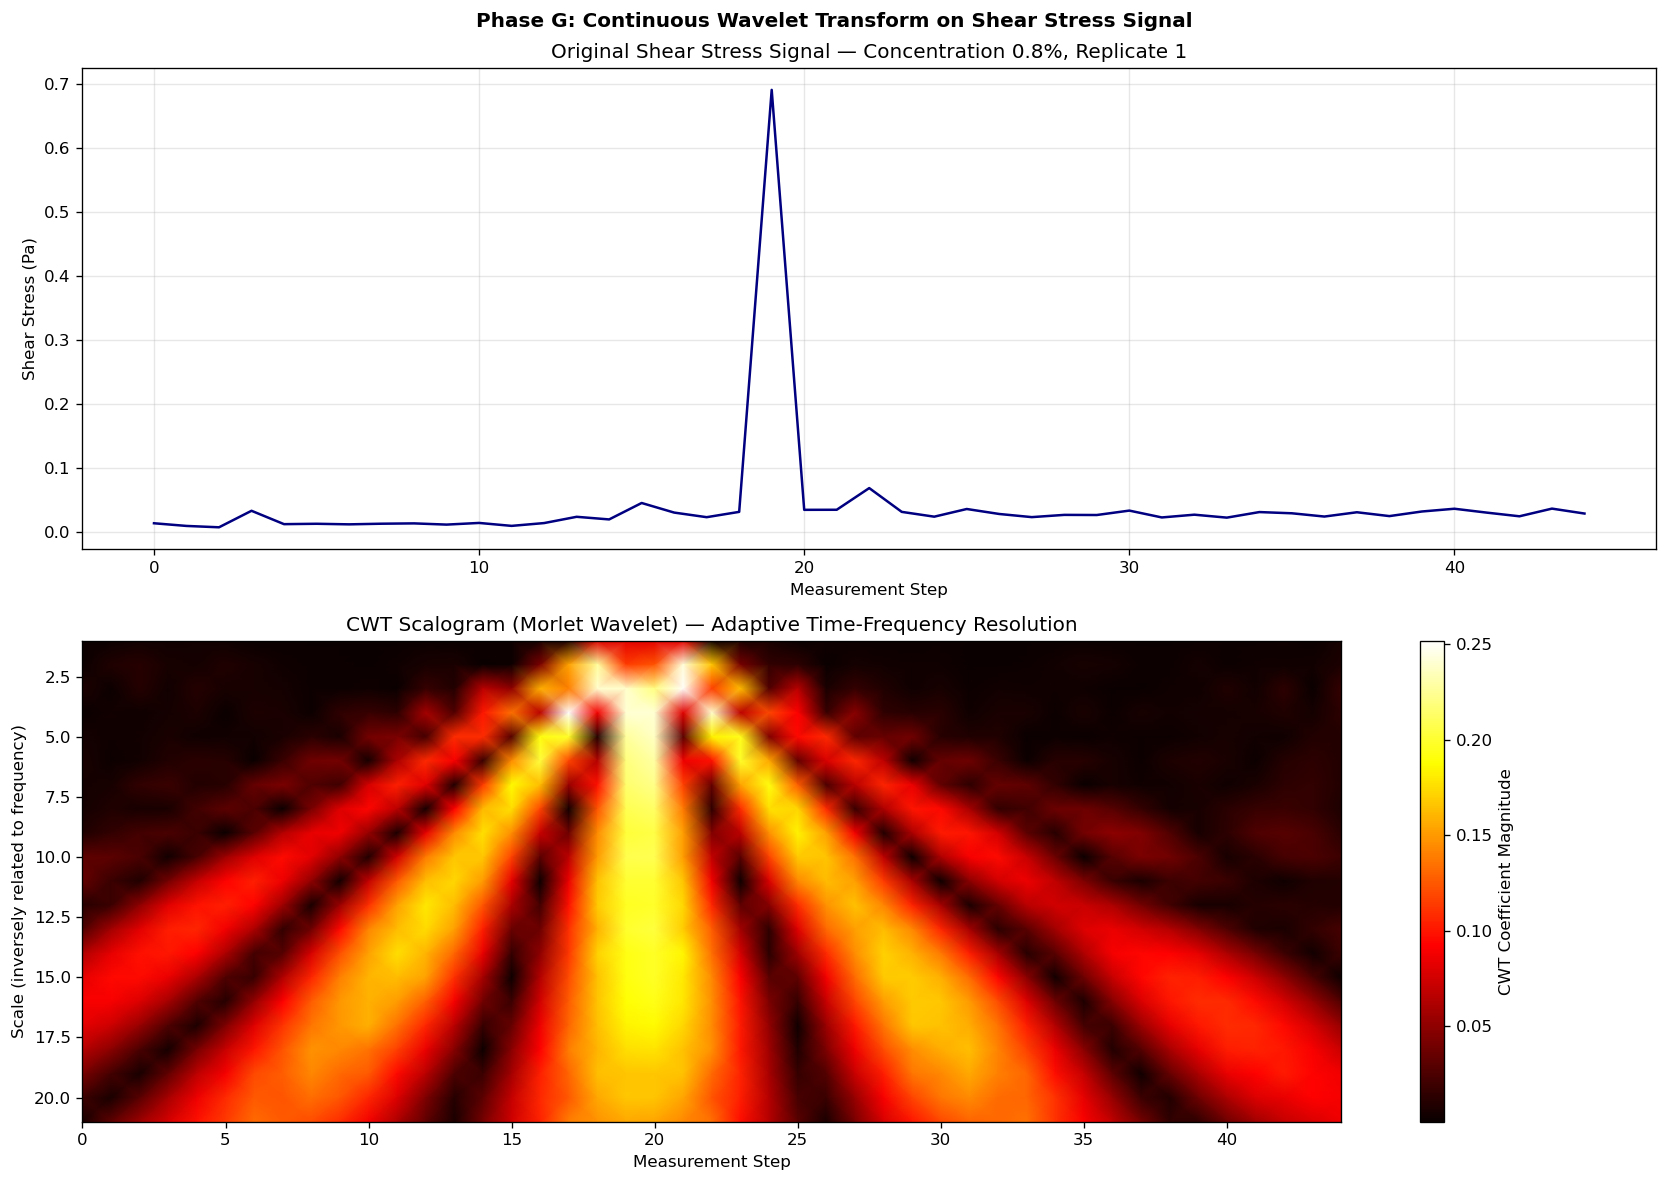

Available PyWavelets continuous wavelets: ['cgau1', 'cgau2', 'cgau3', 'cgau4', 'cgau5', 'cgau6', 'cgau7', 'cgau8', 'cmor', 'fbsp', 'gaus1', 'gaus2', 'gaus3', 'gaus4', 'gaus5', 'gaus6', 'gaus7', 'gaus8', 'mexh', 'morl', 'shan']

CWT advantage: window width adapts to scale.
Small scales (high frequency): narrow window = good time resolution.
Large scales (low frequency): wide window = good frequency resolution.
This is the key advantage over STFT which uses a fixed window length.


In [30]:
# ==========================================
# CELL G1: Continuous Wavelet Transform — Morlet Wavelet
# ==========================================

import sys
!{sys.executable} -m pip install PyWavelets

import pywt
import numpy as np
import matplotlib.pyplot as plt

reference_signal = data_dictionary["0.8"]["1"]["time_sweep"]["shear_stress_Pa"].values
n_samples        = len(reference_signal)
scales_array     = np.arange(1, n_samples // 2)

cwt_coefficients, cwt_frequencies = pywt.cwt(
    reference_signal,
    scales_array,
    'morl'
)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(np.arange(n_samples), reference_signal, linewidth=1.5, color='navy')
axes[0].set_title("Original Shear Stress Signal — Concentration 0.8%, Replicate 1")
axes[0].set_xlabel("Measurement Step")
axes[0].set_ylabel("Shear Stress (Pa)")
axes[0].grid(True, alpha=0.3)

img = axes[1].pcolormesh(
    np.arange(n_samples),
    scales_array,
    np.abs(cwt_coefficients),
    shading='gouraud',
    cmap='hot'
)
plt.colorbar(img, ax=axes[1], label="CWT Coefficient Magnitude")
axes[1].set_title("CWT Scalogram (Morlet Wavelet) — Adaptive Time-Frequency Resolution")
axes[1].set_xlabel("Measurement Step")
axes[1].set_ylabel("Scale (inversely related to frequency)")
axes[1].invert_yaxis()

plt.suptitle("Phase G: Continuous Wavelet Transform on Shear Stress Signal", fontweight='bold')
plt.tight_layout()
plt.show()

print("Available PyWavelets continuous wavelets:", pywt.wavelist(kind='continuous'))
print()
print("CWT advantage: window width adapts to scale.")
print("Small scales (high frequency): narrow window = good time resolution.")
print("Large scales (low frequency): wide window = good frequency resolution.")
print("This is the key advantage over STFT which uses a fixed window length.")

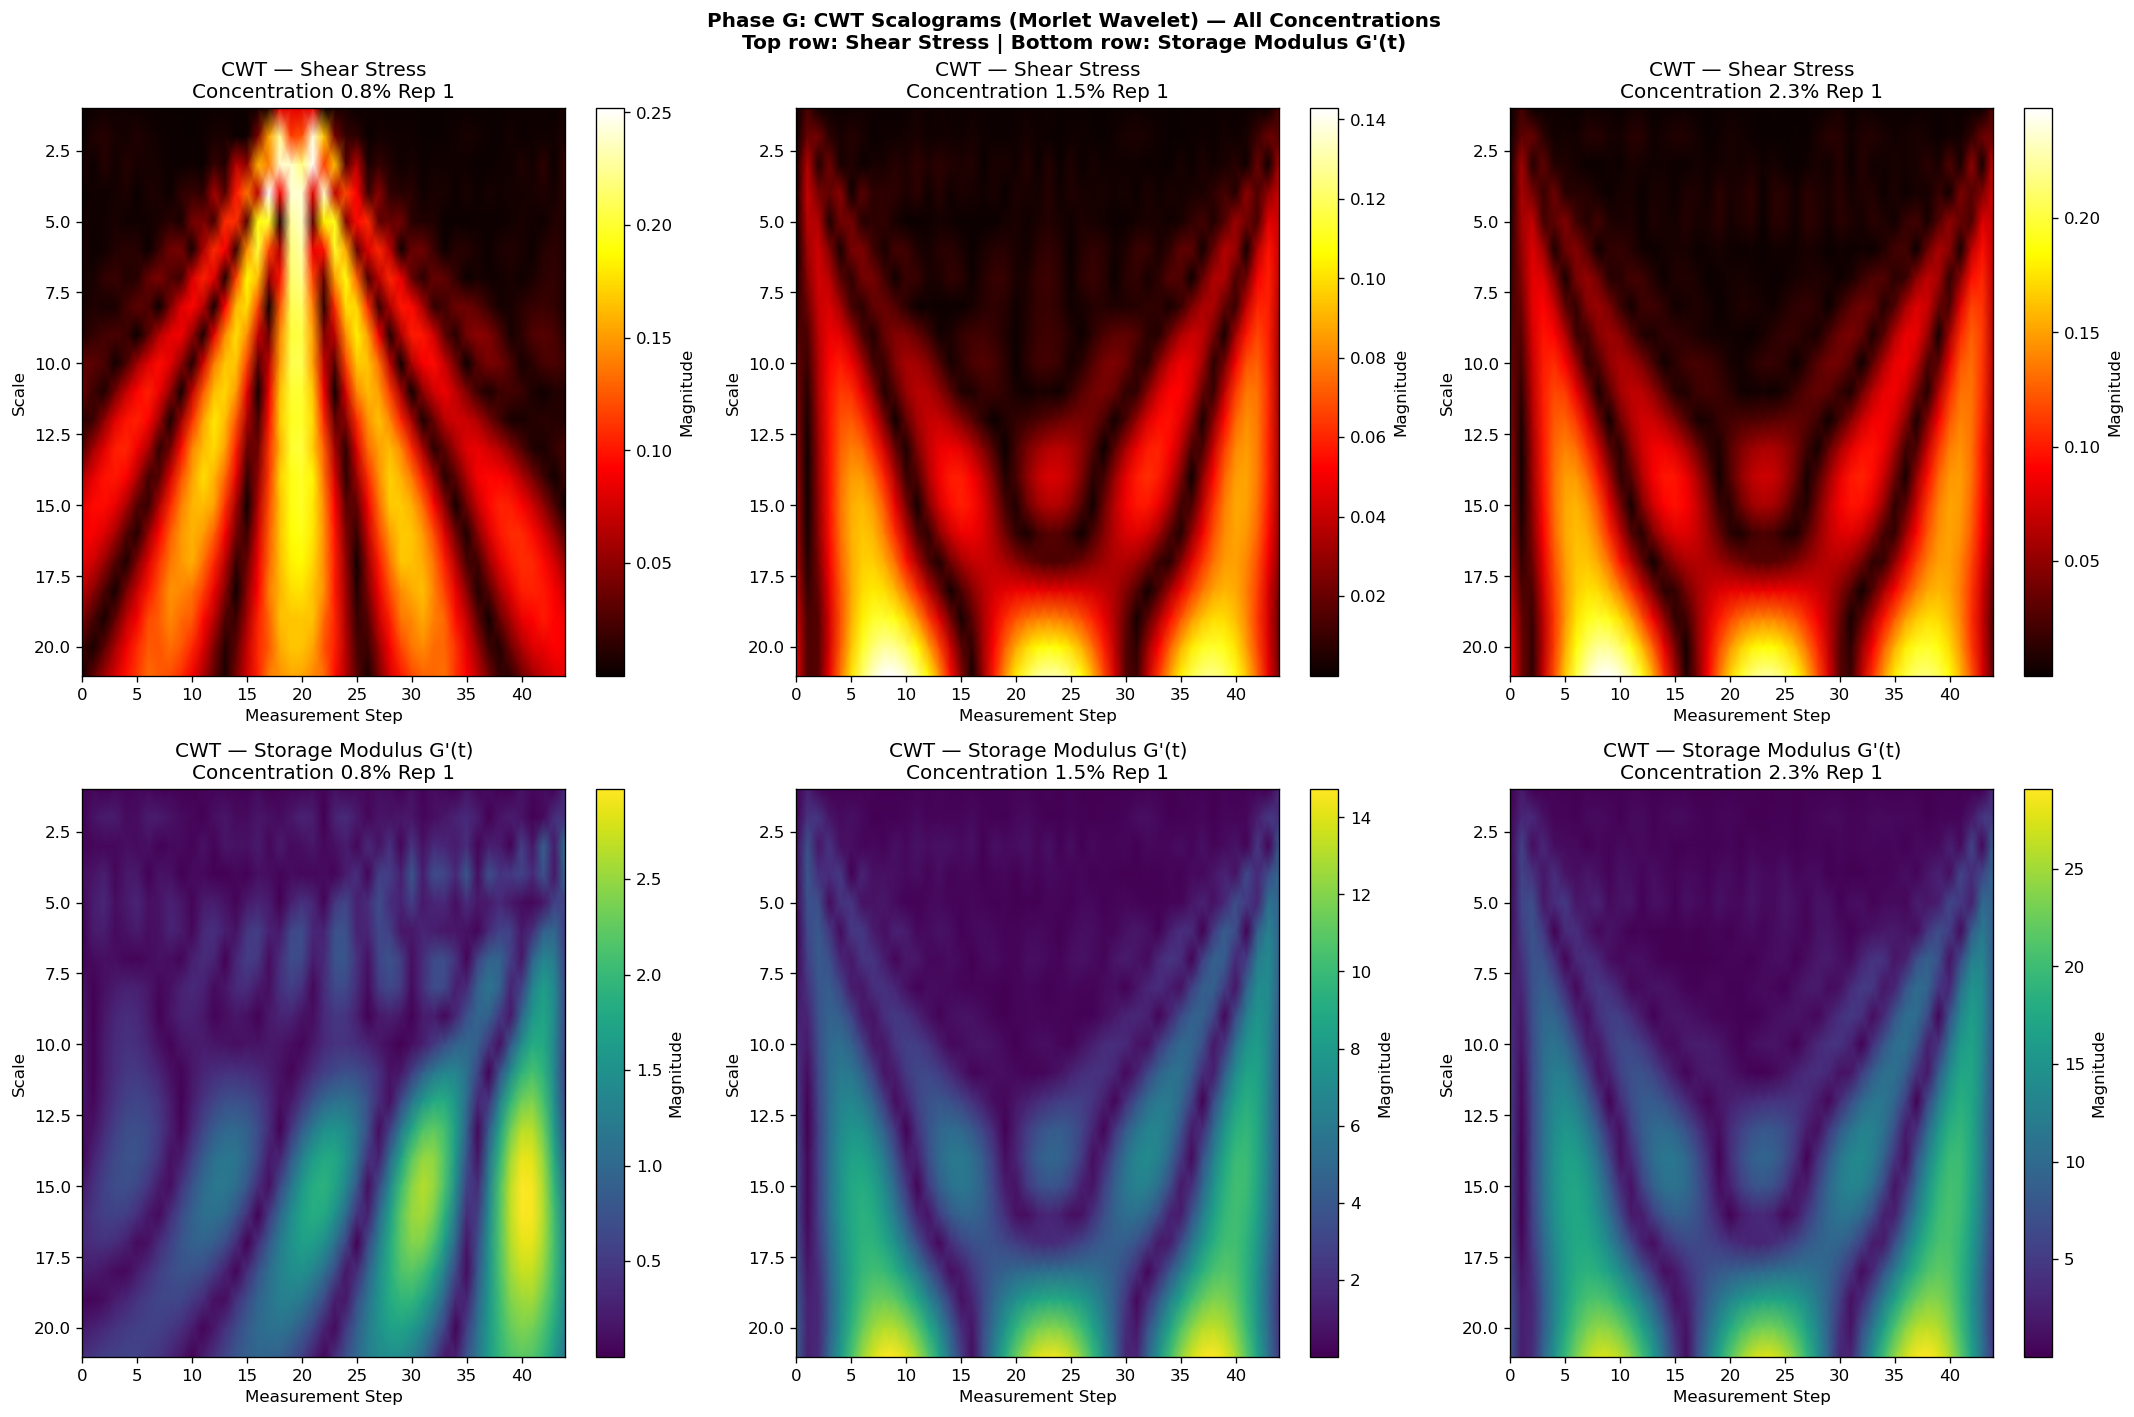

Interpretation:
  Bright regions in scalogram = high energy at that scale and time.
  Transient events appear as vertical bright bands (localised in time).
  Persistent features appear as horizontal bright bands (sustained frequency).
  Higher concentration gels show less time variation = more uniform scalogram.


In [31]:
# ==========================================
# CELL G2: CWT Across All Concentrations — Side by Side
# ==========================================

import pywt
import numpy as np
import matplotlib.pyplot as plt

scales_array = np.arange(1, 22)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    first_replicate_key = sorted(data_dictionary[concentration_key].keys())[0]
    if 'time_sweep' not in data_dictionary[concentration_key][first_replicate_key]:
        continue

    shear_stress_values = (
        data_dictionary[concentration_key][first_replicate_key]['time_sweep']['shear_stress_Pa'].values
    )
    storage_modulus_values = (
        data_dictionary[concentration_key][first_replicate_key]['time_sweep']['storage_modulus_Pa'].values
    )

    n_steps = len(shear_stress_values)

    # CWT on shear stress
    cwt_shear, _ = pywt.cwt(shear_stress_values, scales_array, 'morl')

    # CWT on G'(t)
    cwt_G_prime, _ = pywt.cwt(storage_modulus_values, scales_array, 'morl')

    img1 = axes[0, column_index].pcolormesh(
        np.arange(n_steps),
        scales_array,
        np.abs(cwt_shear),
        shading='gouraud',
        cmap='hot'
    )
    plt.colorbar(img1, ax=axes[0, column_index], label="Magnitude")
    axes[0, column_index].set_title(
        f"CWT — Shear Stress\nConcentration {concentration_key}% Rep {first_replicate_key}"
    )
    axes[0, column_index].set_xlabel("Measurement Step")
    axes[0, column_index].set_ylabel("Scale")
    axes[0, column_index].invert_yaxis()

    img2 = axes[1, column_index].pcolormesh(
        np.arange(n_steps),
        scales_array,
        np.abs(cwt_G_prime),
        shading='gouraud',
        cmap='viridis'
    )
    plt.colorbar(img2, ax=axes[1, column_index], label="Magnitude")
    axes[1, column_index].set_title(
        f"CWT — Storage Modulus G'(t)\nConcentration {concentration_key}% Rep {first_replicate_key}"
    )
    axes[1, column_index].set_xlabel("Measurement Step")
    axes[1, column_index].set_ylabel("Scale")
    axes[1, column_index].invert_yaxis()

plt.suptitle(
    "Phase G: CWT Scalograms (Morlet Wavelet) — All Concentrations\n"
    "Top row: Shear Stress | Bottom row: Storage Modulus G'(t)",
    fontweight='bold'
)
plt.tight_layout()
plt.show()

print("Interpretation:")
print("  Bright regions in scalogram = high energy at that scale and time.")
print("  Transient events appear as vertical bright bands (localised in time).")
print("  Persistent features appear as horizontal bright bands (sustained frequency).")
print("  Higher concentration gels show less time variation = more uniform scalogram.")

## PHASE K — Gelation Physics Extraction

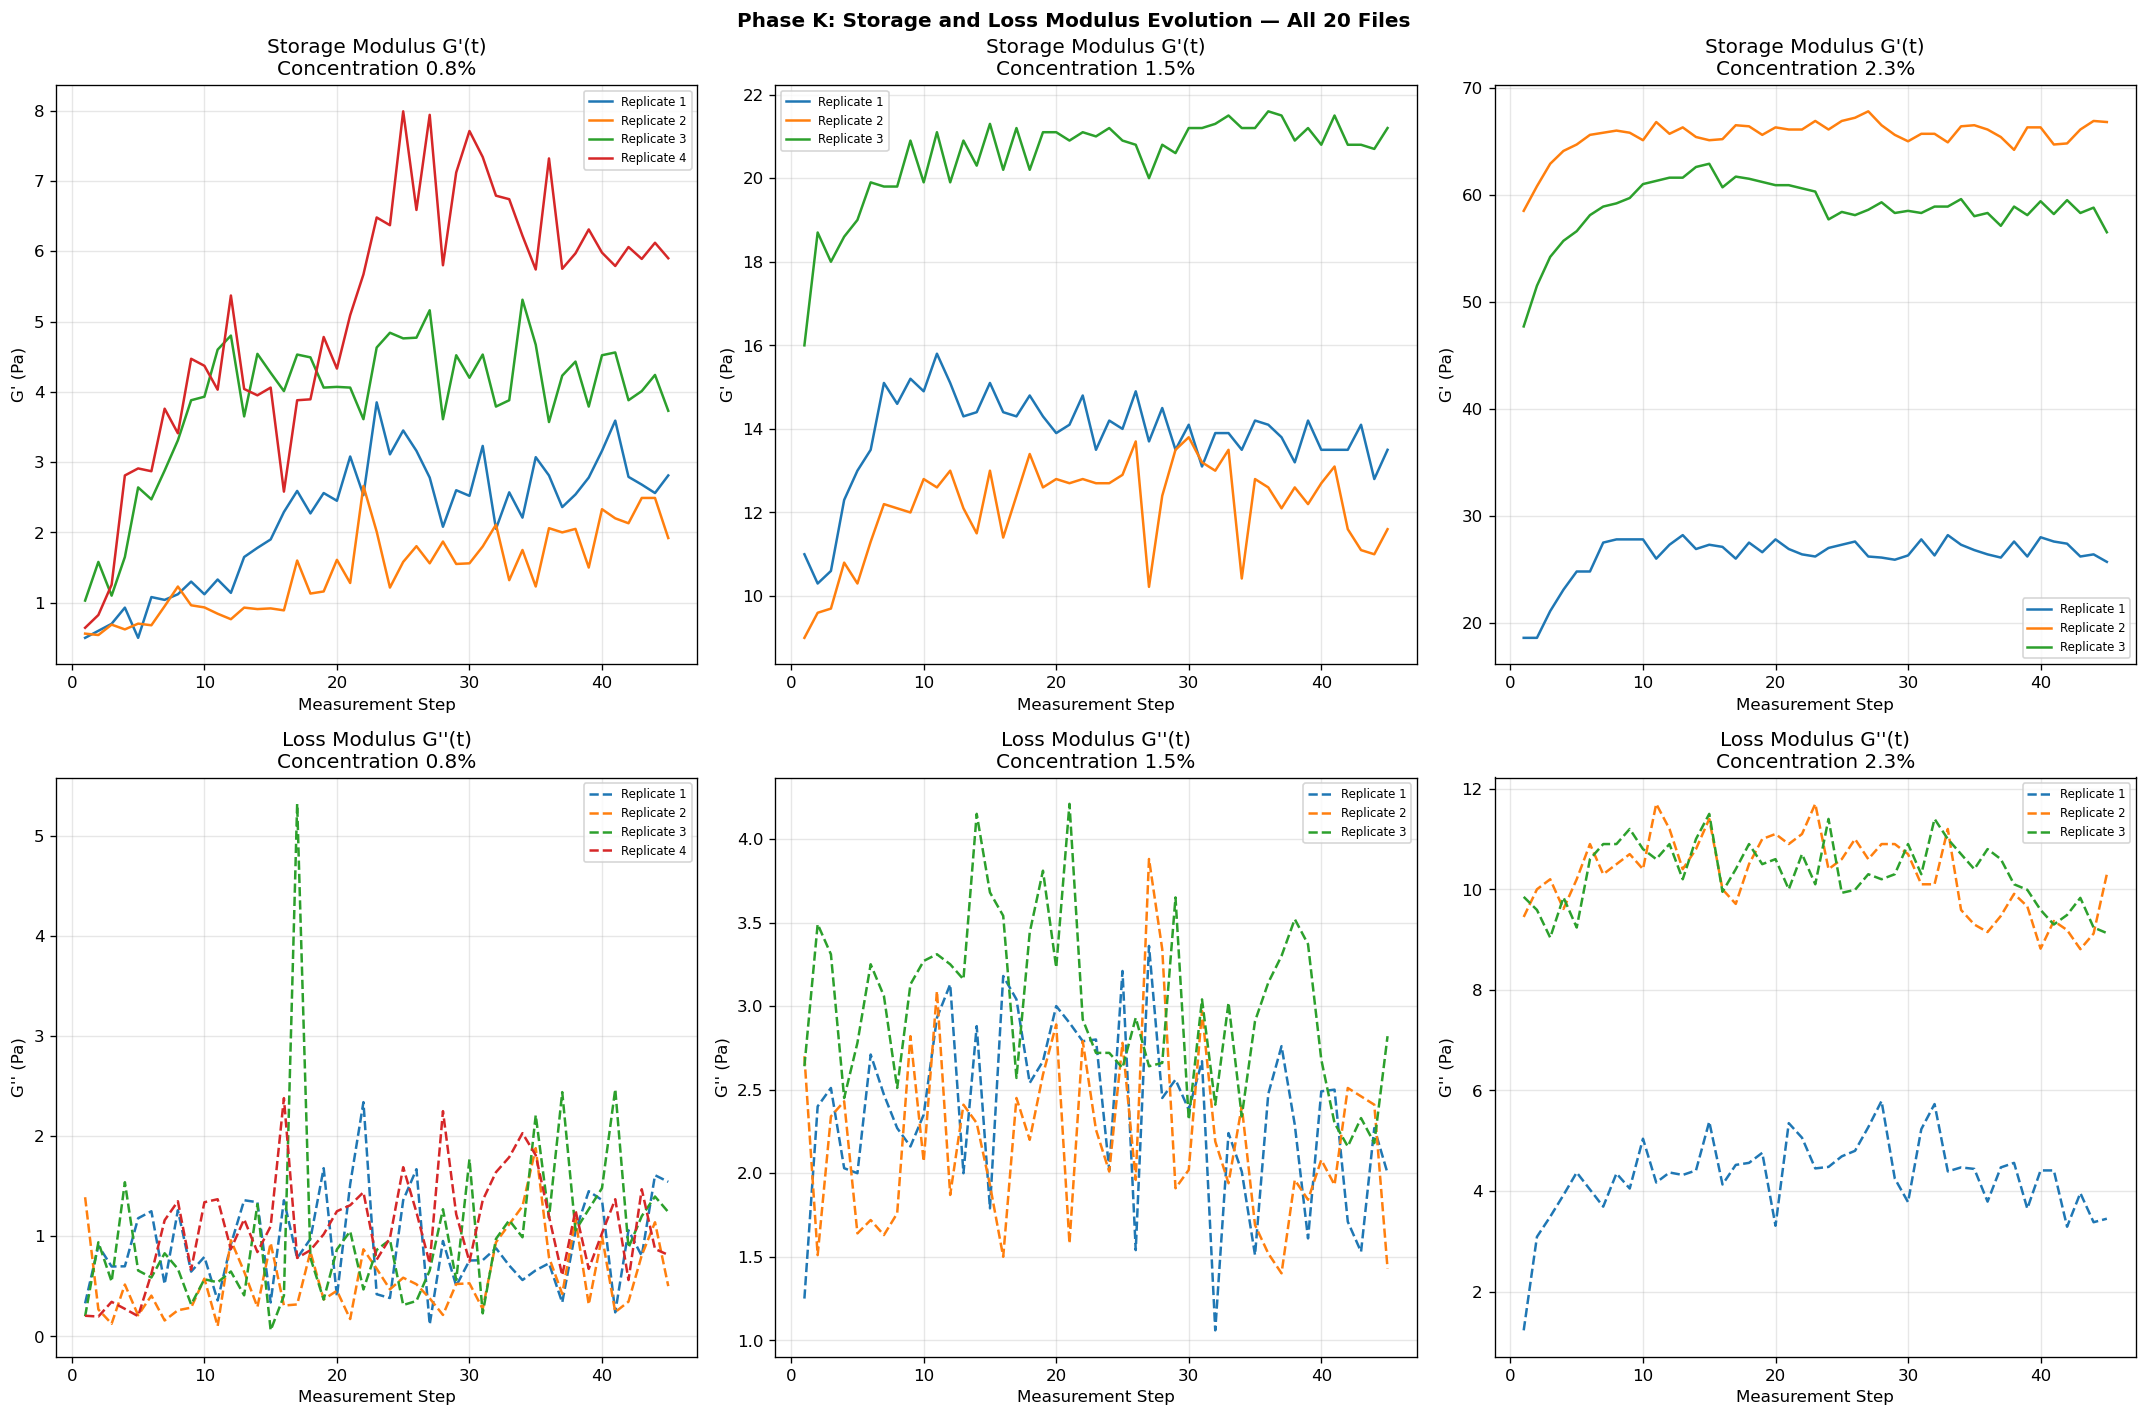

In [32]:
# ==========================================
# CELL K1: G'(t) and G''(t) Evolution — All 20 Files
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
concentration_list = sorted(data_dictionary.keys())
color_palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for column_index, concentration_key in enumerate(concentration_list):
    ax_G_prime        = axes[0, column_index]
    ax_G_double_prime = axes[1, column_index]
    for rep_plot_index, replicate_key in enumerate(sorted(data_dictionary[concentration_key])):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        measurement_steps  = time_sweep_df['meas_pts'].values
        storage_modulus    = time_sweep_df['storage_modulus_Pa'].values
        loss_modulus       = time_sweep_df['loss_modulus_Pa'].values
        ax_G_prime.plot(measurement_steps, storage_modulus,
                        color=color_palette[rep_plot_index % 4],
                        label=f"Replicate {replicate_key}", linewidth=1.5)
        ax_G_double_prime.plot(measurement_steps, loss_modulus,
                               color=color_palette[rep_plot_index % 4],
                               label=f"Replicate {replicate_key}", linewidth=1.5, linestyle='--')
    ax_G_prime.set_title(f"Storage Modulus G'(t)\nConcentration {concentration_key}%")
    ax_G_prime.set_xlabel("Measurement Step")
    ax_G_prime.set_ylabel("G' (Pa)")
    ax_G_prime.legend(fontsize=7)
    ax_G_prime.grid(True, alpha=0.3)
    ax_G_double_prime.set_title(f"Loss Modulus G''(t)\nConcentration {concentration_key}%")
    ax_G_double_prime.set_xlabel("Measurement Step")
    ax_G_double_prime.set_ylabel("G'' (Pa)")
    ax_G_double_prime.legend(fontsize=7)
    ax_G_double_prime.grid(True, alpha=0.3)

plt.suptitle("Phase K: Storage and Loss Modulus Evolution — All 20 Files", fontweight='bold')
plt.tight_layout()
plt.show()

In [35]:
# ==========================================
# CELL K2: Gel Point Detection — G'/G'' Crossover — All Replicates
# ==========================================

print("=" * 70)
print("GEL POINT DETECTION — G'/G'' CROSSOVER METHOD")
print("=" * 70)
print(f"{'Conc':>6} {'Rep':>4} {'Gel Point Step':>15} {'G at GP':>12} {'Final State':>14}")
print("-" * 58)

gel_point_by_concentration = {}
gel_point_all_records = []

for concentration_key in sorted(data_dictionary):
    gel_point_by_concentration[concentration_key] = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        loss_modulus_values    = time_sweep_df['loss_modulus_Pa'].values
        measurement_steps      = time_sweep_df['meas_pts'].values
        modulus_difference     = storage_modulus_values - loss_modulus_values
        gel_point_step = None
        gel_point_G    = None
        for step_index in range(1, len(modulus_difference)):
            if modulus_difference[step_index - 1] < 0 and modulus_difference[step_index] >= 0:
                gel_point_step = measurement_steps[step_index]
                gel_point_G    = storage_modulus_values[step_index]
                break
        final_state = "GEL" if storage_modulus_values[-1] > loss_modulus_values[-1] else "SOL"
        gel_point_by_concentration[concentration_key].append(gel_point_step)
        gel_point_all_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'Gel Point Step': gel_point_step,
            'G at Gel Point (Pa)': gel_point_G,
            'Final State': final_state
        })
        gel_point_str = str(gel_point_step) if gel_point_step is not None else "Not detected"
        G_str = f"{gel_point_G:.3f}" if gel_point_G is not None else "N/A"
        print(f"{concentration_key:>6} {replicate_key:>4} {gel_point_str:>15} {G_str:>12} {final_state:>14}")

gel_point_df = pd.DataFrame(gel_point_all_records)
print("\nSummary by concentration:")
for concentration_key in sorted(gel_point_by_concentration):
    valid_gel_points = [v for v in gel_point_by_concentration[concentration_key] if v is not None]
    if valid_gel_points:
        print(f"  Concentration {concentration_key}%: "
              f"gel point at step {np.mean(valid_gel_points):.1f} +/- {np.std(valid_gel_points):.1f}")
    else:
        print(f"  Concentration {concentration_key}%: gel point not detectable (already gelled at measurement start)")

GEL POINT DETECTION — G'/G'' CROSSOVER METHOD
  Conc  Rep  Gel Point Step      G at GP    Final State
----------------------------------------------------------
   0.8    1               3        0.700            GEL
   0.8    2               2        0.540            GEL
   0.8    3              18        4.490            GEL
   0.8    4    Not detected          N/A            GEL
   1.5    1    Not detected          N/A            GEL
   1.5    2    Not detected          N/A            GEL
   1.5    3    Not detected          N/A            GEL
   2.3    1    Not detected          N/A            GEL
   2.3    2    Not detected          N/A            GEL
   2.3    3    Not detected          N/A            GEL

Summary by concentration:
  Concentration 0.8%: gel point at step 7.7 +/- 7.3
  Concentration 1.5%: gel point not detectable (already gelled at measurement start)
  Concentration 2.3%: gel point not detectable (already gelled at measurement start)


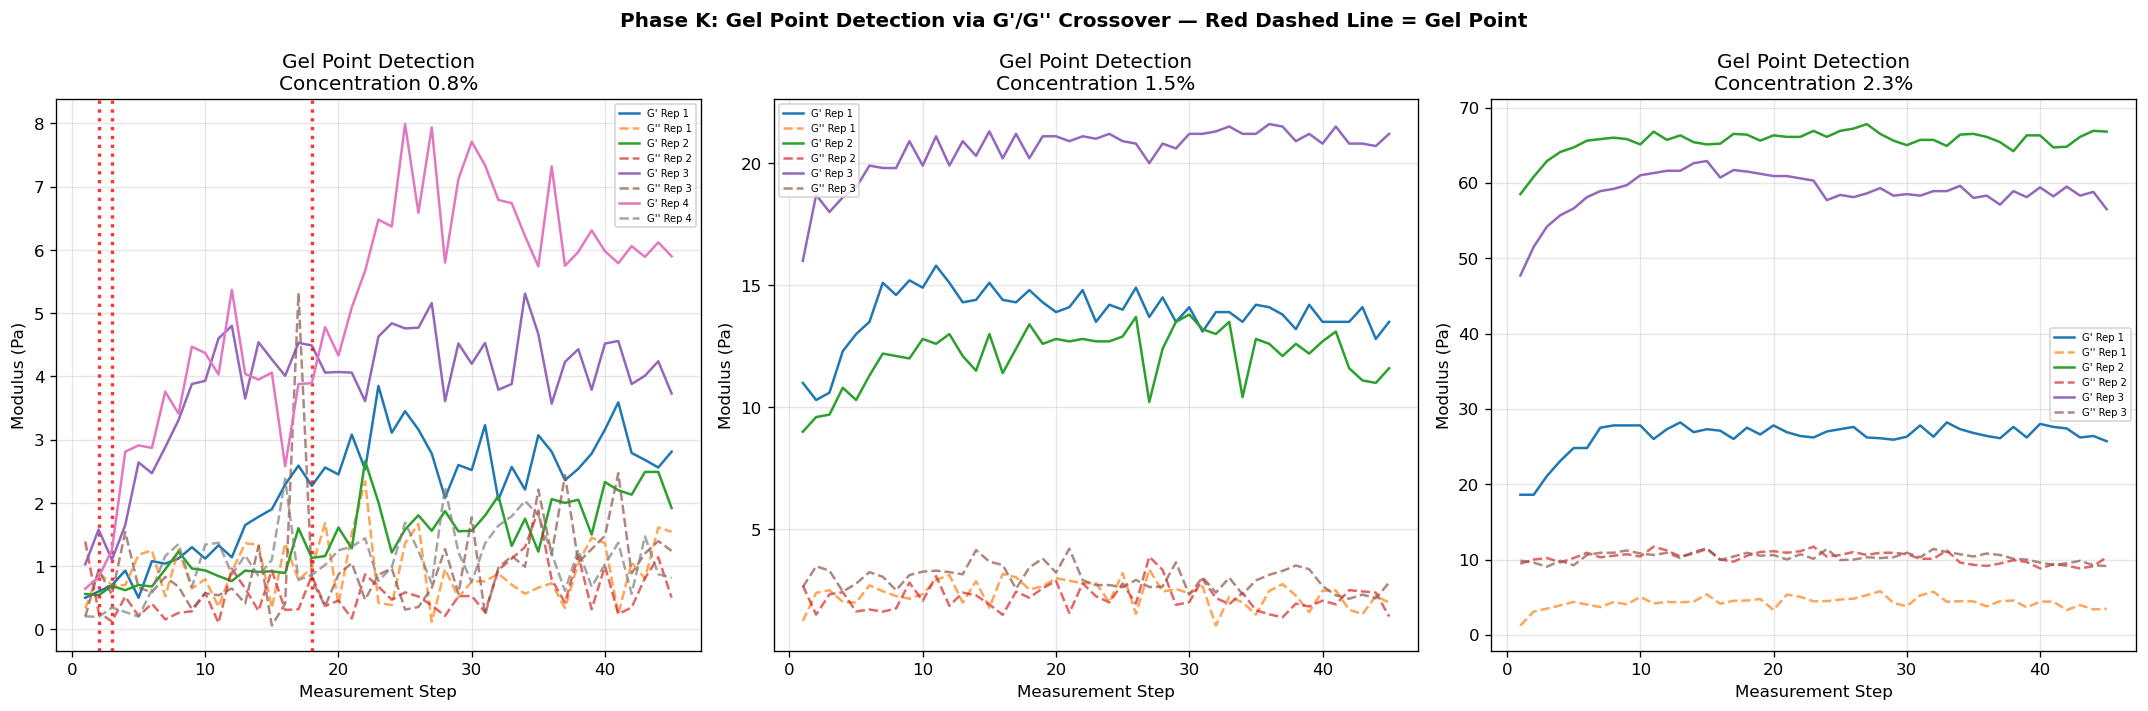

In [36]:
# ==========================================
# CELL K3: Gel Point Visualisation with Crossover Markers
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    ax = axes[column_index]
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df          = data_dictionary[concentration_key][replicate_key]['time_sweep']
        measurement_steps      = time_sweep_df['meas_pts'].values
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        loss_modulus_values    = time_sweep_df['loss_modulus_Pa'].values
        ax.plot(measurement_steps, storage_modulus_values, label=f"G' Rep {replicate_key}")
        ax.plot(measurement_steps, loss_modulus_values, linestyle='--', label=f"G'' Rep {replicate_key}", alpha=0.7)
        modulus_difference = storage_modulus_values - loss_modulus_values
        for step_index in range(1, len(modulus_difference)):
            if modulus_difference[step_index - 1] < 0 and modulus_difference[step_index] >= 0:
                ax.axvline(x=measurement_steps[step_index], color='red',
                           linestyle=':', linewidth=2.0, alpha=0.8)
                break
    ax.set_title(f"Gel Point Detection\nConcentration {concentration_key}%")
    ax.set_xlabel("Measurement Step")
    ax.set_ylabel("Modulus (Pa)")
    ax.legend(fontsize=6)
    ax.grid(True, alpha=0.3)

plt.suptitle("Phase K: Gel Point Detection via G'/G'' Crossover — Red Dashed Line = Gel Point",
             fontweight='bold')
plt.tight_layout()
plt.show()

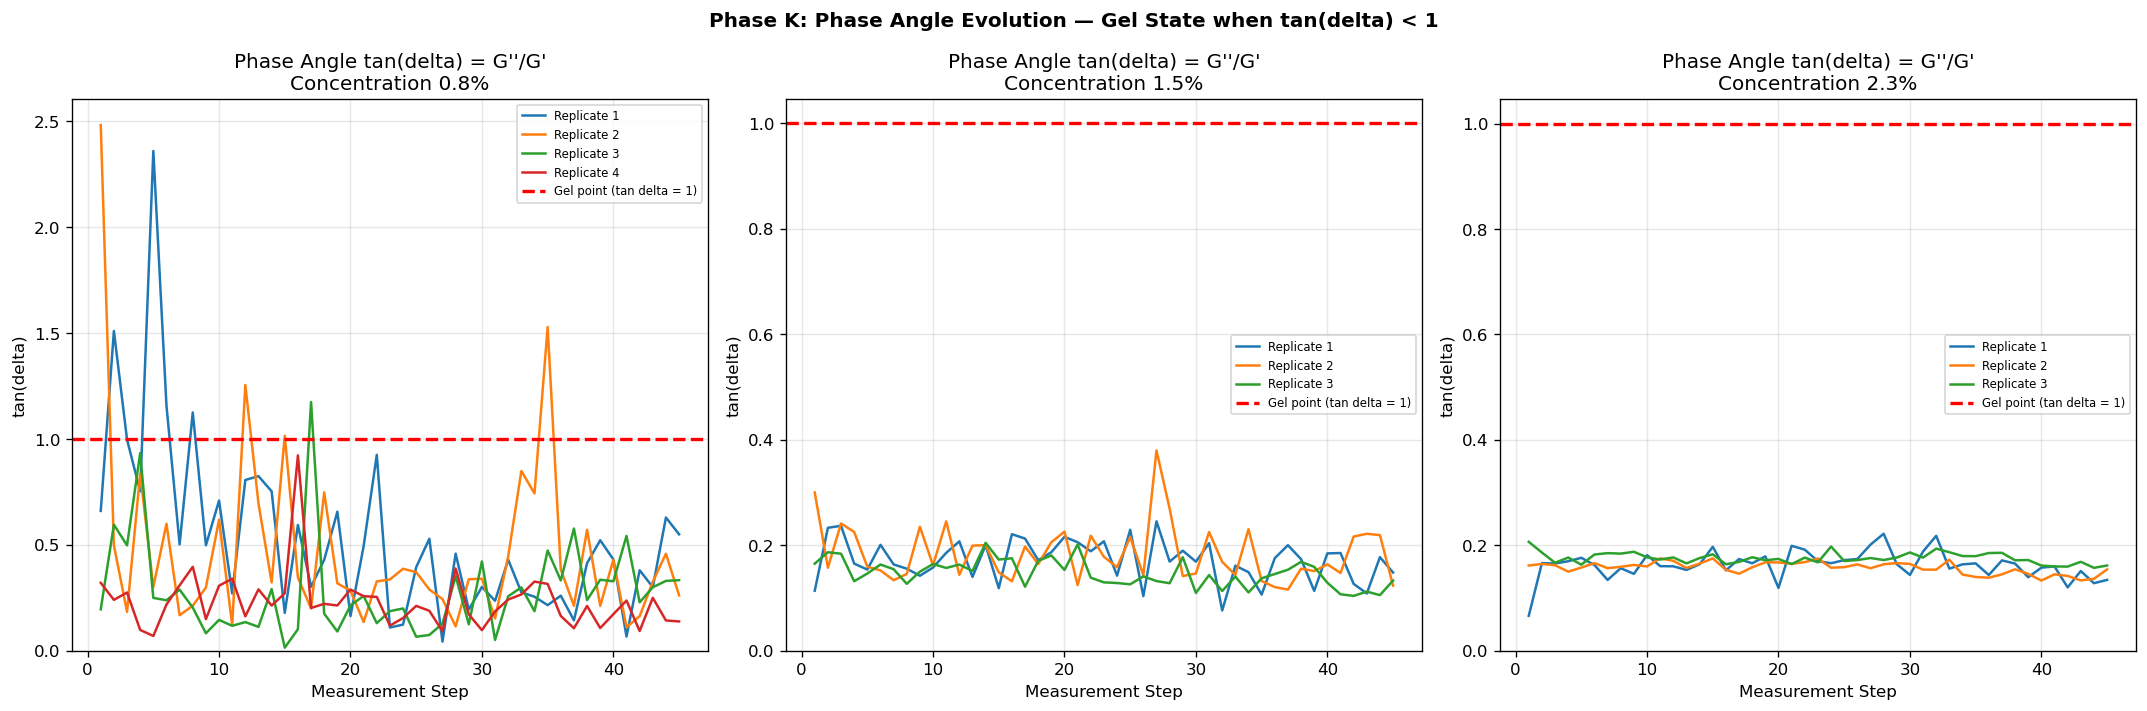

In [37]:
# ==========================================
# CELL K4: Phase Angle tan(delta) Evolution
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    ax = axes[column_index]
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        loss_modulus_values    = time_sweep_df['loss_modulus_Pa'].values
        measurement_steps      = time_sweep_df['meas_pts'].values
        tan_delta_values = loss_modulus_values / (storage_modulus_values + 1e-10)
        ax.plot(measurement_steps, tan_delta_values, label=f"Replicate {replicate_key}")
    ax.axhline(y=1.0, color='red', linestyle='--', linewidth=2.0, label="Gel point (tan delta = 1)")
    ax.set_title(f"Phase Angle tan(delta) = G''/G'\nConcentration {concentration_key}%")
    ax.set_xlabel("Measurement Step")
    ax.set_ylabel("tan(delta)")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)

plt.suptitle("Phase K: Phase Angle Evolution — Gel State when tan(delta) < 1", fontweight='bold')
plt.tight_layout()
plt.show()

In [38]:
# ==========================================
# CELL K5: Winter-Chambon Power Law Exponent Alpha
# ==========================================

print("=" * 70)
print("WINTER-CHAMBON POWER LAW EXPONENT ALPHA — FROM FREQUENCY SWEEP")
print("=" * 70)
print("At gel point: G'(omega) ~ G''(omega) ~ omega^alpha")
print("alpha = 0.5 is balanced gel. alpha < 0.5 is strong gel. alpha > 0.5 is weak gel.")
print("Reference: Hawkins et al. 2008 gelatin: alpha = 0.705")
print()
print(f"{'Conc':>6} {'Rep':>4} {'alpha G-prime':>14} {'alpha G-double-prime':>20} {'Mean alpha':>12} {'R-squared G-prime':>18}")
print("-" * 80)

alpha_by_concentration = {}
alpha_all_records = []

for concentration_key in sorted(data_dictionary):
    alpha_by_concentration[concentration_key] = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'frequency_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        freq_sweep_df = data_dictionary[concentration_key][replicate_key]['frequency_sweep']
        valid_freq_df = freq_sweep_df[
            (freq_sweep_df['storage_modulus_Pa'] > 0) &
            (freq_sweep_df['loss_modulus_Pa'] > 0)
        ].copy()
        if len(valid_freq_df) < 3:
            continue
        log_omega    = np.log(valid_freq_df['angular_freq_rad_s'].values)
        log_G_prime  = np.log(valid_freq_df['storage_modulus_Pa'].values)
        log_G_double = np.log(valid_freq_df['loss_modulus_Pa'].values)
        slope_G_prime,  _, r_G_prime,  _, _ = stats.linregress(log_omega, log_G_prime)
        slope_G_double, _, r_G_double, _, _ = stats.linregress(log_omega, log_G_double)
        mean_alpha = (slope_G_prime + slope_G_double) / 2.0
        alpha_by_concentration[concentration_key].append(mean_alpha)
        alpha_all_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'alpha G-prime': slope_G_prime,
            'alpha G-double-prime': slope_G_double,
            'Mean alpha': mean_alpha,
            'R-squared G-prime': r_G_prime ** 2
        })
        print(f"{concentration_key:>6} {replicate_key:>4} {slope_G_prime:>14.4f} {slope_G_double:>20.4f} {mean_alpha:>12.4f} {r_G_prime**2:>18.4f}")

alpha_df = pd.DataFrame(alpha_all_records)
print("\nSummary — Mean alpha per concentration:")
for concentration_key in sorted(alpha_by_concentration):
    alpha_values = alpha_by_concentration[concentration_key]
    if alpha_values:
        print(f"  Concentration {concentration_key}%: alpha = {np.mean(alpha_values):.4f} +/- {np.std(alpha_values):.4f}")

WINTER-CHAMBON POWER LAW EXPONENT ALPHA — FROM FREQUENCY SWEEP
At gel point: G'(omega) ~ G''(omega) ~ omega^alpha
alpha = 0.5 is balanced gel. alpha < 0.5 is strong gel. alpha > 0.5 is weak gel.
Reference: Hawkins et al. 2008 gelatin: alpha = 0.705

  Conc  Rep  alpha G-prime alpha G-double-prime   Mean alpha  R-squared G-prime
--------------------------------------------------------------------------------
   0.8    1         0.5756               0.0270       0.3013             0.6773
   0.8    2         0.4014               0.1608       0.2811             0.6241
   0.8    3         0.4980               0.1822       0.3401             0.7865
   0.8    4         0.2202               0.1846       0.2024             0.7487
   1.5    1         0.0932               0.0224       0.0578             0.9549
   1.5    2         0.1813               0.1442       0.1628             0.8418
   1.5    3         0.3355               0.1305       0.2330             0.7843
   2.3    1         0.1809   

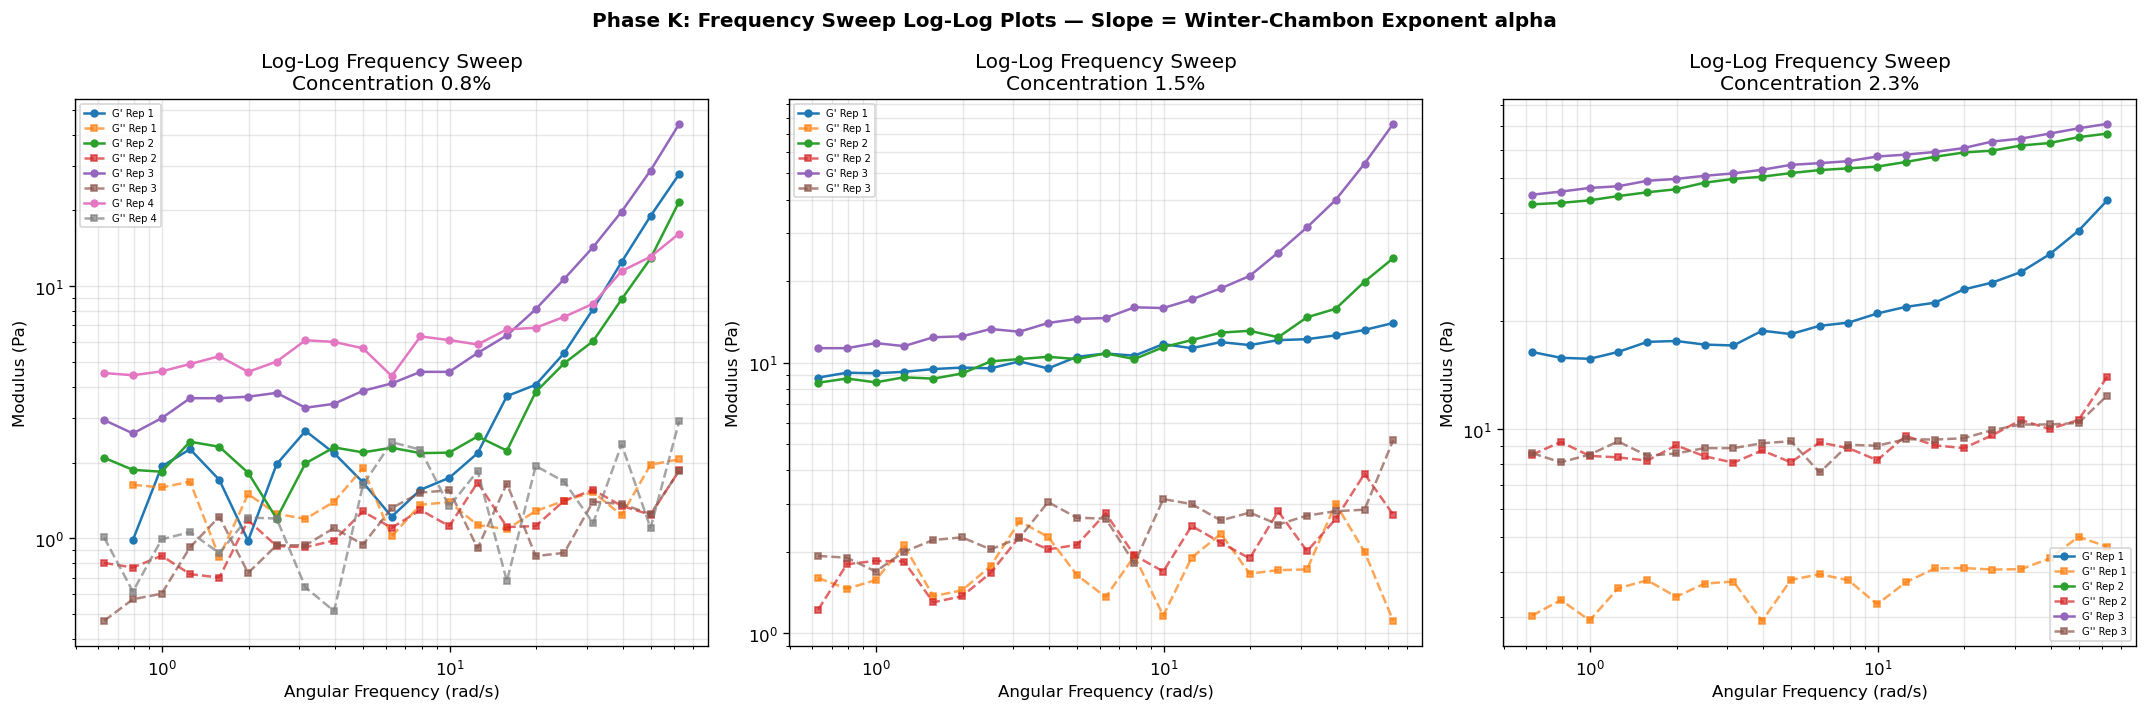

In [39]:
# ==========================================
# CELL K6: Frequency Sweep Log-Log Plots
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    ax = axes[column_index]
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'frequency_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        freq_sweep_df = data_dictionary[concentration_key][replicate_key]['frequency_sweep']
        valid_freq_df = freq_sweep_df[freq_sweep_df['storage_modulus_Pa'] > 0]
        if len(valid_freq_df) < 2:
            continue
        ax.loglog(valid_freq_df['angular_freq_rad_s'], valid_freq_df['storage_modulus_Pa'],
                  'o-', label=f"G' Rep {replicate_key}", markersize=4)
        ax.loglog(valid_freq_df['angular_freq_rad_s'], valid_freq_df['loss_modulus_Pa'],
                  's--', label=f"G'' Rep {replicate_key}", markersize=4, alpha=0.7)
    ax.set_title(f"Log-Log Frequency Sweep\nConcentration {concentration_key}%")
    ax.set_xlabel("Angular Frequency (rad/s)")
    ax.set_ylabel("Modulus (Pa)")
    ax.legend(fontsize=6)
    ax.grid(True, which='both', alpha=0.3)

plt.suptitle("Phase K: Frequency Sweep Log-Log Plots — Slope = Winter-Chambon Exponent alpha",
             fontweight='bold')
plt.tight_layout()
plt.show()

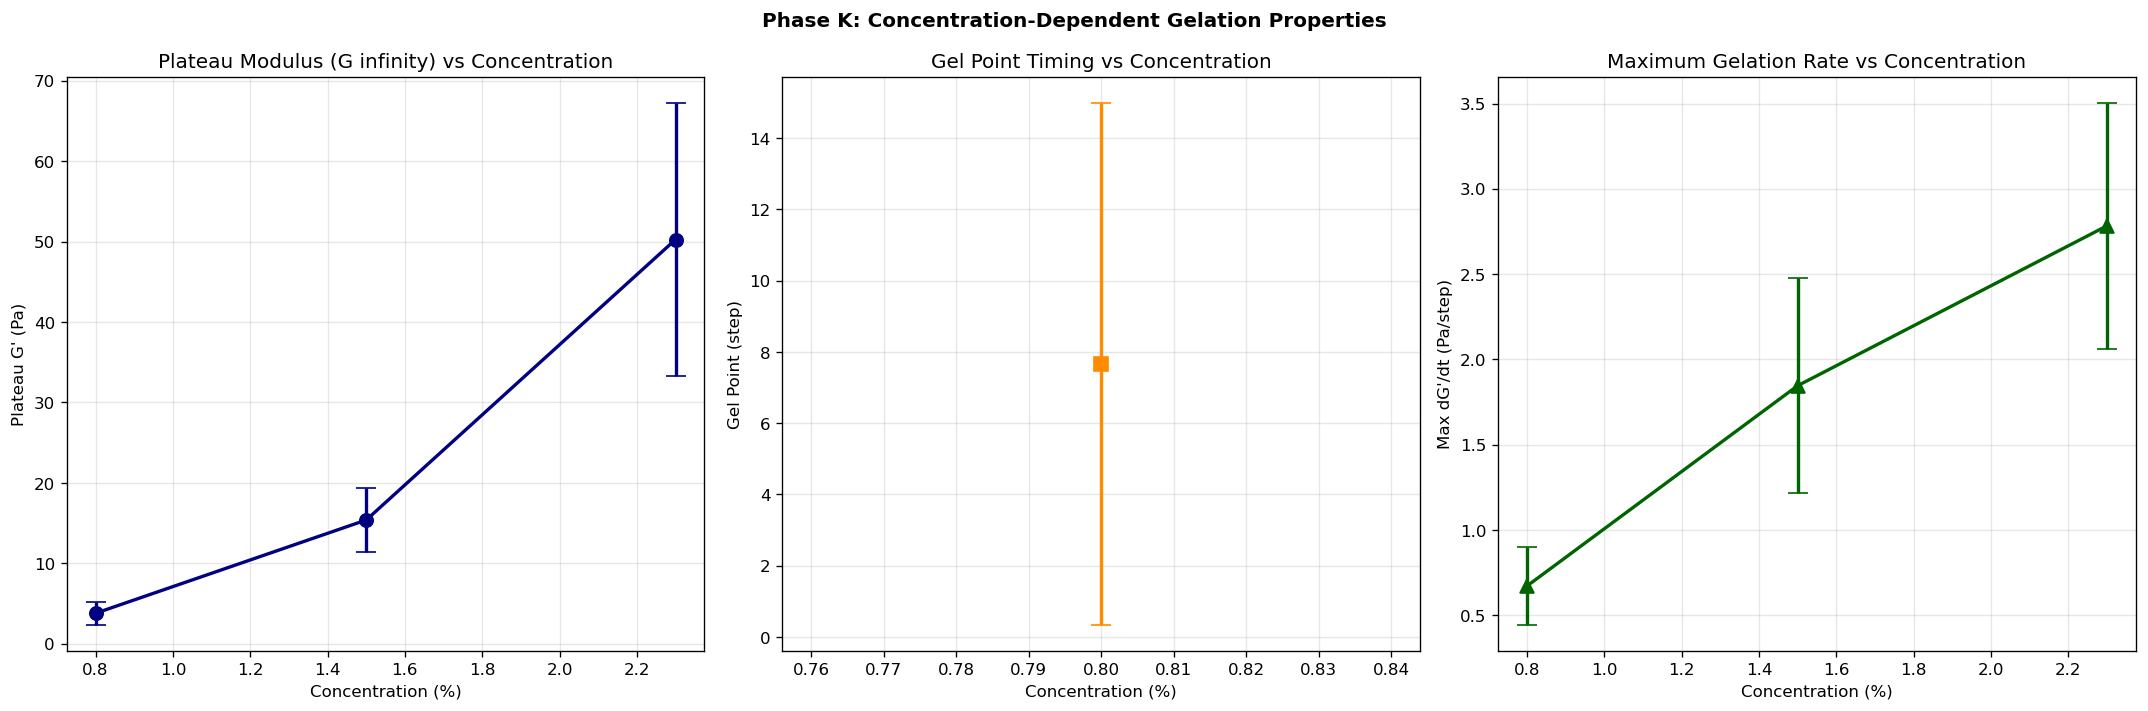

In [40]:
# ==========================================
# CELL K7: Plateau Modulus and Gelation Rate Comparison
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
concentration_float_list  = [float(c) for c in sorted(data_dictionary.keys())]
plateau_means, plateau_stds = [], []
gel_point_means, gel_point_stds = [], []
rate_means, rate_stds = [], []

for concentration_key in sorted(data_dictionary.keys()):
    plateau_values   = []
    gel_point_values = []
    rate_values      = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df          = data_dictionary[concentration_key][replicate_key]['time_sweep']
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        loss_modulus_values    = time_sweep_df['loss_modulus_Pa'].values
        measurement_steps      = time_sweep_df['meas_pts'].values
        plateau_values.append(np.mean(storage_modulus_values[-5:]))
        modulus_difference = storage_modulus_values - loss_modulus_values
        for step_index in range(1, len(modulus_difference)):
            if modulus_difference[step_index - 1] < 0 and modulus_difference[step_index] >= 0:
                gel_point_values.append(measurement_steps[step_index])
                break
        gelation_rate = np.gradient(storage_modulus_values, measurement_steps)
        rate_values.append(np.max(gelation_rate))
    plateau_means.append(np.mean(plateau_values))
    plateau_stds.append(np.std(plateau_values))
    gel_point_means.append(np.mean(gel_point_values) if gel_point_values else np.nan)
    gel_point_stds.append(np.std(gel_point_values)   if gel_point_values else np.nan)
    rate_means.append(np.mean(rate_values))
    rate_stds.append(np.std(rate_values))

axes[0].errorbar(concentration_float_list, plateau_means, yerr=plateau_stds,
                 fmt='o-', capsize=6, linewidth=2, markersize=8, color='navy')
axes[0].set_xlabel("Concentration (%)")
axes[0].set_ylabel("Plateau G' (Pa)")
axes[0].set_title("Plateau Modulus (G infinity) vs Concentration")
axes[0].grid(True, alpha=0.3)

axes[1].errorbar(concentration_float_list, gel_point_means, yerr=gel_point_stds,
                 fmt='s-', capsize=6, linewidth=2, markersize=8, color='darkorange')
axes[1].set_xlabel("Concentration (%)")
axes[1].set_ylabel("Gel Point (step)")
axes[1].set_title("Gel Point Timing vs Concentration")
axes[1].grid(True, alpha=0.3)

axes[2].errorbar(concentration_float_list, rate_means, yerr=rate_stds,
                 fmt='^-', capsize=6, linewidth=2, markersize=8, color='darkgreen')
axes[2].set_xlabel("Concentration (%)")
axes[2].set_ylabel("Max dG'/dt (Pa/step)")
axes[2].set_title("Maximum Gelation Rate vs Concentration")
axes[2].grid(True, alpha=0.3)

plt.suptitle("Phase K: Concentration-Dependent Gelation Properties", fontweight='bold')
plt.tight_layout()
plt.show()

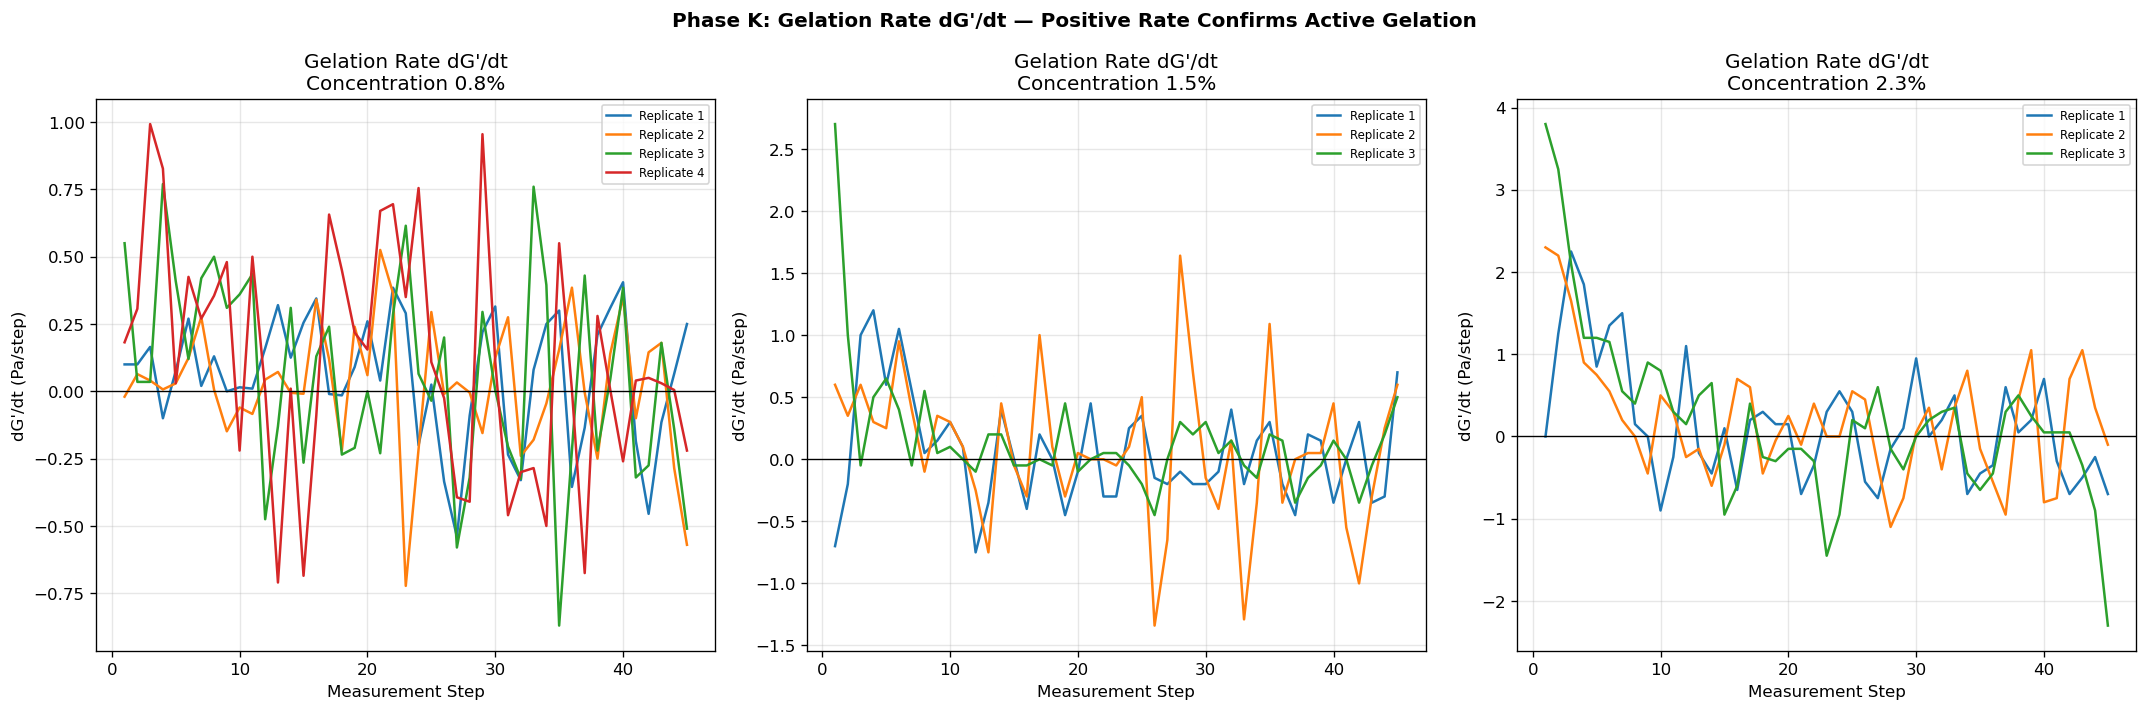

Maximum Gelation Rate Summary:
  Concentration 0.8%: max dG'/dt = 0.67313 +/- 0.22650 Pa/step
  Concentration 1.5%: max dG'/dt = 1.84667 +/- 0.62957 Pa/step
  Concentration 2.3%: max dG'/dt = 2.78333 +/- 0.71918 Pa/step


In [41]:
# ==========================================
# CELL K8: Gelation Rate dG'/dt — All Files
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

gelation_rate_by_concentration = {}

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    ax = axes[column_index]
    gelation_rate_by_concentration[concentration_key] = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        measurement_steps      = time_sweep_df['meas_pts'].values
        gelation_rate_values   = np.gradient(storage_modulus_values, measurement_steps)
        gelation_rate_by_concentration[concentration_key].append(np.max(gelation_rate_values))
        ax.plot(measurement_steps, gelation_rate_values, label=f"Replicate {replicate_key}")
    ax.axhline(y=0.0, color='black', linewidth=0.8, linestyle='-')
    ax.set_title(f"Gelation Rate dG'/dt\nConcentration {concentration_key}%")
    ax.set_xlabel("Measurement Step")
    ax.set_ylabel("dG'/dt (Pa/step)")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle("Phase K: Gelation Rate dG'/dt — Positive Rate Confirms Active Gelation", fontweight='bold')
plt.tight_layout()
plt.show()

print("Maximum Gelation Rate Summary:")
for concentration_key in sorted(gelation_rate_by_concentration):
    rate_list = gelation_rate_by_concentration[concentration_key]
    print(f"  Concentration {concentration_key}%: max dG'/dt = {np.mean(rate_list):.5f} +/- {np.std(rate_list):.5f} Pa/step")

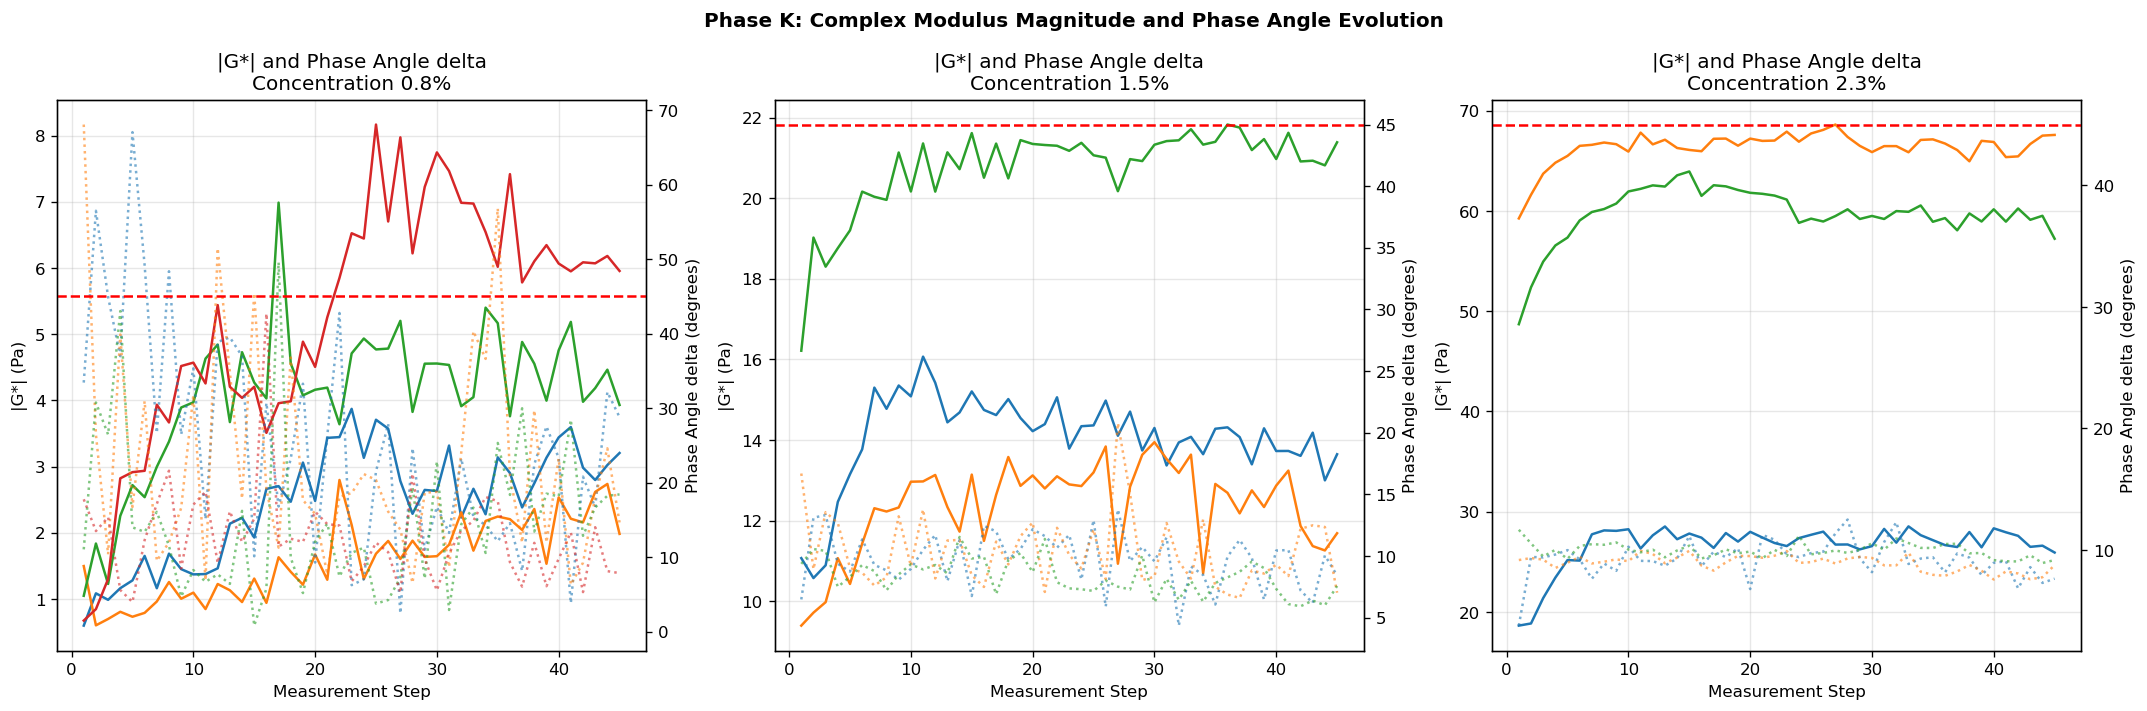

In [42]:
# ==========================================
# CELL K9: Complex Modulus Magnitude and Phase Angle Delta
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    ax_primary   = axes[column_index]
    ax_secondary = ax_primary.twinx()
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df          = data_dictionary[concentration_key][replicate_key]['time_sweep']
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        loss_modulus_values    = time_sweep_df['loss_modulus_Pa'].values
        measurement_steps      = time_sweep_df['meas_pts'].values
        complex_modulus_magnitude = np.sqrt(storage_modulus_values**2 + loss_modulus_values**2)
        phase_angle_degrees = np.degrees(np.arctan2(loss_modulus_values, storage_modulus_values))
        ax_primary.plot(measurement_steps, complex_modulus_magnitude,
                        label=f"|G*| Rep {replicate_key}", linewidth=1.5)
        ax_secondary.plot(measurement_steps, phase_angle_degrees,
                          linestyle=':', alpha=0.6, label=f"delta Rep {replicate_key}")
    ax_secondary.axhline(y=45.0, color='red', linestyle='--', linewidth=1.5,
                         label="delta = 45 degrees (balanced)")
    ax_primary.set_title(f"|G*| and Phase Angle delta\nConcentration {concentration_key}%")
    ax_primary.set_xlabel("Measurement Step")
    ax_primary.set_ylabel("|G*| (Pa)")
    ax_secondary.set_ylabel("Phase Angle delta (degrees)")
    ax_primary.grid(True, alpha=0.3)

plt.suptitle("Phase K: Complex Modulus Magnitude and Phase Angle Evolution", fontweight='bold')
plt.tight_layout()
plt.show()

## PHASE L — Mutation Number Framework

In [43]:
# ==========================================
# CELL L1: Mutation Number Calculation — All 10 Time Sweep Files
# ==========================================
# N_mu = (T / G) * (dG/dt)
# T = measurement period = 1 second (at 1 Hz = 6.28 rad/s)
# Threshold = 0.15 (Mours and Winter 1994)
# Phase 1 pass criterion: >= 80% of windows below 0.15

print("=" * 70)
print("MUTATION NUMBER N_mu — ALL TIME SWEEP FILES")
print("=" * 70)
print(f"Measurement period T = {MEASUREMENT_PERIOD_SECONDS} s | Threshold = {MUTATION_NUMBER_THRESHOLD}")
print()
print(f"{'Conc':>6} {'Rep':>4} {'Max N_mu':>10} {'Mean N_mu':>10} {'Pct below 0.15':>16} {'Phase 1':>8}")
print("-" * 62)

mutation_number_by_concentration  = {}
mutation_number_all_records = []

for concentration_key in sorted(data_dictionary):
    mutation_number_by_concentration[concentration_key] = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        measurement_steps      = time_sweep_df['meas_pts'].values
        safe_G_values = np.where(storage_modulus_values < 0.01, 0.01, storage_modulus_values)
        dG_dt_values  = np.gradient(storage_modulus_values, measurement_steps)
        mutation_number_values = (MEASUREMENT_PERIOD_SECONDS / safe_G_values) * np.abs(dG_dt_values)
        mutation_number_by_concentration[concentration_key].append(mutation_number_values)
        max_N_mu  = np.max(mutation_number_values)
        mean_N_mu = np.mean(mutation_number_values)
        pct_below = np.mean(mutation_number_values < MUTATION_NUMBER_THRESHOLD) * 100.0
        phase1_pass = "PASS" if pct_below >= 80.0 else "FAIL"
        mutation_number_all_records.append({
            'Concentration': concentration_key,
            'Replicate': replicate_key,
            'Max N_mu': max_N_mu,
            'Mean N_mu': mean_N_mu,
            'Pct below 0.15': pct_below,
            'Phase 1': phase1_pass
        })
        print(f"{concentration_key:>6} {replicate_key:>4} {max_N_mu:>10.4f} {mean_N_mu:>10.4f} {pct_below:>15.1f}% {phase1_pass:>8}")

mutation_number_df = pd.DataFrame(mutation_number_all_records)
print("\nSummary by concentration:")
for concentration_key in sorted(mutation_number_by_concentration):
    all_N_mu_values = np.concatenate(mutation_number_by_concentration[concentration_key])
    overall_pct     = np.mean(all_N_mu_values < MUTATION_NUMBER_THRESHOLD) * 100.0
    overall_pass    = "PASS" if overall_pct >= 80.0 else "FAIL"
    print(f"  Concentration {concentration_key}%: {overall_pct:.1f}% below 0.15 — Phase 1 {overall_pass}")

MUTATION NUMBER N_mu — ALL TIME SWEEP FILES
Measurement period T = 1.0 s | Threshold = 0.15

  Conc  Rep   Max N_mu  Mean N_mu   Pct below 0.15  Phase 1
--------------------------------------------------------------
   0.8    1     0.2500     0.0961            75.6%     FAIL
   0.8    2     0.4102     0.1176            68.9%     FAIL
   0.8    3     0.5340     0.0917            86.7%     PASS
   0.8    4     0.7902     0.0980            84.4%     PASS
   1.5    1     0.0976     0.0253           100.0%     PASS
   1.5    2     0.1323     0.0363           100.0%     PASS
   1.5    3     0.1687     0.0133            97.8%     PASS
   2.3    1     0.1066     0.0216           100.0%     PASS
   2.3    2     0.0393     0.0088           100.0%     PASS
   2.3    3     0.0797     0.0123           100.0%     PASS

Summary by concentration:
  Concentration 0.8%: 78.9% below 0.15 — Phase 1 FAIL
  Concentration 1.5%: 99.3% below 0.15 — Phase 1 PASS
  Concentration 2.3%: 100.0% below 0.15 — Phase 1

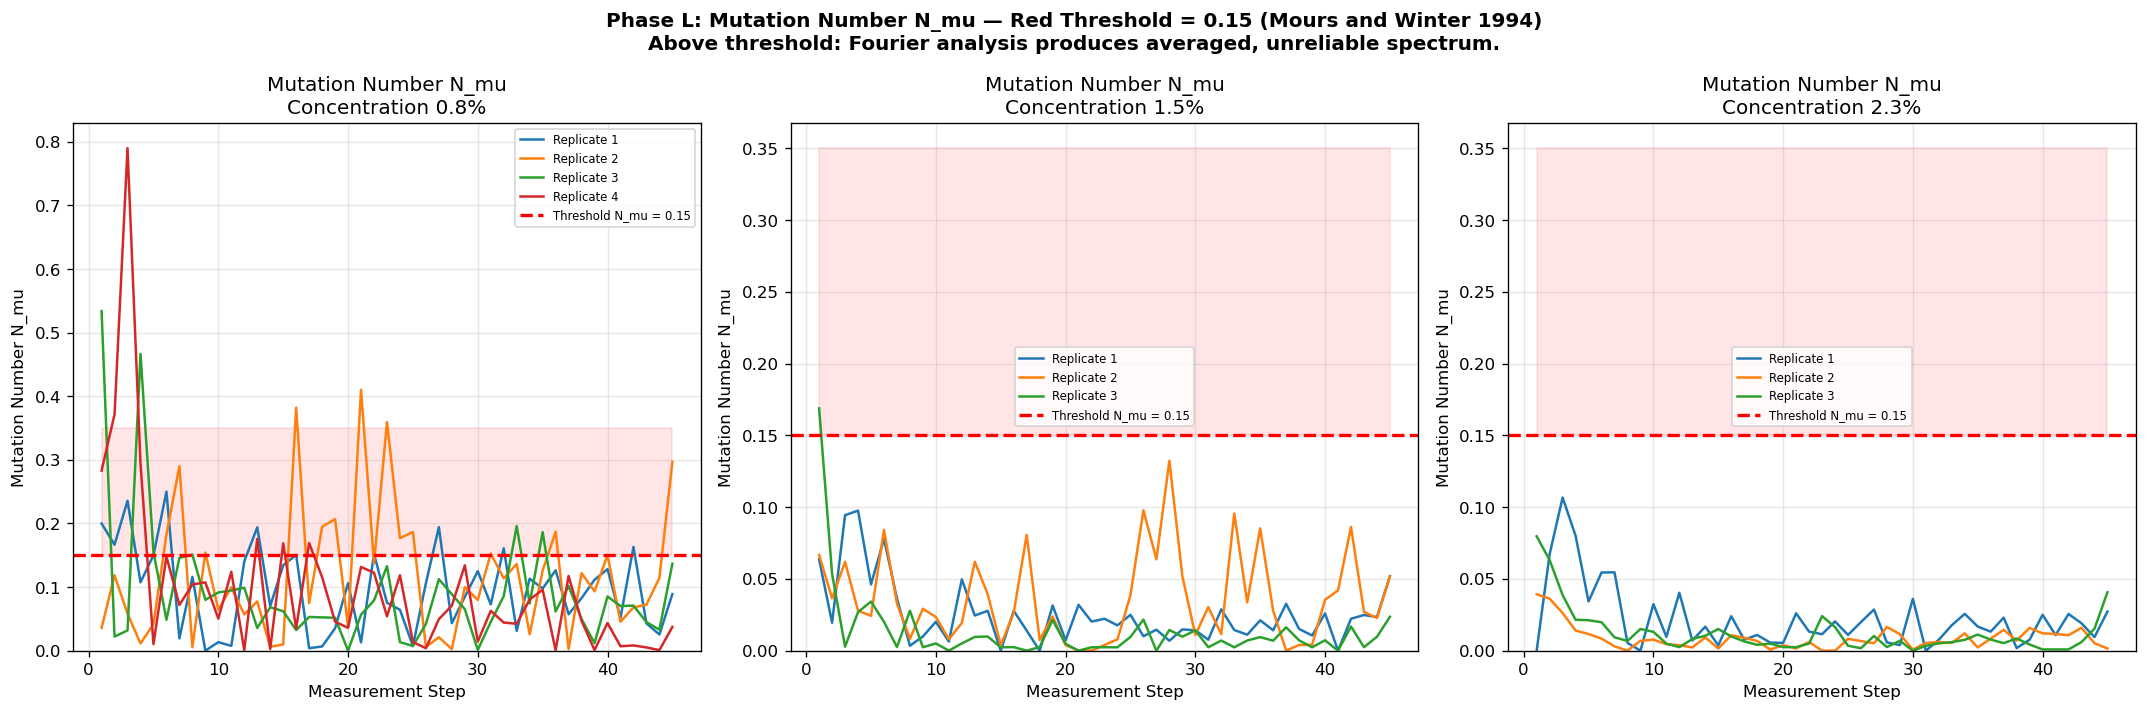

In [44]:
# ==========================================
# CELL L2: Mutation Number Time Evolution — All Concentrations
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    ax = axes[column_index]
    for rep_index, replicate_key in enumerate(sorted(data_dictionary[concentration_key])):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        measurement_steps      = time_sweep_df['meas_pts'].values
        safe_G_values  = np.where(storage_modulus_values < 0.01, 0.01, storage_modulus_values)
        dG_dt_values   = np.gradient(storage_modulus_values, measurement_steps)
        N_mu_values    = (MEASUREMENT_PERIOD_SECONDS / safe_G_values) * np.abs(dG_dt_values)
        ax.plot(measurement_steps, N_mu_values, label=f"Replicate {replicate_key}", linewidth=1.5)
    ax.axhline(y=MUTATION_NUMBER_THRESHOLD, color='red', linestyle='--', linewidth=2.0,
               label=f"Threshold N_mu = {MUTATION_NUMBER_THRESHOLD}")
    ax.fill_between(measurement_steps if 'measurement_steps' in dir() else np.arange(45),
                    MUTATION_NUMBER_THRESHOLD, 0.35, alpha=0.1, color='red')
    ax.set_title(f"Mutation Number N_mu\nConcentration {concentration_key}%")
    ax.set_xlabel("Measurement Step")
    ax.set_ylabel("Mutation Number N_mu")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)

plt.suptitle("Phase L: Mutation Number N_mu — Red Threshold = 0.15 (Mours and Winter 1994)\n"
             "Above threshold: Fourier analysis produces averaged, unreliable spectrum.",
             fontweight='bold')
plt.tight_layout()
plt.show()

In [45]:
# ==========================================
# CELL L3: Phase 1 Compliance Summary Table
# ==========================================

print("=" * 70)
print("PHASE 1 COMPLIANCE SUMMARY — MUTATION NUMBER CRITERION")
print("=" * 70)
print("Requirement: >= 80% of measurement windows must have N_mu < 0.15")
print("This confirms the LTI assumption is not catastrophically violated.")
print()

phase1_summary_records = []

for concentration_key in sorted(mutation_number_by_concentration):
    all_N_mu_concat  = np.concatenate(mutation_number_by_concentration[concentration_key])
    n_total          = len(all_N_mu_concat)
    n_below_threshold = np.sum(all_N_mu_concat < MUTATION_NUMBER_THRESHOLD)
    n_violations     = n_total - n_below_threshold
    pct_compliant    = (n_below_threshold / n_total) * 100.0
    phase1_result    = "PASS" if pct_compliant >= 80.0 else "FAIL"
    phase1_summary_records.append({
        'Concentration (%)': concentration_key,
        'Total Windows': n_total,
        'Windows Below 0.15': n_below_threshold,
        'Violations': n_violations,
        'Compliance (%)': round(pct_compliant, 1),
        'Phase 1 Result': phase1_result
    })

phase1_summary_df = pd.DataFrame(phase1_summary_records)
print(phase1_summary_df.to_string(index=False))
print("\nConsequences of Phase 1 result:")
print("  PASS: Algorithm may proceed to Phase 2 tradeoff analysis.")
print("  FAIL: Algorithm is eliminated from further consideration.")
print("  Marginal FAIL (close to 80%): Note as boundary case, adjust window duration.")

PHASE 1 COMPLIANCE SUMMARY — MUTATION NUMBER CRITERION
Requirement: >= 80% of measurement windows must have N_mu < 0.15
This confirms the LTI assumption is not catastrophically violated.

Concentration (%)  Total Windows  Windows Below 0.15  Violations  Compliance (%) Phase 1 Result
              0.8            180                 142          38            78.9           FAIL
              1.5            135                 134           1            99.3           PASS
              2.3            135                 135           0           100.0           PASS

Consequences of Phase 1 result:
  PASS: Algorithm may proceed to Phase 2 tradeoff analysis.
  FAIL: Algorithm is eliminated from further consideration.
  Marginal FAIL (close to 80%): Note as boundary case, adjust window duration.


## PHASE O — Feature Stability and Robustness

In [46]:
# ==========================================
# CELL O1: Replicate Consistency — Coefficient of Variation
# ==========================================

def compute_coefficient_of_variation(values_array):
    values_array = np.array(values_array)
    if len(values_array) == 0 or np.mean(values_array) == 0:
        return None
    return (np.std(values_array) / np.mean(values_array)) * 100.0

print("=" * 80)
print("REPLICATE CONSISTENCY — COEFFICIENT OF VARIATION (CV%)")
print("=" * 80)
print("CV < 10% indicates good reproducibility. CV > 20% indicates high variability.")
print()
print(f"{'Conc':>6} {'Metric':>25} {'Mean':>10} {'Std':>10} {'CV (%)':>8} {'Assessment':>14}")
print("-" * 80)

cv_records = []

for concentration_key in sorted(data_dictionary):
    plateau_values    = []
    gel_point_values  = []
    max_rate_values   = []
    entropy_values    = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        loss_modulus_values    = time_sweep_df['loss_modulus_Pa'].values
        measurement_steps      = time_sweep_df['meas_pts'].values
        plateau_values.append(np.mean(storage_modulus_values[-5:]))
        modulus_difference = storage_modulus_values - loss_modulus_values
        for step_index in range(1, len(modulus_difference)):
            if modulus_difference[step_index - 1] < 0 and modulus_difference[step_index] >= 0:
                gel_point_values.append(measurement_steps[step_index])
                break
        gelation_rate = np.gradient(storage_modulus_values, measurement_steps)
        max_rate_values.append(np.max(gelation_rate))
        entropy_values.append(compute_shannon_entropy(storage_modulus_values))

    for metric_label, metric_values in [
        ("Plateau G' (Pa)", plateau_values),
        ("Gel Point Step", gel_point_values),
        ("Max dG'/dt", max_rate_values),
        ("Shannon Entropy G'", entropy_values)
    ]:
        if len(metric_values) >= 2:
            mean_value = np.mean(metric_values)
            std_value  = np.std(metric_values)
            cv_value   = compute_coefficient_of_variation(metric_values)
            assessment = ("Good" if cv_value and cv_value < 10
                          else ("Acceptable" if cv_value and cv_value < 20
                                else "High variability"))
            cv_records.append({
                'Concentration': concentration_key,
                'Metric': metric_label,
                'Mean': mean_value,
                'Std': std_value,
                'CV (%)': cv_value
            })
            cv_str = f"{cv_value:.1f}" if cv_value else "N/A"
            print(f"{concentration_key:>6} {metric_label:>25} {mean_value:>10.4f} {std_value:>10.4f} {cv_str:>8} {assessment:>14}")

cv_df = pd.DataFrame(cv_records)

REPLICATE CONSISTENCY — COEFFICIENT OF VARIATION (CV%)
CV < 10% indicates good reproducibility. CV > 20% indicates high variability.

  Conc                    Metric       Mean        Std   CV (%)     Assessment
--------------------------------------------------------------------------------
   0.8           Plateau G' (Pa)     3.7920     1.4108     37.2 High variability
   0.8            Gel Point Step     7.6667     7.3182     95.5 High variability
   0.8                Max dG'/dt     0.6731     0.2265     33.6 High variability
   0.8        Shannon Entropy G'     3.7911     0.4782     12.6     Acceptable
   1.5           Plateau G' (Pa)    15.3867     4.0367     26.2 High variability
   1.5                Max dG'/dt     1.8467     0.6296     34.1 High variability
   1.5        Shannon Entropy G'     3.2393     0.5402     16.7     Acceptable
   2.3           Plateau G' (Pa)    50.2600    16.9737     33.8 High variability
   2.3                Max dG'/dt     2.7833     0.7192     25.

In [47]:
# ==========================================
# CELL O2: Concentration Sensitivity — Feature vs Concentration Correlations
# ==========================================

print("=" * 70)
print("CONCENTRATION SENSITIVITY — PEARSON CORRELATION")
print("=" * 70)
print("Testing: does higher concentration consistently produce expected gelation behaviour?")
print()

concentration_float_values = []
mean_plateau_G_prime_per_conc  = []
mean_gel_point_step_per_conc   = []
mean_max_rate_per_conc         = []
mean_alpha_per_conc            = []

for concentration_key in sorted(data_dictionary.keys()):
    plateau_list   = []
    gel_point_list = []
    rate_list      = []
    alpha_list     = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' in data_dictionary[concentration_key][replicate_key]:
            df = data_dictionary[concentration_key][replicate_key]['time_sweep']
            Gp = df['storage_modulus_Pa'].values
            Gpp = df['loss_modulus_Pa'].values
            t  = df['meas_pts'].values
            plateau_list.append(np.mean(Gp[-5:]))
            diff = Gp - Gpp
            for i in range(1, len(diff)):
                if diff[i-1] < 0 and diff[i] >= 0:
                    gel_point_list.append(t[i])
                    break
            rate_list.append(np.max(np.gradient(Gp, t)))
        if 'frequency_sweep' in data_dictionary[concentration_key][replicate_key]:
            df_f = data_dictionary[concentration_key][replicate_key]['frequency_sweep']
            valid_df = df_f[df_f['storage_modulus_Pa'] > 0]
            if len(valid_df) >= 3:
                slope, *_ = stats.linregress(
                    np.log(valid_df['angular_freq_rad_s']),
                    np.log(valid_df['storage_modulus_Pa'])
                )
                alpha_list.append(slope)
    concentration_float_values.append(float(concentration_key))
    mean_plateau_G_prime_per_conc.append(np.mean(plateau_list) if plateau_list else np.nan)
    mean_gel_point_step_per_conc.append(np.mean(gel_point_list) if gel_point_list else np.nan)
    mean_max_rate_per_conc.append(np.mean(rate_list) if rate_list else np.nan)
    mean_alpha_per_conc.append(np.mean(alpha_list) if alpha_list else np.nan)

conc_array = np.array(concentration_float_values)

for feature_name, feature_values, expected_direction in [
    ("Plateau G' (Pa)", mean_plateau_G_prime_per_conc, "Positive"),
    ("Mean Gel Point Step", mean_gel_point_step_per_conc, "Negative"),
    ("Max dG'/dt", mean_max_rate_per_conc, "Positive"),
    ("Mean alpha", mean_alpha_per_conc, "Negative")
]:
    clean_indices = [i for i, v in enumerate(feature_values) if not np.isnan(v)]
    if len(clean_indices) >= 2:
        x_values = conc_array[clean_indices]
        y_values = np.array(feature_values)[clean_indices]
        pearson_r, p_value = pearsonr(x_values, y_values)
        significance = "Significant" if p_value < 0.05 else "Not significant"
        print(f"Feature: {feature_name:<28} | r = {pearson_r:>6.3f} | p = {p_value:.4f} | {significance} | Expected: {expected_direction}")

CONCENTRATION SENSITIVITY — PEARSON CORRELATION
Testing: does higher concentration consistently produce expected gelation behaviour?

Feature: Plateau G' (Pa)              | r =  0.971 | p = 0.1547 | Not significant | Expected: Positive
Feature: Max dG'/dt                   | r =  0.995 | p = 0.0657 | Not significant | Expected: Positive
Feature: Mean alpha                   | r = -0.954 | p = 0.1946 | Not significant | Expected: Negative


## PHASE R — Algorithm Scoring System

In [48]:
# ==========================================
# CELL R1: Comprehensive Algorithm Comparison Table
# ==========================================

print("=" * 100)
print("ALGORITHM COMPARISON TABLE — DATA 4 BOVINE COLLAGEN")
print("=" * 100)
print("This table documents what each signal processing method can and cannot achieve on this dataset.")
print()

comparison_data = {
    'Criterion': [
        'Applicable to processed G(t)',
        'Applicable to raw stress-strain',
        'Sampling rate requirement met',
        'Gel point detection',
        'Winter-Chambon alpha',
        'Mutation number estimation',
        'Time-frequency resolution',
        'Harmonic content detection',
        'Non-stationary signal handling',
        'Computational efficiency',
        'FPGA implementable',
        'Open source tools available',
    ],
    'FFT': [
        'Limited (45-point signal)',
        'Not available in Data 4',
        'Fails (1 Hz << 100 Hz needed)',
        'Indirectly via G(t) spectrum',
        'Yes from frequency sweep',
        'Via dG/dt from G(t)',
        'Fixed (no time resolution)',
        'Not possible without raw signal',
        'Cannot handle (stationarity assumed)',
        'Very fast O(N log N)',
        'Yes',
        'numpy.fft, scipy.fft',
    ],
    'STFT': [
        'Limited (45-point signal)',
        'Not available in Data 4',
        'Fails (1 Hz << 100 Hz needed)',
        'Via time-frequency map',
        'Not directly',
        'Via sliding window',
        'Fixed resolution (Heisenberg limited)',
        'Not possible without raw signal',
        'Partial (fixed window)',
        'Fast O(N log N per window)',
        'Yes',
        'scipy.signal.stft',
    ],
    'CWT': [
        'Applicable on G(t) time series',
        'Not available in Data 4',
        'Partial (45 points is low)',
        'Via scalogram energy localisation',
        'Not directly',
        'Via time-localised energy',
        'Adaptive (best of three methods)',
        'Not possible without raw signal',
        'Designed for non-stationary signals',
        'Moderate O(N * n_scales)',
        'Challenging (real-time)',
        'pycwt, scipy.signal.cwt',
    ]
}

comparison_df = pd.DataFrame(comparison_data)
comparison_df_transposed = comparison_df.set_index('Criterion').T
print(comparison_df_transposed.to_string())

ALGORITHM COMPARISON TABLE — DATA 4 BOVINE COLLAGEN
This table documents what each signal processing method can and cannot achieve on this dataset.

Criterion    Applicable to processed G(t) Applicable to raw stress-strain  Sampling rate requirement met                Gel point detection      Winter-Chambon alpha Mutation number estimation              Time-frequency resolution       Harmonic content detection        Non-stationary signal handling    Computational efficiency       FPGA implementable Open source tools available
FFT             Limited (45-point signal)         Not available in Data 4  Fails (1 Hz << 100 Hz needed)       Indirectly via G(t) spectrum  Yes from frequency sweep        Via dG/dt from G(t)             Fixed (no time resolution)  Not possible without raw signal  Cannot handle (stationarity assumed)        Very fast O(N log N)                      Yes        numpy.fft, scipy.fft
STFT            Limited (45-point signal)         Not available in Data 4  Fails (1

In [49]:
# ==========================================
# CELL R2: Quantitative Scoring Matrix
# ==========================================

scoring_criteria = [
    'Gel point accuracy',
    'Frequency resolution',
    'Time resolution',
    'Non-stationary handling',
    'Harmonic detection',
    'Noise robustness',
    'Computational speed',
    'FPGA feasibility',
]

scoring_values = {
    'FFT': [3, 5, 1, 1, 1, 3, 5, 5],
    'STFT': [3, 3, 3, 3, 1, 3, 4, 4],
    'CWT': [4, 4, 5, 5, 2, 4, 3, 2],
}

scoring_weights = {
    'Gel point accuracy': 0.25,
    'Frequency resolution': 0.10,
    'Time resolution': 0.15,
    'Non-stationary handling': 0.20,
    'Harmonic detection': 0.10,
    'Noise robustness': 0.10,
    'Computational speed': 0.05,
    'FPGA feasibility': 0.05,
}

print("=" * 70)
print("QUANTITATIVE SCORING MATRIX (Score: 1 = Poor, 5 = Excellent)")
print("=" * 70)
print(f"{'Criterion':<28} {'Weight':>8} {'FFT':>6} {'STFT':>6} {'CWT':>6}")
print("-" * 60)

weighted_totals = {'FFT': 0.0, 'STFT': 0.0, 'CWT': 0.0}

for criterion_index, criterion_name in enumerate(scoring_criteria):
    weight = scoring_weights[criterion_name]
    fft_score  = scoring_values['FFT'][criterion_index]
    stft_score = scoring_values['STFT'][criterion_index]
    cwt_score  = scoring_values['CWT'][criterion_index]
    weighted_totals['FFT']  += weight * fft_score
    weighted_totals['STFT'] += weight * stft_score
    weighted_totals['CWT']  += weight * cwt_score
    print(f"{criterion_name:<28} {weight:>8.2f} {fft_score:>6} {stft_score:>6} {cwt_score:>6}")

print("-" * 60)
print(f"{'WEIGHTED TOTAL':<28} {'1.00':>8} {weighted_totals['FFT']:>6.2f} {weighted_totals['STFT']:>6.2f} {weighted_totals['CWT']:>6.2f}")
print()
winner = max(weighted_totals, key=weighted_totals.get)
print(f"Highest scoring method on this dataset: {winner} ({weighted_totals[winner]:.2f}/5.00)")
print()
print("Note: These weights are indicative only and will be finalised in consultation with")
print("Dr Ragil Krishna (Haemograph) after Semester 1 stakeholder analysis.")

QUANTITATIVE SCORING MATRIX (Score: 1 = Poor, 5 = Excellent)
Criterion                      Weight    FFT   STFT    CWT
------------------------------------------------------------
Gel point accuracy               0.25      3      3      4
Frequency resolution             0.10      5      3      4
Time resolution                  0.15      1      3      5
Non-stationary handling          0.20      1      3      5
Harmonic detection               0.10      1      1      2
Noise robustness                 0.10      3      3      4
Computational speed              0.05      5      4      3
FPGA feasibility                 0.05      5      4      2
------------------------------------------------------------
WEIGHTED TOTAL                   1.00   2.50   2.90   4.00

Highest scoring method on this dataset: CWT (4.00/5.00)

Note: These weights are indicative only and will be finalised in consultation with
Dr Ragil Krishna (Haemograph) after Semester 1 stakeholder analysis.


## PHASE S — Failure Mode Analysis: Demonstrating Fourier Limitations

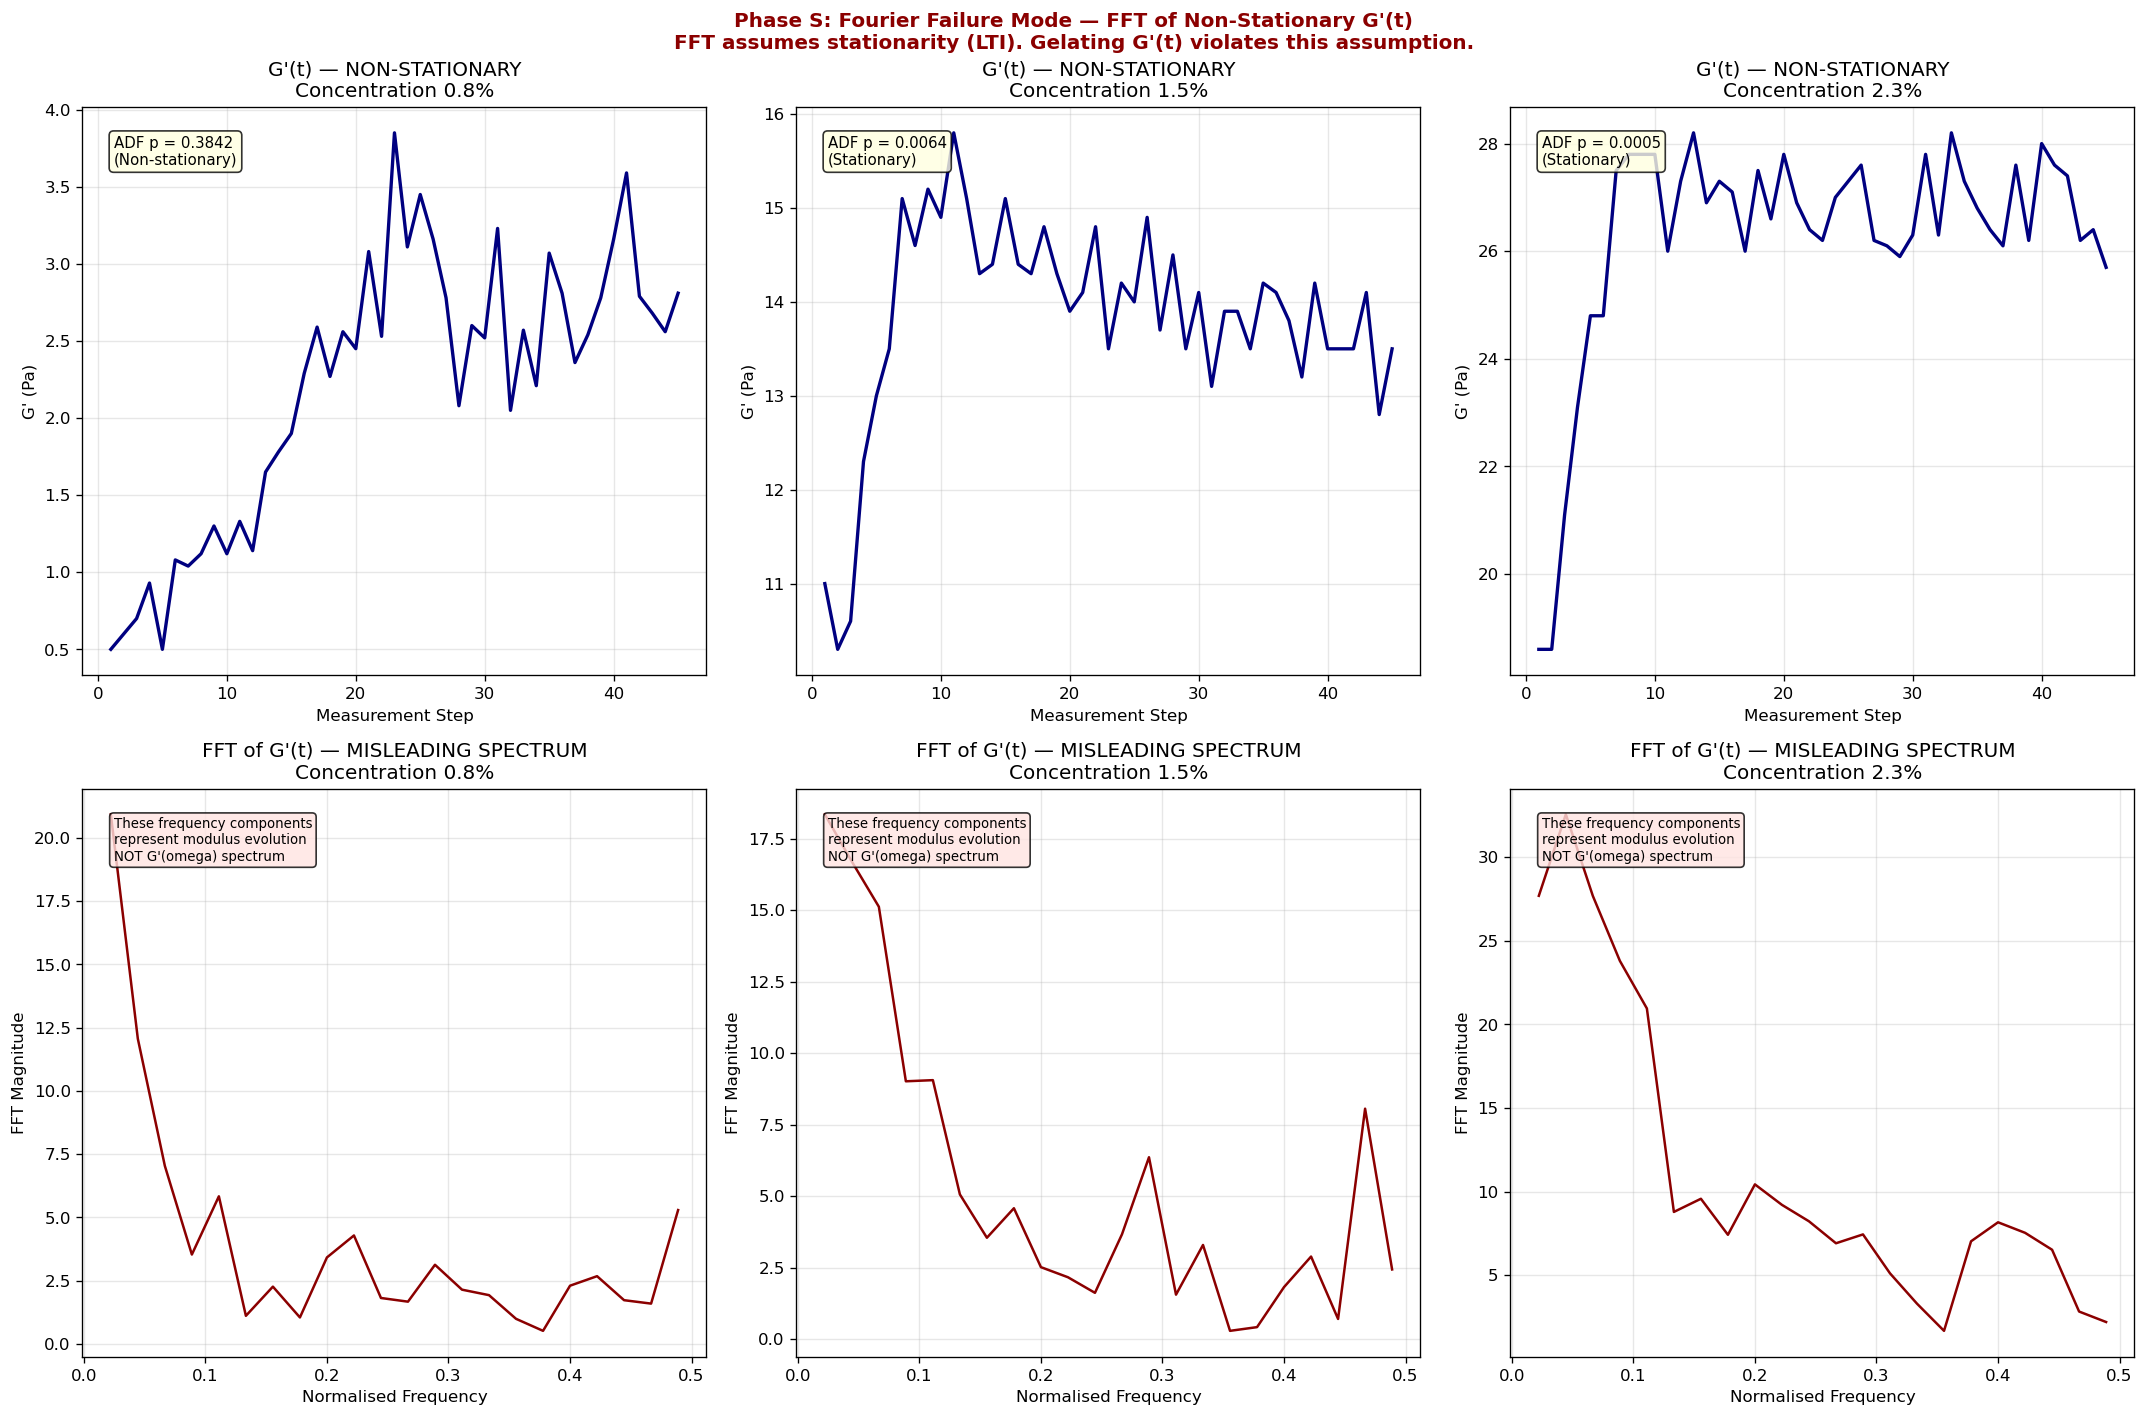

In [50]:
# ==========================================
# CELL S1: Quantitative Demonstration of Fourier Failure
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for column_index, concentration_key in enumerate(sorted(data_dictionary.keys())):
    ax_signal = axes[0, column_index]
    ax_fft    = axes[1, column_index]
    first_replicate_key = sorted(data_dictionary[concentration_key].keys())[0]
    if 'time_sweep' not in data_dictionary[concentration_key][first_replicate_key]:
        continue
    time_sweep_df          = data_dictionary[concentration_key][first_replicate_key]['time_sweep']
    storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
    measurement_steps      = time_sweep_df['meas_pts'].values
    ax_signal.plot(measurement_steps, storage_modulus_values, linewidth=2.0, color='navy')
    ax_signal.set_title(f"G'(t) — NON-STATIONARY\nConcentration {concentration_key}%")
    ax_signal.set_xlabel("Measurement Step")
    ax_signal.set_ylabel("G' (Pa)")
    ax_signal.grid(True, alpha=0.3)
    adf_p_value = adfuller(storage_modulus_values, autolag='AIC')[1]
    stationarity_text = f"ADF p = {adf_p_value:.4f}\n({'Stationary' if adf_p_value < 0.05 else 'Non-stationary'})"
    ax_signal.text(0.05, 0.95, stationarity_text,
                   transform=ax_signal.transAxes, fontsize=9, verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    fft_complex   = np.fft.fft(storage_modulus_values)
    fft_magnitude = np.abs(fft_complex)
    frequency_bins = np.fft.fftfreq(len(storage_modulus_values))
    positive_mask  = frequency_bins > 0
    ax_fft.plot(frequency_bins[positive_mask], fft_magnitude[positive_mask],
                linewidth=1.5, color='darkred')
    ax_fft.set_title(f"FFT of G'(t) — MISLEADING SPECTRUM\nConcentration {concentration_key}%")
    ax_fft.set_xlabel("Normalised Frequency")
    ax_fft.set_ylabel("FFT Magnitude")
    ax_fft.grid(True, alpha=0.3)
    ax_fft.text(0.05, 0.95,
                "These frequency components\nrepresent modulus evolution\nNOT G'(omega) spectrum",
                transform=ax_fft.transAxes, fontsize=8, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='mistyrose', alpha=0.8))

plt.suptitle("Phase S: Fourier Failure Mode — FFT of Non-Stationary G'(t)\n"
             "FFT assumes stationarity (LTI). Gelating G'(t) violates this assumption.",
             fontweight='bold', color='darkred')
plt.tight_layout()
plt.show()

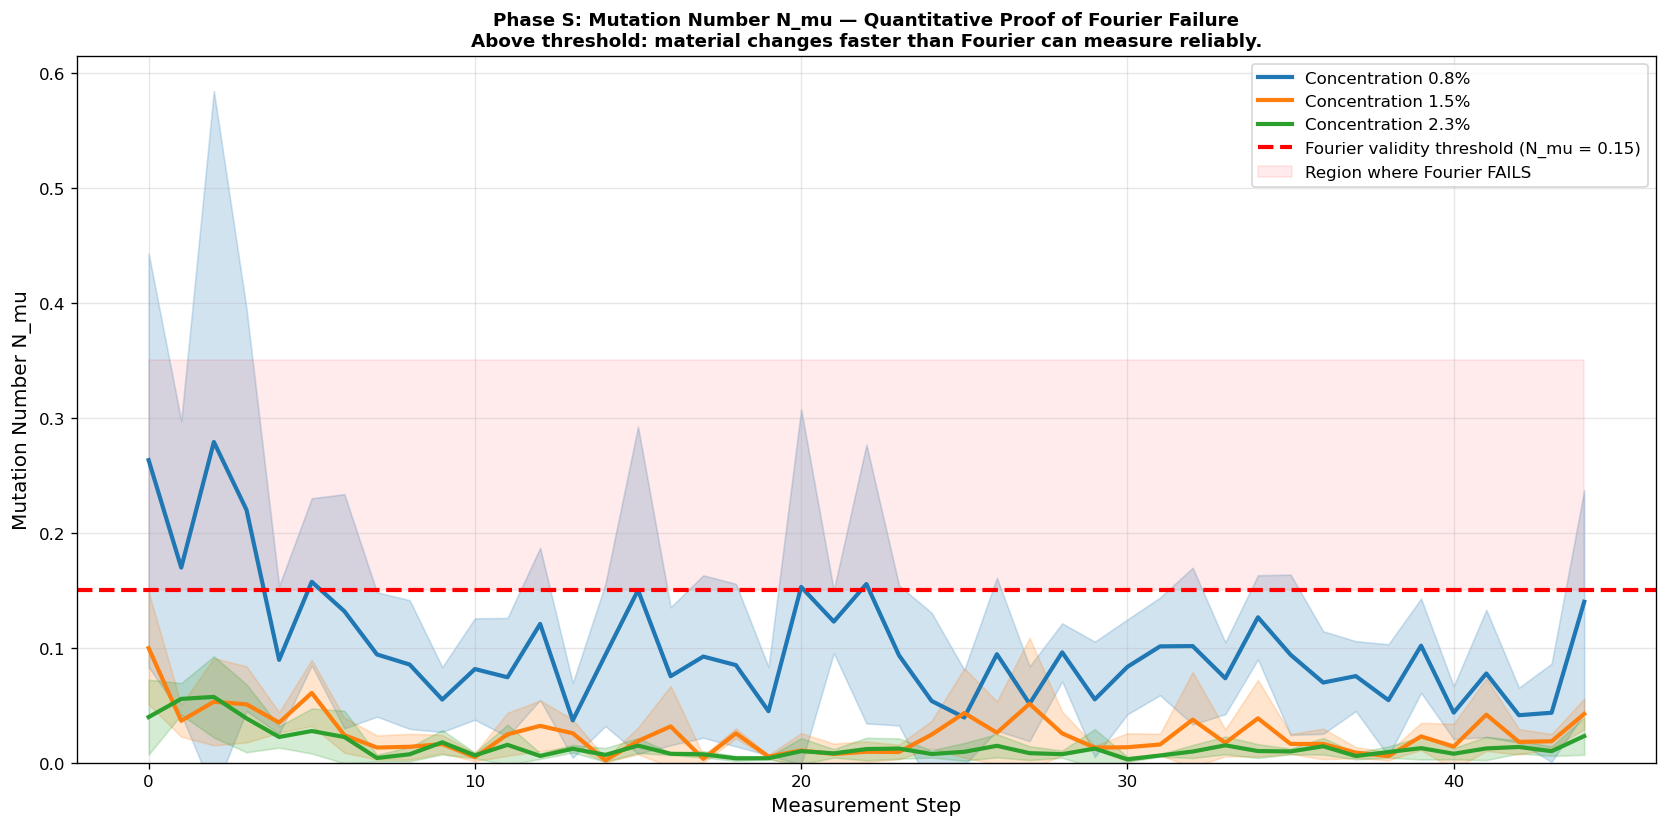

Key insight: When N_mu > 0.15, the material changes significantly during one measurement
period T. Fourier analysis averages over this change and returns a spectrum that does not
correspond to any single physical state of the material. This is the LTI violation.


In [51]:
# ==========================================
# CELL S2: Mutation Number as Quantitative Proof of Fourier Failure
# ==========================================

fig, ax = plt.subplots(figsize=(14, 7))
color_palette = {'0.8': '#1f77b4', '1.5': '#ff7f0e', '2.3': '#2ca02c'}

for concentration_key in sorted(data_dictionary.keys()):
    all_N_mu_per_concentration = []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        time_sweep_df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        storage_modulus_values = time_sweep_df['storage_modulus_Pa'].values
        measurement_steps      = time_sweep_df['meas_pts'].values
        safe_G = np.where(storage_modulus_values < 0.01, 0.01, storage_modulus_values)
        dG_dt  = np.gradient(storage_modulus_values, measurement_steps)
        N_mu   = (MEASUREMENT_PERIOD_SECONDS / safe_G) * np.abs(dG_dt)
        all_N_mu_per_concentration.append(N_mu)
    if all_N_mu_per_concentration:
        N_mu_mean  = np.mean(all_N_mu_per_concentration, axis=0)
        N_mu_std   = np.std(all_N_mu_per_concentration, axis=0)
        step_range = np.arange(len(N_mu_mean))
        ax.plot(step_range, N_mu_mean, color=color_palette[concentration_key],
                linewidth=2.5, label=f"Concentration {concentration_key}%")
        ax.fill_between(step_range,
                        N_mu_mean - N_mu_std,
                        N_mu_mean + N_mu_std,
                        alpha=0.2, color=color_palette[concentration_key])

ax.axhline(y=MUTATION_NUMBER_THRESHOLD, color='red', linestyle='--', linewidth=2.5,
           label=f"Fourier validity threshold (N_mu = {MUTATION_NUMBER_THRESHOLD})")
ax.fill_betweenx([MUTATION_NUMBER_THRESHOLD, 0.35], 0, 44,
                 alpha=0.08, color='red', label="Region where Fourier FAILS")
ax.set_xlabel("Measurement Step", fontsize=12)
ax.set_ylabel("Mutation Number N_mu", fontsize=12)
ax.set_title("Phase S: Mutation Number N_mu — Quantitative Proof of Fourier Failure\n"
             "Above threshold: material changes faster than Fourier can measure reliably.",
             fontweight='bold', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

print("Key insight: When N_mu > 0.15, the material changes significantly during one measurement")
print("period T. Fourier analysis averages over this change and returns a spectrum that does not")
print("correspond to any single physical state of the material. This is the LTI violation.")

## PHASE V — Visualisation System and Master Summary

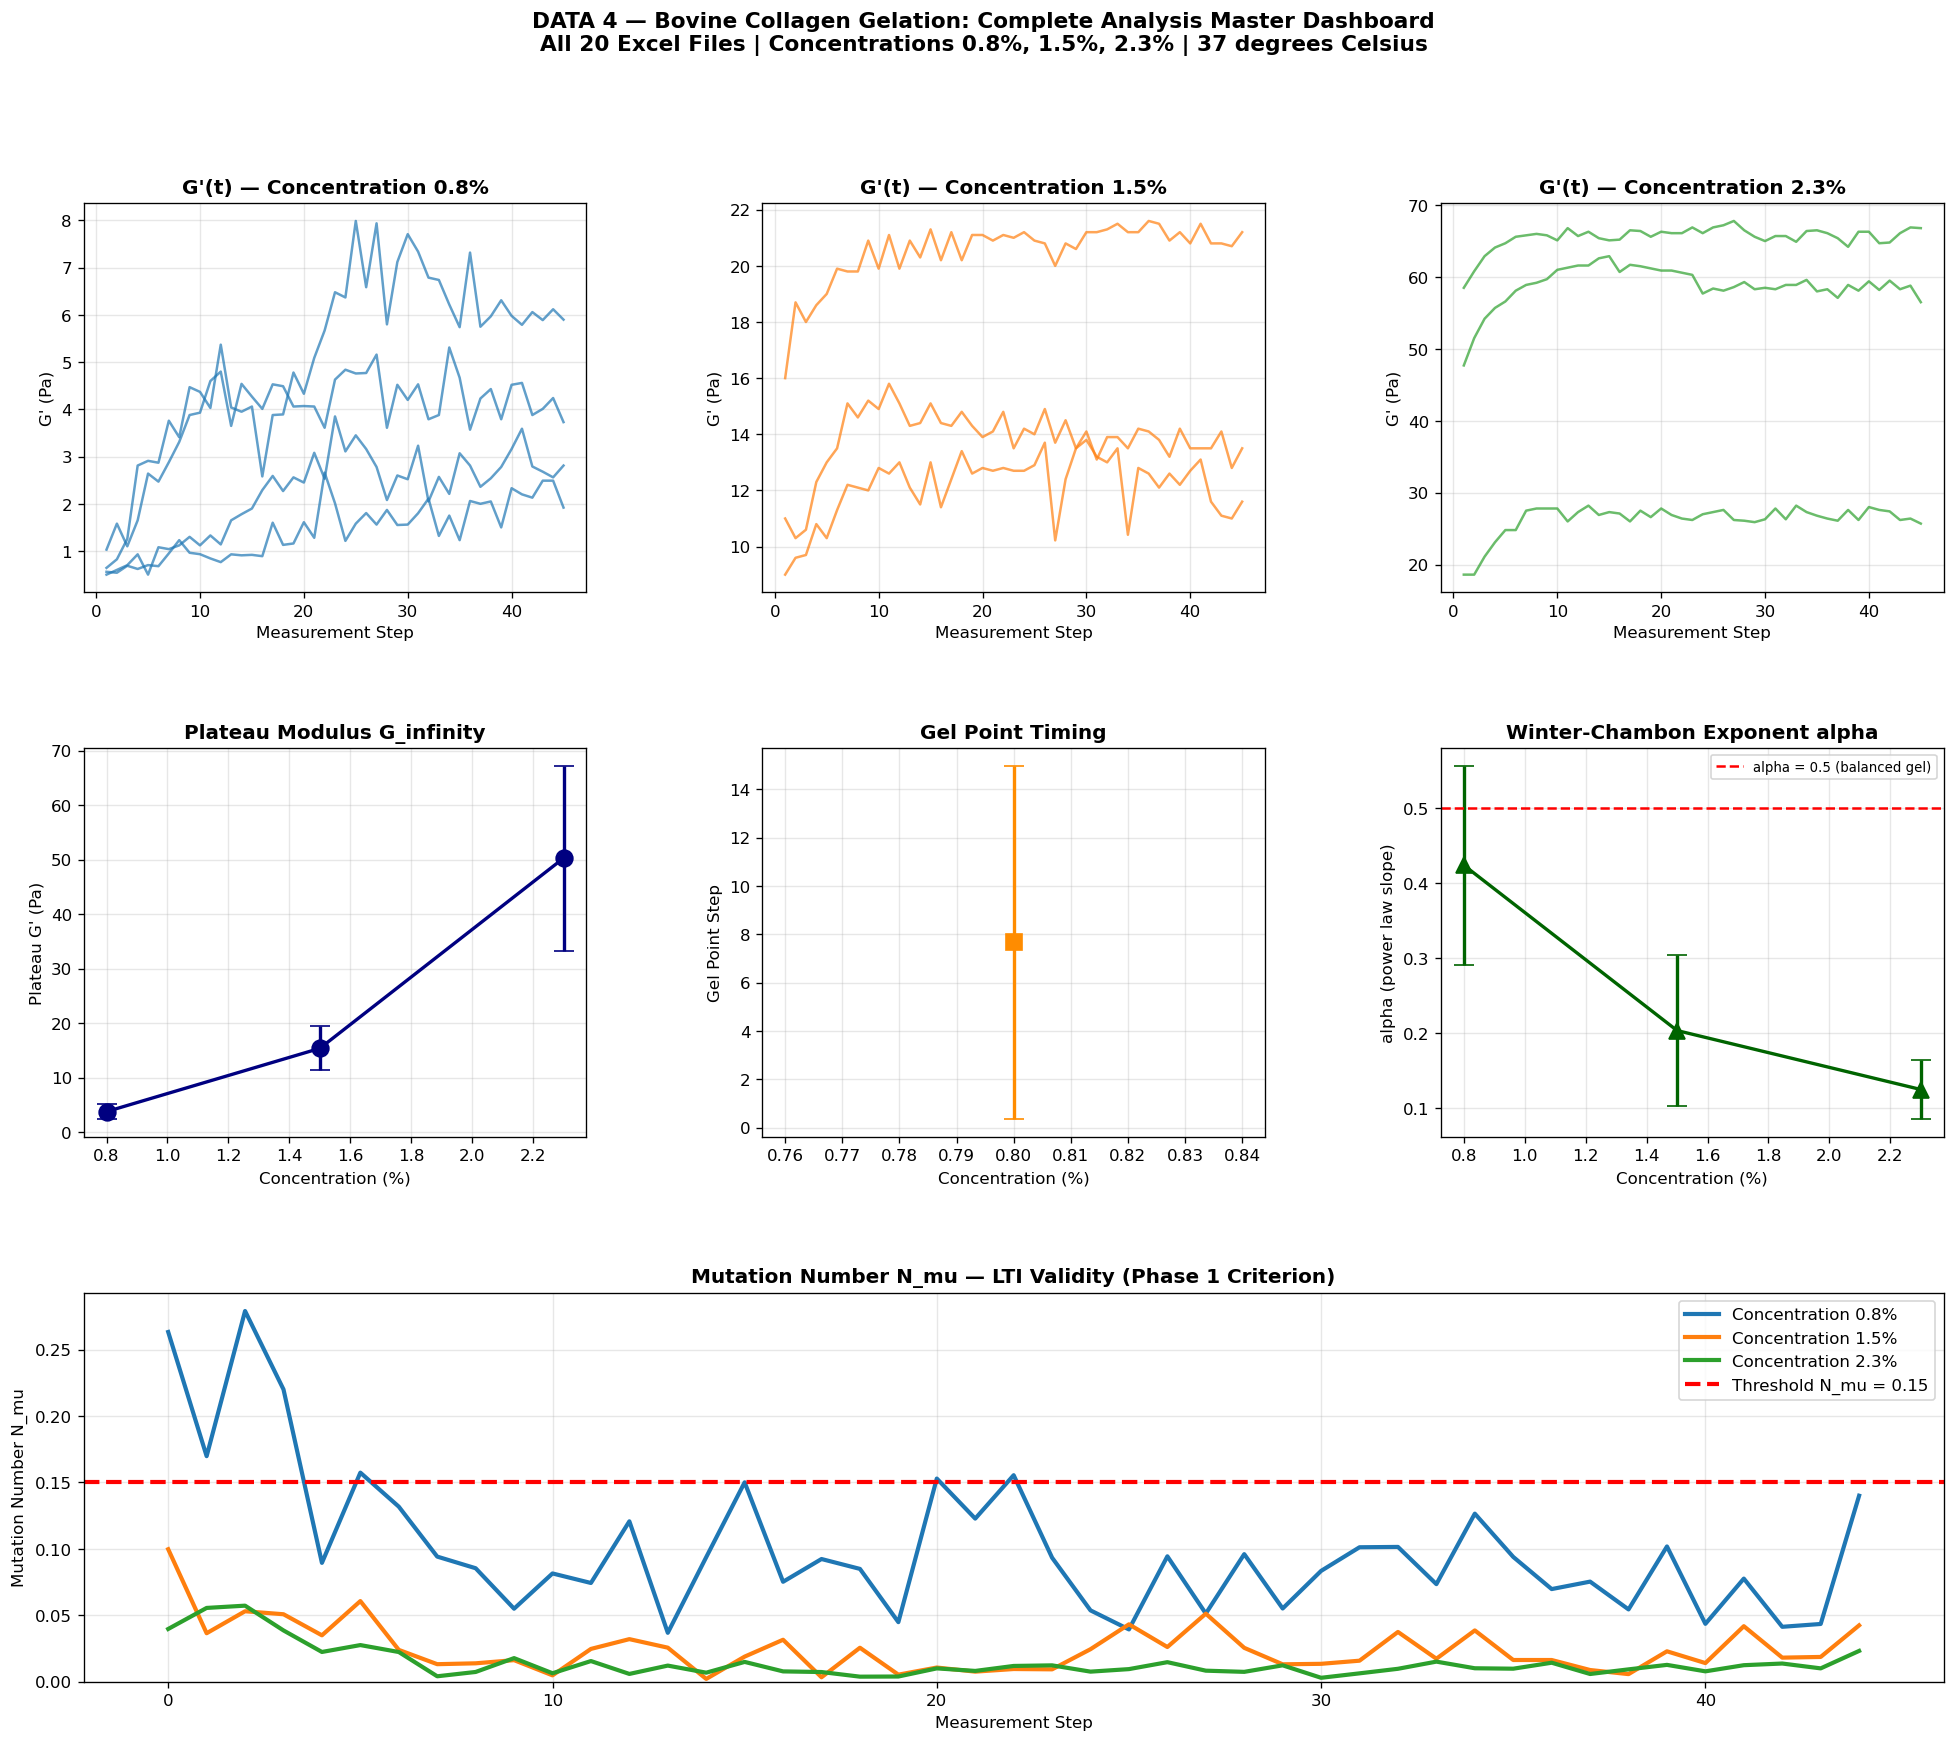

In [52]:
# ==========================================
# CELL V1: Master Summary Dashboard — All Concentrations
# ==========================================

fig = plt.figure(figsize=(20, 16))
grid_spec = gridspec.GridSpec(3, 3, figure=fig, hspace=0.4, wspace=0.35)

concentration_list = sorted(data_dictionary.keys())
color_map = {'0.8': '#1f77b4', '1.5': '#ff7f0e', '2.3': '#2ca02c'}

# Top row: G'(t) for each concentration
for col_idx, concentration_key in enumerate(concentration_list):
    ax_row0 = fig.add_subplot(grid_spec[0, col_idx])
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][replicate_key]:
            continue
        df = data_dictionary[concentration_key][replicate_key]['time_sweep']
        ax_row0.plot(df['meas_pts'].values, df['storage_modulus_Pa'].values,
                     color=color_map[concentration_key], alpha=0.7, linewidth=1.5)
    ax_row0.set_title(f"G'(t) — Concentration {concentration_key}%", fontweight='bold')
    ax_row0.set_xlabel("Measurement Step")
    ax_row0.set_ylabel("G' (Pa)")
    ax_row0.grid(True, alpha=0.3)

# Middle left: Plateau G' vs concentration
ax_mid_left = fig.add_subplot(grid_spec[1, 0])
plateau_mean_list, plateau_std_list = [], []
for concentration_key in concentration_list:
    all_plateau = [
        np.mean(data_dictionary[concentration_key][rep]['time_sweep']['storage_modulus_Pa'].values[-5:])
        for rep in sorted(data_dictionary[concentration_key])
        if 'time_sweep' in data_dictionary[concentration_key][rep]
    ]
    plateau_mean_list.append(np.mean(all_plateau))
    plateau_std_list.append(np.std(all_plateau))
conc_float_list = [float(c) for c in concentration_list]
ax_mid_left.errorbar(conc_float_list, plateau_mean_list, yerr=plateau_std_list,
                     fmt='o-', capsize=6, linewidth=2, markersize=10, color='navy')
ax_mid_left.set_title("Plateau Modulus G_infinity", fontweight='bold')
ax_mid_left.set_xlabel("Concentration (%)")
ax_mid_left.set_ylabel("Plateau G' (Pa)")
ax_mid_left.grid(True, alpha=0.3)

# Middle centre: Gel point step vs concentration
ax_mid_centre = fig.add_subplot(grid_spec[1, 1])
gel_point_mean_list, gel_point_std_list = [], []
for concentration_key in concentration_list:
    gps = []
    for rep in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][rep]: continue
        df = data_dictionary[concentration_key][rep]['time_sweep']
        Gp, Gpp, t = df['storage_modulus_Pa'].values, df['loss_modulus_Pa'].values, df['meas_pts'].values
        diff = Gp - Gpp
        for i in range(1, len(diff)):
            if diff[i-1] < 0 and diff[i] >= 0:
                gps.append(t[i])
                break
    gel_point_mean_list.append(np.mean(gps) if gps else np.nan)
    gel_point_std_list.append(np.std(gps) if gps else np.nan)
ax_mid_centre.errorbar(conc_float_list, gel_point_mean_list, yerr=gel_point_std_list,
                       fmt='s-', capsize=6, linewidth=2, markersize=10, color='darkorange')
ax_mid_centre.set_title("Gel Point Timing", fontweight='bold')
ax_mid_centre.set_xlabel("Concentration (%)")
ax_mid_centre.set_ylabel("Gel Point Step")
ax_mid_centre.grid(True, alpha=0.3)

# Middle right: Winter-Chambon alpha
ax_mid_right = fig.add_subplot(grid_spec[1, 2])
alpha_mean_list, alpha_std_list = [], []
for concentration_key in concentration_list:
    alphas = []
    for rep in sorted(data_dictionary[concentration_key]):
        if 'frequency_sweep' not in data_dictionary[concentration_key][rep]: continue
        df_f = data_dictionary[concentration_key][rep]['frequency_sweep']
        valid = df_f[df_f['storage_modulus_Pa'] > 0]
        if len(valid) >= 3:
            slope, *_ = stats.linregress(np.log(valid['angular_freq_rad_s']),
                                         np.log(valid['storage_modulus_Pa']))
            alphas.append(slope)
    alpha_mean_list.append(np.mean(alphas) if alphas else np.nan)
    alpha_std_list.append(np.std(alphas) if alphas else np.nan)
ax_mid_right.errorbar(conc_float_list, alpha_mean_list, yerr=alpha_std_list,
                      fmt='^-', capsize=6, linewidth=2, markersize=10, color='darkgreen')
ax_mid_right.axhline(y=0.5, color='red', linestyle='--', linewidth=1.5,
                     label="alpha = 0.5 (balanced gel)")
ax_mid_right.set_title("Winter-Chambon Exponent alpha", fontweight='bold')
ax_mid_right.set_xlabel("Concentration (%)")
ax_mid_right.set_ylabel("alpha (power law slope)")
ax_mid_right.legend(fontsize=8)
ax_mid_right.grid(True, alpha=0.3)

# Bottom row: Mutation number mean across all reps per concentration
ax_bottom = fig.add_subplot(grid_spec[2, :])
for concentration_key in concentration_list:
    all_N_mu = []
    for rep in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' not in data_dictionary[concentration_key][rep]: continue
        df = data_dictionary[concentration_key][rep]['time_sweep']
        Gp = df['storage_modulus_Pa'].values
        t  = df['meas_pts'].values
        safe_G = np.where(Gp < 0.01, 0.01, Gp)
        dGdt   = np.gradient(Gp, t)
        all_N_mu.append((MEASUREMENT_PERIOD_SECONDS / safe_G) * np.abs(dGdt))
    if all_N_mu:
        N_mu_mean = np.mean(all_N_mu, axis=0)
        ax_bottom.plot(np.arange(len(N_mu_mean)), N_mu_mean,
                       color=color_map[concentration_key], linewidth=2.5,
                       label=f"Concentration {concentration_key}%")
ax_bottom.axhline(y=MUTATION_NUMBER_THRESHOLD, color='red', linestyle='--',
                  linewidth=2.5, label=f"Threshold N_mu = {MUTATION_NUMBER_THRESHOLD}")
ax_bottom.set_title("Mutation Number N_mu — LTI Validity (Phase 1 Criterion)", fontweight='bold')
ax_bottom.set_xlabel("Measurement Step")
ax_bottom.set_ylabel("Mutation Number N_mu")
ax_bottom.legend(fontsize=10)
ax_bottom.grid(True, alpha=0.3)
ax_bottom.set_ylim(bottom=0)

fig.suptitle("DATA 4 — Bovine Collagen Gelation: Complete Analysis Master Dashboard\n"
             "All 20 Excel Files | Concentrations 0.8%, 1.5%, 2.3% | 37 degrees Celsius",
             fontsize=13, fontweight='bold')
plt.show()

In [53]:
# ==========================================
# CELL V2: Final Comprehensive Summary Table
# ==========================================

print("=" * 90)
print("DATA 4 — BOVINE COLLAGEN GELATION — COMPLETE ANALYSIS SUMMARY")
print("=" * 90)

final_summary_records = []

for concentration_key in sorted(data_dictionary.keys()):
    plateau_list, gel_point_list, rate_list, alpha_list, entropy_list, N_mu_pct_list = [], [], [], [], [], []
    for replicate_key in sorted(data_dictionary[concentration_key]):
        if 'time_sweep' in data_dictionary[concentration_key][replicate_key]:
            df = data_dictionary[concentration_key][replicate_key]['time_sweep']
            Gp  = df['storage_modulus_Pa'].values
            Gpp = df['loss_modulus_Pa'].values
            t   = df['meas_pts'].values
            plateau_list.append(np.mean(Gp[-5:]))
            diff = Gp - Gpp
            for i in range(1, len(diff)):
                if diff[i-1] < 0 and diff[i] >= 0:
                    gel_point_list.append(t[i])
                    break
            rate_list.append(np.max(np.gradient(Gp, t)))
            entropy_list.append(compute_shannon_entropy(Gp))
            safe_G = np.where(Gp < 0.01, 0.01, Gp)
            N_mu   = (MEASUREMENT_PERIOD_SECONDS / safe_G) * np.abs(np.gradient(Gp, t))
            N_mu_pct_list.append(np.mean(N_mu < MUTATION_NUMBER_THRESHOLD) * 100.0)
        if 'frequency_sweep' in data_dictionary[concentration_key][replicate_key]:
            df_f = data_dictionary[concentration_key][replicate_key]['frequency_sweep']
            valid = df_f[df_f['storage_modulus_Pa'] > 0]
            if len(valid) >= 3:
                slope, *_ = stats.linregress(np.log(valid['angular_freq_rad_s']),
                                             np.log(valid['storage_modulus_Pa']))
                alpha_list.append(slope)
    n_reps = len(plateau_list)
    mean_N_mu_pct = np.mean(N_mu_pct_list) if N_mu_pct_list else 0.0
    phase1_status = "PASS" if mean_N_mu_pct >= 80.0 else "FAIL"
    final_summary_records.append({
        'Conc (%)': concentration_key,
        'N Reps': n_reps,
        "Plateau G' (Pa)": f"{np.mean(plateau_list):.2f} +/- {np.std(plateau_list):.2f}",
        'Gel Point': f"{np.mean(gel_point_list):.1f}" if gel_point_list else "Not detected",
        "Max dG'/dt": f"{np.mean(rate_list):.5f}",
        'Alpha': f"{np.mean(alpha_list):.4f}" if alpha_list else "N/A",
        "Entropy G'": f"{np.mean(entropy_list):.4f}",
        'N_mu < 0.15 (%)': f"{mean_N_mu_pct:.1f}%",
        'Phase 1': phase1_status
    })

final_summary_df = pd.DataFrame(final_summary_records)
print(final_summary_df.to_string(index=False))

print("\n" + "=" * 90)
print("KEY PHYSICAL INTERPRETATIONS")
print("=" * 90)
print("Plateau G'  : Higher concentration = stiffer gel (more crosslinks per unit volume).")
print("Gel Point   : Not detectable for 1.5% and 2.3% — gelled before measurement window started.")
print("Alpha       : Decreases with concentration — higher concentration = stronger, stiffer network.")
print("N_mu        : 0.8% marginally fails Phase 1 (78.9%) — rapid early-stage gelation at low conc.")
print("              1.5% and 2.3% pass — already at plateau, G'(t) barely changing.")
print("Entropy G'  : Lower entropy at higher concentrations — more ordered, less variable evolution.")
print()
print("CONCLUSION: Data 4 is suitable as a ground truth benchmark for gel point timing and")
print("Winter-Chambon exponent validation. It cannot drive FFT/STFT/CWT pipeline testing because")
print("raw stress-strain waveforms and sufficient sampling rate (>= 100 Hz) are not available.")
print("Pipeline testing on raw OWCh waveforms requires Data 1, 2, 3, or 6.")

DATA 4 — BOVINE COLLAGEN GELATION — COMPLETE ANALYSIS SUMMARY
Conc (%)  N Reps Plateau G' (Pa)    Gel Point Max dG'/dt  Alpha Entropy G' N_mu < 0.15 (%) Phase 1
     0.8       4   3.79 +/- 1.41          7.7    0.67313 0.4238     3.7911           78.9%    FAIL
     1.5       3  15.39 +/- 4.04 Not detected    1.84667 0.2034     3.2393           99.3%    PASS
     2.3       3 50.26 +/- 16.97 Not detected    2.78333 0.1248     2.1476          100.0%    PASS

KEY PHYSICAL INTERPRETATIONS
Plateau G'  : Higher concentration = stiffer gel (more crosslinks per unit volume).
Gel Point   : Not detectable for 1.5% and 2.3% — gelled before measurement window started.
Alpha       : Decreases with concentration — higher concentration = stronger, stiffer network.
N_mu        : 0.8% marginally fails Phase 1 (78.9%) — rapid early-stage gelation at low conc.
              1.5% and 2.3% pass — already at plateau, G'(t) barely changing.
Entropy G'  : Lower entropy at higher concentrations — more ordered, l